<a href="https://colab.research.google.com/github/ropaniagnes72-jpg/KinesisIQ-affordable-Housing-in-Early_Waring/blob/main/Pod3_KinesisIQ_finalRiipen_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pod 3 — Kinesis: Affordable Rental Stock Depletion & Developer Responsiveness

**City of Toronto Open Data analysis.** Project 2 asks how much affordable rental housing the city is losing and how much is coming; Project 6 asks how quickly developers move from application to permit to completed building, and where applications will be filed next.

| | |
|---|---|
| **Author** | OPANI AGNES|
| **Course / programme** | BDSAL|
| **Supervisor / client** | DR.PEACE $ FABIAN CHERUIYOT|
| **Submission date** | 2026 |
| **Data** | City of Toronto Open Data (CKAN), pulled live at the analysis date printed in Section 0 |
|
## Executive summary

**Project 2 — affordable stock depletion.** Demolition is not the main threat to the affordable rental stock. Over the 2017–2026 window the City recorded roughly 170 rental demolition applications covering a few thousand affordable units, against a protected stock of about 13,000 units and a pipeline of more than 20,000 approved affordable homes. Replacement commitments exceed demolitions, so the *net* position is positive on paper — but replacement is a commitment, not a delivered unit, and completions arrive years later.

The honest finding on forecasting is about **what is forecastable**. Affordable-unit loss at ward level cannot be predicted as a point estimate: most ward-years lose nothing, so "predict zero" is a legitimate forecast and no model beats it on mean absolute error. Loss *is* predictable as a **risk** — the probability that a ward loses units, and a range around how many. The notebook therefore reports a probability and a 10–90% range per ward, and says so explicitly rather than quoting a single number that would be false precision.

**Project 6 — developer responsiveness.** Approval lag, build lag and execution lag measure three different things, and only one of them is mostly the developer's. Build time is long: counting permits that are still under way (rather than only finished ones) raises the apparent median build lag by more than half. The permit-approval model beats a ward-median baseline by about a quarter, and application volume is forecastably seasonal and persistent by ward. Ward-level "typology" clusters are stable enough to describe, not to treat as a validated segmentation of 25 wards.

**Building condition.** Revision 3 called RentSafeTO degradation a stress test on the grounds that nothing linked a low score to a later loss of units. That was an assumption, and it is now tested: buildings that were the subject of a demolition application score measurably lower than survivors (84.8 vs 90.6 on average), and the gap survives controlling for building age and ward exposure. Condition therefore enters the forecast as an estimated multiplier, not an invented rate — though its city-wide effect is small, because the red band is rare.

**Developer response to policy.** Project 6 asks how developers respond to policy shifts. The notebook fits that response as a pooled distributed-lag event study: a response that is statistically visible after the pandemic and the first rate rise, absent after Bill 23, and carries a scenario tool for a hypothetical future shift. It is explicitly not a causal estimate.

**What this means for a reader who only reads one paragraph:** the supply pipeline is large relative to observed demolition, the binding constraint is *time* (build and approval lags measured in years), and ward-level risk should be read as a ranking with wide ranges, not as a point forecast.

### Headline numbers

| Measure | Result |
|---|---|
| Rental demolition applications since 2017 | 173, covering 4,311 affordable units; 4,551 slated for replacement |
| Protected affordable stock (latest quarter) | 13,163 units, city-wide only (the file has no ward detail) |
| Affordable pipeline not yet complete | 21,876 units; about 12,701 expected within 5 years under base assumptions |
| City-wide net affordable flow, 5 years (10th / 50th / 90th pct) | 8,876 / 10,635 / 12,817 units; probability of a city-wide deficit 0% |
| RentSafeTO buildings on the watch list | 468 of 3,679 (12.7%), holding 43,222 units |
| Median permit approval lag (housing permits) | 62 days |
| Median build lag, counting unfinished permits | 955 days (610 days if unfinished permits are ignored — too short) |
| Approval-lag model vs ward-median baseline | 51.5 vs 70.3 days MAE (27% lower error) |
| Application-volume model vs seasonal-naive | 24% lower error |
| Ward typology stability (mean ARI, k=5) | 0.97 ± 0.09 over 500 resamples |

> These are a snapshot of the executed run. If you re-run the notebook the numbers will move slightly (the data is pulled live), and **Section F regenerates them** — Section F is always the source of truth.

## How this notebook is organised

| Section | Project | What it does |
|---|---|---|
| **0** | Both | Settings (every assumption in one place), Open Data helpers, database schema |
| **A** | Both | Reference geography: 25-ward model and 158-neighbourhood model |
| **A.2** | Both | The KinesisIQ events schema, documented column by column for integration |
| **B1–B4** | Project 2 | Demolition and replacement · protected stock · affordable pipeline · RentSafeTO evaluations |
| **B5** | Project 2 | Ward-level depletion table (the reconciliation point for B1–B4) |
| **B6** | Project 2 | Validated net-flow forecast with simulated uncertainty and pipeline scenarios |
| **B7** | Project 2 | RentSafeTO degradation tested as a driver of depletion, not assumed |
| **C7** | Both | Neighbourhood-level localization (158 model) and where it cannot apply |
| **C1–C2** | Project 6 | Development applications · building permits (active + cleared) |
| **C3** | Project 6 | Approval lag, execution lag and build lag (survival estimates for unfinished work) |
| **C3.1** | Project 6 | Exploratory ward regression: do applications and permitted supply move together? |
| **C4** | Project 6 | Supervised models: permit approval lag, and quarterly application volume |
| **C5** | Project 6 | Maps |
| **C6** | Project 6 | Developer response to policy shifts: distributed-lag event study and scenario tool |
| **D** | Both | ETL validation — explicit PASS / WARN / FAIL checks |
| **E** | Both | Unsupervised ward typology (consensus clustering) |
| **F** | Both | Findings (generated by code), limitations, decision log, conclusions |
| **G** | Both | Brief compliance: every requirement, met or out of scope, with the reason |

## How this notebook is;
1. The database `kinesis.db` is written to the working directory, or to Google Drive if Drive is mounted.
## Conventions used throughout

* **Every number in Section F is generated by code**, so that it cannot drift from the outputs.
* **Hand-written narrative cells deliberately avoid run-specific numbers** wherever the point can be made without them. Where a number is unavoidable it is flagged as a snapshot (as in the table above), because a re-run will change it.
* **No invented data.** Where a ward or a date cannot be resolved it is counted and either flagged or dropped — never filled with a default.
* **Every assumption is a named setting in Section 0**, not buried in a cell.
* **Models are judged against simple baselines**, and a model that loses is reported as losing.


## 0. Setup

In [1]:
# importing the libraries to be used here----
import os, re, json, sqlite3, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

try:
    import geopandas as gpd
    HAS_GPD = True
except ImportError:
    HAS_GPD = False
    print("geopandas not installed. In Colab run:  !pip install geopandas  and restart the runtime.\n"
          "Without it, ward assignment falls back to explicit ward fields only and permits stay unmapped.")
try:
    from pyproj import Transformer
    HAS_PYPROJ = True
except ImportError:
    HAS_PYPROJ = False
    print("pyproj not installed (pip install pyproj): projected X/Y coordinates cannot be converted.")

# ==SETTINGS (every assumption lives here) ==
CKAN = "https://ckan0.cf.opendata.inter.prod-toronto.ca"
SEED = 42
AS_OF = pd.Timestamp.today().normalize()      # freeze a run with e.g. pd.Timestamp("2026-11-14")
PANEL_START_YEAR = 2017                        # first year of ward-year panels (demolition data starts 2017)
ANALYSIS_START = pd.Timestamp("2017-01-01")    # permits issued / applications submitted from this date

# --- RentSafeTO (source: City of Toronto RentSafeTO pages; confirm the bands before presenting) ---
RS_RED_BELOW = 70            # score below 70 = red band (green 85-100, yellow 70-84, red 0-69)
RS_DROP_POINTS = 5           # a score drop of 5+ points between evaluations = "degrading"
RS_AUDIT_PERCENTILE = 0.025  # City prioritises the lowest 2.5% of scores each year for audit

# --- Affordable pipeline: share of units delivered, and delivery window in years, by project stage ---
# ASSUMPTION: these are planning assumptions, not estimated from data (the pipeline file has no history).
PIPELINE_ASSUMPTIONS = {
    "completed":          (0.00, 1, 1),   # already built: part of existing stock, not future supply
    "under_construction": (0.95, 1, 3),
    "approved":           (0.70, 2, 5),
    "planning":           (0.40, 3, 7),
    "other":              (0.40, 3, 7),
}
PIPELINE_SCENARIOS = {"low (x0.5)": 0.5, "base (x1.0)": 1.0, "high (x1.25)": 1.25}
STRESS_DEGRADATION_LOSS_RATE = 0.01    # STRESS TEST ONLY: share of at-risk RentSafeTO units lost per year

FORECAST_YEARS = 5
SIMS = 5000
MIN_TRAIN_YEARS = 3                     # first back-test origin needs at least this many training years

# --- Permits ---
MAX_UNITS_PER_PERMIT = 5000             # a single permit above this is treated as a data-entry error
MIN_COST_PER_UNIT = 10_000              # permits with 500+ units but less than this cost per unit are treated as errors
MAX_LAG_DAYS = 3650                     # lags longer than 10 years are treated as date errors
GRID_MIN_N, GRID_MIN_PURITY = 20, 0.90  # WARD_GRID lookup: minimum rows and share agreeing on one ward
USE_ADDRESS_BRIDGE = True

# --- Policy / shock dates for the application-volume model (descriptive flags; verify before presenting) ---
POLICY_EVENTS = {
    "COVID-19 emergency (Ontario)":        "2020-03-17",
    "Bank of Canada first rate rise":      "2022-03-02",
    "Bill 23 royal assent (Ontario)":      "2022-11-28",
}

FIG_DIR = "figures"; OUT_DIR = "outputs"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)

# ---- database location (only use Drive if it is really mounted) ----
DRIVE_DB = "/content/drive/MyDrive/pod3-kinesis/data/processed/kinesis.db"
if os.path.ismount("/content/drive"):
    os.makedirs(os.path.dirname(DRIVE_DB), exist_ok=True)
    db_path = DRIVE_DB
else:
    db_path = "kinesis.db"
    print("Google Drive is not mounted -> using local database:", db_path)
print("Analysis date (AS_OF):", AS_OF.date())

def connect():
    return sqlite3.connect(db_path)

DQ = []         # data-quality log, summarised in Section D
GEO_LOG = []    # spatial-vs-source ward agreement, summarised in Section D

Google Drive is not mounted -> using local database: kinesis.db
Analysis date (AS_OF): 2026-11-22


### 0.1 Open Data helpers
`load_package_tables` reads every row of every tabular resource in a CKAN package, but loads **one copy** of each table. Toronto publishes the same table as a datastore resource, a `.csv` file and sometimes `4326`/`2952` coordinate versions. The earlier notebook loaded all of them and double- or triple-counted rows. Resources that differ only by file type or projection are now collapsed to one, and the helper prints which were skipped.

Some packages also change column spelling between files (`YEAR BUILT` vs `YEAR_BUILT`). `coalesce_columns` merges those so values are not silently lost.

In [2]:
def ckan_get(action, **params):
    r = requests.get(f"{CKAN}/api/3/action/{action}", params=params, timeout=90)
    r.raise_for_status()
    j = r.json()
    if not j.get("success"):
        raise RuntimeError(f"CKAN {action} failed: {j}")
    return j["result"]

def find_package(slug, *search_terms):
    try:
        return ckan_get("package_show", id=slug)
    except Exception:
        pass
    for term in search_terms:
        hits = ckan_get("package_search", q=term, rows=10)["results"]
        if hits:
            print(f"   '{slug}' not found -> using closest match: '{hits[0]['name']}' ({hits[0]['title']})")
            return hits[0]
    raise LookupError(f"No CKAN package found for '{slug}' / {search_terms}")

def _base_name(name):
    n = str(name or "").lower().strip()
    n = re.sub(r"\.(csv|xlsx|xls|json|geojson)$", "", n)
    n = re.sub(r"\s*[-_]\s*(4326|2952|wgs84|mtm\w*)\s*$", "", n)
    return n.strip()

def pick_resources(pkg, name_filter=None):
    """One resource per distinct table: prefer the datastore copy, then WGS84 over projected copies."""
    cands = []
    for r in pkg["resources"]:
        if name_filter and not re.search(name_filter, r.get("name", ""), re.I):
            continue
        fmt = (r.get("format") or "").upper()
        if r.get("datastore_active"):
            src = f"{CKAN}/datastore/dump/{r['id']}"
        elif fmt == "CSV":
            src = r["url"]
        else:
            continue
        projected = 1 if re.search(r"2952|mtm", r.get("name", "") + " " + r.get("url", ""), re.I) else 0
        cands.append((_base_name(r.get("name")), projected, 0 if r.get("datastore_active") else 1, r, src))
    chosen, skipped = {}, []
    for base, proj, notds, r, src in sorted(cands, key=lambda t: (t[0], t[1], t[2])):
        if base in chosen:
            skipped.append(r.get("name"))
        else:
            chosen[base] = (r, src)
    return list(chosen.values()), skipped

def _colkey(c):
    return re.sub(r"[^a-z0-9]+", "", str(c).lower())

def coalesce_columns(df):
    """Merge columns that differ only in spelling (spaces / underscores / case), e.g. 'YEAR BUILT' and 'YEAR_BUILT'."""
    groups = {}
    for c in df.columns:
        if not str(c).startswith("_"):
            groups.setdefault(_colkey(c), []).append(c)
    merged = []
    for cols in groups.values():
        if len(cols) > 1:
            first = cols[0]
            for c in cols[1:]:
                df[first] = df[first].combine_first(df[c])
            df = df.drop(columns=cols[1:])
            merged.append(cols)
    if merged:
        print("   merged differently-spelled columns:", [" + ".join(map(str, g)) for g in merged][:8])
    return df

def load_package_tables(slug, *search_terms, name_filter=None, usecols=None, dedupe=True, row_filter=None):
    """Load one copy of every tabular resource of a package (datastore dump or CSV) and concatenate them.
    `row_filter` is applied to each resource right after it is read, before anything is concatenated,
    so a large table can be trimmed to the analysis window without ever holding all of it in memory."""
    pkg = find_package(slug, *search_terms)
    chosen, skipped = pick_resources(pkg, name_filter)
    frames, loaded = [], []
    for i, (r, src) in enumerate(chosen):
        kw = {"low_memory": False}
        if usecols is not None:
            kw["usecols"] = usecols if callable(usecols) else (lambda c, s=set(usecols): c in s)
        try:
            df = pd.read_csv(src, **kw)
            if row_filter is not None:
                df = row_filter(df)
        except Exception as e:
            print(f"   skipped resource '{r.get('name')}': {type(e).__name__}: {str(e)[:100]}")
            continue
        ids = df["_id"] if "_id" in df.columns else df.index
        df["_uid"] = [f"{i}-{v}" for v in ids]
        df["_resource"] = r.get("name")
        frames.append(df)
        loaded.append(f"{r.get('name')} ({len(df):,} rows)")
    if not frames:
        raise RuntimeError(f"No loadable tabular resource in package '{pkg['name']}'")
    out = coalesce_columns(pd.concat(frames, ignore_index=True))
    n0 = len(out)
    if dedupe:
        content = [c for c in out.columns if c not in ("_id", "_uid", "_resource")]
        out = out.drop_duplicates(subset=content, keep="first").reset_index(drop=True)
    print(f"Loaded '{pkg['title']}' [{pkg['name']}]: {len(out):,} rows, {out.shape[1]} cols"
          + (f"  (removed {n0 - len(out):,} exact duplicate rows)" if n0 != len(out) else ""))
    for l in loaded:
        print("   - loaded:", l)
    for s in skipped:
        print("   - skipped duplicate copy of an already-loaded table:", s)
    return out

def load_geo(slug, *search_terms):
    """Load a GeoJSON resource (EPSG:4326 preferred) as a GeoDataFrame."""
    pkg = find_package(slug, *search_terms)
    res = [r for r in pkg["resources"] if (r.get("format") or "").upper() == "GEOJSON"]
    pref = [r for r in res if "4326" in r.get("name", "") or "4326" in r.get("url", "")]
    r = (pref or res)[0]
    g = gpd.read_file(r["url"])
    if g.crs is None:
        g = g.set_crs(4326)
    return g.to_crs(4326)

# ---------------- parsing helpers ----------------
def pick_col(df, *patterns, override=None):
    """First column matching the first matching regex (in priority order). Spaces, underscores and case are interchangeable."""
    if override:
        return override
    for p in patterns:
        for c in df.columns:
            name = str(c)
            if name.startswith("_"):
                continue
            if (re.search(p, name, re.I) or re.search(p, re.sub(r"[^A-Za-z0-9]+", "_", name), re.I)
                    or re.search(p, re.sub(r"[^A-Za-z0-9]+", " ", name), re.I)):
                return c
    return None

def detect(raw, ov, spec):
    m = {k: pick_col(raw, *pats, override=ov.get(k)) for k, pats in spec.items()}
    print("Detected columns:", m)
    return m

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[,$\s]", "", regex=True), errors="coerce")

def to_dt(s):
    if pd.api.types.is_numeric_dtype(s) and s.dropna().size and s.dropna().median() > 1e11:      # epoch milliseconds
        d = pd.to_datetime(s, unit="ms", errors="coerce")
    else:
        try:
            d = pd.to_datetime(s, errors="coerce", format="mixed")
        except (TypeError, ValueError):
            d = pd.to_datetime(s, errors="coerce")
    return d

def sane_dates(d, lo="1990-01-01", hi_years_ahead=1):
    """Dates outside [1990, AS_OF + 1 year] are data errors -> NaT (counted by the caller, never defaulted)."""
    hi = AS_OF + pd.DateOffset(years=hi_years_ahead)
    return d.where((d >= pd.Timestamp(lo)) & (d <= hi))

def disp(df, n=None, digits=2):
    d = df if n is None else df.head(n)
    try:
        display(d.round(digits))
    except NameError:
        print(d.round(digits).to_string())

show = lambda df, n=3: disp(df, n)

def finish_plot(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---------------- coordinates ----------------
def lonlat_from_geometry(s):
    """GeoJSON point strings -> (lat, lon). Several Toronto tables ship coordinates only in a `geometry` text column."""
    lon = np.full(len(s), np.nan); lat = np.full(len(s), np.nan)
    for i, v in enumerate(s.to_numpy(dtype=object)):
        if isinstance(v, str) and v[:1] == "{":
            try:
                g = json.loads(v)
            except ValueError:
                continue
            c, t = g.get("coordinates"), g.get("type")
            if t == "MultiPoint" and c:
                c = c[0]
            if t in ("Point", "MultiPoint") and c and len(c) >= 2:
                lon[i], lat[i] = c[0], c[1]
    return pd.Series(lat, index=s.index), pd.Series(lon, index=s.index)

XY_CRS_CANDIDATES = ["EPSG:2952", "EPSG:2019", "EPSG:26917"]   # Toronto MTM zone 10 variants, UTM 17N

def lonlat_from_xy(x, y):
    """Projected X/Y -> (lat, lon). The CRS is chosen by testing which candidate puts the points inside Toronto."""
    x, y = to_num(x), to_num(y)
    nan = pd.Series(np.nan, index=x.index)
    if not HAS_PYPROJ:
        print("   X/Y present but pyproj is not installed -> not converted")
        return nan, nan
    ok = x.notna() & y.notna() & (x > 0) & (y > 0)
    if not ok.any():
        return nan, nan
    samp = ok[ok].index[:5000]
    best = None
    for crs in XY_CRS_CANDIDATES:
        tr = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
        lo, la = tr.transform(x[samp].to_numpy(), y[samp].to_numpy())
        share = float(((np.asarray(la) > 43.4) & (np.asarray(la) < 44.0) & (np.asarray(lo) > -79.8) & (np.asarray(lo) < -78.9)).mean())
        if best is None or share > best[0]:
            best = (share, crs)
    if best[0] < 0.95:
        print(f"   X/Y could not be matched to a known Toronto CRS (best {best[1]}: {best[0]:.0%} inside Toronto) -> not converted")
        return nan, nan
    tr = Transformer.from_crs(best[1], "EPSG:4326", always_xy=True)
    lo, la = tr.transform(x[ok].to_numpy(), y[ok].to_numpy())
    lat, lon = nan.copy(), nan.copy()
    lat[ok], lon[ok] = la, lo
    print(f"   X/Y converted from {best[1]} ({best[0]:.0%} of sampled points fall inside Toronto)")
    return lat, lon

def add_coords(df, lat_col=None, lon_col=None, geom_col=None, x_col=None, y_col=None):
    """Adds `_lat`/`_lon` (WGS84) from the first source that works: lat/lon columns, GeoJSON geometry text, or projected X/Y."""
    lat = pd.Series(np.nan, index=df.index); lon = lat.copy(); used = []
    def fill(la, lo, label):
        nonlocal lat, lon
        good = la.between(43.4, 44.0) & lo.between(-79.8, -78.9) & lat.isna()
        if good.any():
            lat = lat.where(~good, la); lon = lon.where(~good, lo); used.append(f"{label}:{int(good.sum()):,}")
    if lat_col and lon_col:
        fill(to_num(df[lat_col]), to_num(df[lon_col]), "lat/lon")
    if geom_col and geom_col in df.columns:
        fill(*lonlat_from_geometry(df[geom_col]), "geometry")
    if x_col and y_col and x_col in df.columns and y_col in df.columns and lat.isna().any():
        fill(*lonlat_from_xy(df[x_col], df[y_col]), "X/Y")
    print("   coordinates:", ", ".join(used) if used else "none usable", f"-> {lat.notna().mean():.1%} of rows have a point")
    return df.assign(_lat=lat, _lon=lon)

## A. Reference geography — City Wards (25-ward model) and Neighbourhoods (158 model)
These two layers are the only geography used in the notebook. Ward IDs 1–25 follow the 25-ward model that took effect in 2018.

In [3]:
WARDS = [
    (1, "Etobicoke North"), (2, "Etobicoke Centre"), (3, "Etobicoke-Lakeshore"), (4, "Parkdale-High Park"),
    (5, "York South-Weston"), (6, "York Centre"), (7, "Humber River-Black Creek"), (8, "Eglinton-Lawrence"),
    (9, "Davenport"), (10, "Spadina-Fort York"), (11, "University-Rosedale"), (12, "Toronto-St. Paul's"),
    (13, "Toronto Centre"), (14, "Toronto-Danforth"), (15, "Don Valley West"), (16, "Don Valley East"),
    (17, "Don Valley North"), (18, "Willowdale"), (19, "Beaches-East York"), (20, "Scarborough Southwest"),
    (21, "Scarborough Centre"), (22, "Scarborough-Agincourt"), (23, "Scarborough North"),
    (24, "Scarborough-Guildwood"), (25, "Scarborough-Rouge Park"),
]
WARD_NAME = dict(WARDS)

def _norm(s):
    return re.sub(r"[^a-z0-9]+", " ", str(s).lower()).strip()

WARD_NAME_TO_ID = {_norm(n): i for i, n in WARDS}

def ward_from_value(v):
    """Strict 25-ward resolver: a number 1-25 (13, '13', 'Ward 13', 'Toronto Centre (13)') or an exact ward name."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    s = str(v).strip()
    m = re.fullmatch(r"(?:ward\s*)?0*(\d{1,2})(?:\.0+)?", s, re.I) or re.search(r"\(\s*0*(\d{1,2})\s*\)", s)
    if m and 1 <= int(m.group(1)) <= 25:
        return int(m.group(1))
    return WARD_NAME_TO_ID.get(_norm(re.sub(r"\(.*?\)", "", s)))

wards_gdf = None
nbhd_gdf = None
nbhd_table = pd.DataFrame(columns=["neighbourhood_id", "neighbourhood_name"])

if HAS_GPD:
    # --- City Wards (25-ward model) ---
    try:
        g = load_geo("city-wards", "city wards")
        code_col = pick_col(g, r"^AREA_SHORT_CODE$", r"^AREA_LONG_CODE$", r"WARD.*(NUM|ID|CODE)")
        g["ward_id"] = pd.to_numeric(g[code_col].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
        g = g[g["ward_id"].between(1, 25)]
        assert g["ward_id"].nunique() == 25, f"expected 25 wards, found {g['ward_id'].nunique()} - is this the 25-ward model?"
        g["ward_id"] = g["ward_id"].astype(int)
        wards_gdf = g[["ward_id", "geometry"]].copy()
        name_col = pick_col(g, r"^AREA_NAME$", r"WARD.*NAME")
        if name_col:
            geo_names = {int(r.ward_id): _norm(re.sub(r"\(.*?\)", "", str(r[name_col]))) for _, r in g.iterrows()}
            bad = [i for i, n in WARDS if geo_names.get(i) != _norm(n)]
            print("Ward geometry loaded (25). Name mismatches vs dim_ward:", bad or "none")
    except Exception as e:
        print("Could not load City Wards geometry:", type(e).__name__, e)

    # --- Neighbourhoods (158 model) ---
    try:
        g = load_geo("neighbourhoods", "neighbourhoods")
        code_col = pick_col(g, r"^AREA_SHORT_CODE$", r"^AREA_LONG_CODE$", r"NEIGHBOURHOOD.*(ID|NUM|CODE)")
        name_col = pick_col(g, r"^AREA_NAME$", r"NEIGHBOURHOOD.*NAME")
        g["neighbourhood_id"] = pd.to_numeric(g[code_col].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
        g = g.dropna(subset=["neighbourhood_id"])
        g["neighbourhood_id"] = g["neighbourhood_id"].astype(int)
        g["neighbourhood_name"] = g[name_col].astype(str).str.replace(r"\s*\(\d+\)\s*$", "", regex=True)
        if g["neighbourhood_id"].nunique() != 158:
            print(f"WARNING: {g['neighbourhood_id'].nunique()} neighbourhoods found, outline expects the 158 model - check the package.")
        nbhd_gdf = g[["neighbourhood_id", "neighbourhood_name", "geometry"]].copy()
        nbhd_table = nbhd_gdf[["neighbourhood_id", "neighbourhood_name"]].drop_duplicates()
        print(f"Neighbourhood geometry loaded ({len(nbhd_table)}).")
    except Exception as e:
        print("Could not load Neighbourhood geometry:", type(e).__name__, e)

# ---- geography assignment ----
def assign_geography(df, lat_col, lon_col):
    """Point-in-polygon: adds ward_id_sp / neighbourhood_id_sp (NaN where no usable coordinates)."""
    out = df.copy()
    out["ward_id_sp"] = np.nan
    out["neighbourhood_id_sp"] = np.nan
    if not HAS_GPD or wards_gdf is None or lat_col not in out or lon_col not in out:
        return out
    lat, lon = pd.to_numeric(out[lat_col], errors="coerce"), pd.to_numeric(out[lon_col], errors="coerce")
    ok = lat.between(43.4, 44.0) & lon.between(-79.8, -78.9)          # Toronto bounding box sanity check
    if not ok.any():
        print(f"   no usable WGS84 coordinates in {lat_col}/{lon_col} - spatial join skipped")
        return out
    pts = gpd.GeoDataFrame({"_i": out.index[ok]}, geometry=gpd.points_from_xy(lon[ok], lat[ok]), crs="EPSG:4326")
    for gdf, idcol, outcol in ((wards_gdf, "ward_id", "ward_id_sp"), (nbhd_gdf, "neighbourhood_id", "neighbourhood_id_sp")):
        if gdf is None:
            continue
        j = gpd.sjoin(pts, gdf[[idcol, "geometry"]], how="left", predicate="within")
        j = j[~j.index.duplicated(keep="first")]
        out.loc[j["_i"].values, outcol] = j[idcol].values
    return out

def finalize_geo(df, ward_col=None, lat_col=None, lon_col=None, label=""):
    """Adds ward_id, neighbourhood_id, geo_method. Priority: spatial join > explicit ward field > unmapped (never guessed)."""
    out = assign_geography(df, lat_col, lon_col) if lat_col and lon_col else df.assign(ward_id_sp=np.nan, neighbourhood_id_sp=np.nan)
    src = out[ward_col].map(ward_from_value) if ward_col else pd.Series(np.nan, index=out.index)
    src = pd.to_numeric(src, errors="coerce")
    both = out["ward_id_sp"].notna() & src.notna()
    if both.any():
        agree = float((out.loc[both, "ward_id_sp"] == src[both]).mean())
        print(f"   spatial vs source-ward agreement: {agree:.1%} on {both.sum():,} rows")
        GEO_LOG.append({"dataset": label, "rows_compared": int(both.sum()), "agreement": agree})
    ward = out["ward_id_sp"].where(out["ward_id_sp"].notna(), src)
    out["geo_method"] = np.where(out["ward_id_sp"].notna(), "spatial_join",
                         np.where(src.notna(), "source_ward_field", "unmapped"))
    out["ward_id"] = pd.to_numeric(ward, errors="coerce").astype("Int64")
    out["neighbourhood_id"] = pd.to_numeric(out["neighbourhood_id_sp"], errors="coerce").astype("Int64")
    return out.drop(columns=["ward_id_sp", "neighbourhood_id_sp"])

/usr/local/lib/python3.13/dist-packages/geopandas/io/file.py:582: UserWarning: Error parsing datetimes, original strings are returned: Out of bounds nanosecond timestamp: 3000-01-01T00:00:00, at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Ward geometry loaded (25). Name mismatches vs dim_ward: none
Neighbourhood geometry loaded (158).


### A.1 Database schema

Two dimension tables (`dim_ward`, `dim_neighbourhood`) and one event fact (`kinesis_events`). The event table declares the 12 columns of the KinesisIQ events schema plus two added by `ALTER TABLE` when an existing database is opened — `units_lost` and `geo_method` — for 14 in total. Statements are `CREATE TABLE IF NOT EXISTS`, so the notebook can be pointed at an existing database without losing it.

`geo_method` records how each event got its ward (`spatial_join`, `source_ward_field`, `ward_grid_lookup` or `unmapped`), so the geography in any later result can be audited. Rows are written with `INSERT OR REPLACE` on a deterministic `event_id`, which means re-running the notebook overwrites a source's rows rather than appending duplicates — the check in Section D confirms rows written equals rows stored.


In [4]:
conn = connect()
cur = conn.cursor()
cur.execute("""CREATE TABLE IF NOT EXISTS dim_ward (
    ward_id INTEGER PRIMARY KEY, ward_name VARCHAR(100) NOT NULL, ward_code VARCHAR(20) UNIQUE NOT NULL)""")
cur.execute("""CREATE TABLE IF NOT EXISTS dim_neighbourhood (
    neighbourhood_id INTEGER PRIMARY KEY, neighbourhood_name VARCHAR(150) NOT NULL)""")
cur.execute("""CREATE TABLE IF NOT EXISTS kinesis_events (
    event_id VARCHAR(60) PRIMARY KEY,
    event_type VARCHAR(50) NOT NULL,
    event_date DATE NOT NULL,
    event_year INTEGER NOT NULL,
    event_quarter INTEGER,
    ward_id INTEGER REFERENCES dim_ward(ward_id),
    neighbourhood_id INTEGER REFERENCES dim_neighbourhood(neighbourhood_id),
    address TEXT,
    units_affected INTEGER DEFAULT 0,
    units_affordable INTEGER DEFAULT 0,
    source_dataset VARCHAR(100) NOT NULL,
    data_quality_flag VARCHAR(30) DEFAULT 'clean')""")

existing = {r[1] for r in cur.execute("PRAGMA table_info(kinesis_events)")}
for col, ddl in (("units_lost", "INTEGER DEFAULT 0"), ("geo_method", "VARCHAR(30)")):
    if col not in existing:
        cur.execute(f"ALTER TABLE kinesis_events ADD COLUMN {col} {ddl}")

cur.executemany("INSERT OR REPLACE INTO dim_ward VALUES (?,?,?)", [(i, n, f"WARD_{i:02d}") for i, n in WARDS])
if len(nbhd_table):
    cur.executemany("INSERT OR REPLACE INTO dim_neighbourhood VALUES (?,?)",
                    [(int(r.neighbourhood_id), r.neighbourhood_name) for r in nbhd_table.itertuples()])
conn.commit()
conn.close()

EVENT_COLS = ["event_id", "event_type", "event_date", "event_year", "event_quarter", "ward_id", "neighbourhood_id",
              "address", "units_affected", "units_affordable", "source_dataset", "data_quality_flag",
              "units_lost", "geo_method"]

GEO_FLAG = {"spatial_join": "clean", "source_ward_field": "clean",
            "ward_grid_lookup": "ward_grid_inferred", "unmapped": "unmapped_ward"}

def make_events(df, uid_col, prefix, event_type, dates, source, address=None, units=None, affordable=None, lost=None, flag=None):
    """Standardised event rows. Rows without a real date are dropped (and counted), not given a default date."""
    d = pd.Series(dates, index=df.index)
    keep = d.notna()
    z = pd.Series(0, index=df.index)
    dq = df["geo_method"].map(GEO_FLAG)
    if flag is not None:                       # a row-level problem (e.g. outlier units) overrides the geography flag
        dq = dq.where(flag.isna(), flag)
    ev = pd.DataFrame({
        "event_id": prefix + df[uid_col].astype(str),
        "event_type": event_type,
        "event_date": d.dt.strftime("%Y-%m-%d"),
        "event_year": d.dt.year,
        "event_quarter": d.dt.quarter,
        "ward_id": df["ward_id"],
        "neighbourhood_id": df["neighbourhood_id"],
        "address": df[address].astype(str).str.strip() if address else None,
        "units_affected": (units if units is not None else z).fillna(0).astype(int),
        "units_affordable": (affordable if affordable is not None else z).fillna(0).astype(int),
        "source_dataset": source,
        "data_quality_flag": dq,
        "units_lost": (lost if lost is not None else z).fillna(0).astype(int),
        "geo_method": df["geo_method"],
    })[keep]
    return ev[EVENT_COLS]

def write_events(ev, sources):
    """Idempotent load: replace every row of the given source datasets."""
    conn = connect()
    ph = ",".join("?" * len(sources))
    conn.execute(f"DELETE FROM kinesis_events WHERE source_dataset IN ({ph})", list(sources))
    rows = ev.astype(object).where(ev.notna(), None).values.tolist()
    conn.executemany(f"INSERT OR REPLACE INTO kinesis_events ({','.join(EVENT_COLS)}) VALUES ({','.join('?' * len(EVENT_COLS))})", rows)
    conn.commit()
    conn.close()

def write_table(df, name):
    conn = connect()
    df.to_sql(name, conn, if_exists="replace", index=False)
    conn.close()

def log_dq(dataset, loaded, events, geo=None, note=""):
    unm = float((geo["geo_method"] == "unmapped").mean()) if geo is not None and len(geo) else np.nan
    DQ.append({"dataset": dataset, "rows_loaded": loaded, "events_written": events, "pct_ward_unmapped": unm, "note": note})

def by_ward(df, **aggs):
    d = df.dropna(subset=["ward_id"]).copy()
    d["ward_id"] = d["ward_id"].astype(int)
    return d.groupby("ward_id").agg(**aggs).reindex(range(1, 26))

print("Schema ready:", db_path)

Schema ready: kinesis.db


### A.2 KinesisIQ events schema — documented for integration

The brief requires the ETL to map every open dataset to a **documented KinesisIQ events table schema**, and every engineered feature and event measure to be defined **abstractly**, so the KinesisIQ engineering team can lift the localized measures into the production repository. This subsection is that specification; the measure catalogue in Section F is the companion.

**The event fact — `kinesis_events`.** One row per real-world event (a demolition application, a development application, a permit). Every column, its type, its key role and its meaning are listed in `dim_event_schema` below, and the controlled vocabulary of `event_type` values is in `dim_event_type`. The point of the design is that a new source is onboarded by adding rows to those two tables plus one loader call — no schema change, no new join logic.

| Design rule | Why |
|---|---|
| `event_id` is a deterministic `<PREFIX>_<source row id>` | Re-running the ETL rewrites a source's rows instead of appending duplicates; the Section D check confirms rows written equals rows stored. |
| `event_date` is `NOT NULL`; undated rows are dropped and counted | A defaulted date would silently invent an event in the wrong period. |
| `ward_id` / `neighbourhood_id` are nullable and never guessed | Unmapped geography is `NULL` with `geo_method = 'unmapped'`, so any later result can be audited and an unmapped rate can be reported. |
| `geo_method` records *how* the geography was obtained | `spatial_join` > `source_ward_field` > `ward_grid_lookup` > `unmapped`, in that priority order. |
| `units_affordable` is defined by the **source**, not harmonised | The demolition file's "affordable" (existing market-rate affordable) and the pipeline's (new below-market) are different things and are never summed. |
| `address` holds a building/site address only | No unit number, no person, no representative — the PII rule in the brief. |
| `source_dataset` is the load partition key | Enables idempotent reloads and per-source row reconciliation. |

**What is in scope for Pod 3.** Four event types are loaded — the two datasets Project 2 needs (demolition and replacement; the affordable pipeline and protected stock, which are snapshots rather than event streams and therefore live in fact tables) and the two Project 6 needs (development applications; building permits). The provincial LTB Order Catalogue, Property Standards 311 requests, MLS Investigation Activity, shelter occupancy and the Centralized Waiting List belong to other streams (Projects 1, 3, 4, 5, 7, 8) and are **not** ingested here; they are named in the compliance table in the accompanying review report, with the reason.

In [5]:
# ---- A.2: the schema itself, as data, so the engineering team can read it from the database ----
EVENT_SCHEMA_SPEC = [
    ("event_id",          "VARCHAR(60)",  "PK",  "Deterministic '<PREFIX>_<source row id>'. Makes the load idempotent."),
    ("event_type",        "VARCHAR(50)",  "FK",  "Controlled vocabulary; see dim_event_type."),
    ("event_date",        "DATE",         "NOT NULL", "Date the event happened (permit issued, application submitted). Never defaulted."),
    ("event_year",        "INTEGER",      "derived", "Year of event_date; denormalised for fast ward-year aggregation."),
    ("event_quarter",     "INTEGER",      "derived", "Quarter of event_date (1-4)."),
    ("ward_id",           "INTEGER",      "FK",  "25-ward model, 1-25. NULL when unmapped; never guessed."),
    ("neighbourhood_id",  "INTEGER",      "FK",  "158-neighbourhood model. NULL when unmapped."),
    ("address",           "TEXT",         "PII-safe", "Building/site address only. No unit number, no person, no representative."),
    ("units_affected",    "INTEGER",      "measure", "Total dwelling units the event touches (created, demolished, proposed)."),
    ("units_affordable",  "INTEGER",      "measure", "Affordable units, as the SOURCE defines affordable. Not harmonised across sources."),
    ("source_dataset",    "VARCHAR(100)","partition", "Load partition key; enables idempotent reload and per-source reconciliation."),
    ("data_quality_flag", "VARCHAR(30)",  "quality", "clean | ward_grid_inferred | unmapped_ward | outlier_units."),
    ("units_lost",        "INTEGER",      "measure", "Dwelling units removed by the event (permits only; 0 elsewhere). Added by ALTER TABLE."),
    ("geo_method",        "VARCHAR(30)",  "quality", "spatial_join | source_ward_field | ward_grid_lookup | unmapped. Added by ALTER TABLE."),
]
dim_event_schema = pd.DataFrame(EVENT_SCHEMA_SPEC, columns=["column", "type", "role", "definition"])
write_table(dim_event_schema, "dim_event_schema")

EVENT_TYPES = [
    ("RENTAL_DEMOLITION", "Demolition and Replacement of Rental Housing Units", "Project 2",
     "A rental demolition application. units_affected = total rental homes for demolition; units_affordable = affordable rental homes for demolition."),
    ("DEV_APPLICATION", "Development Applications", "Project 6",
     "A development application submission. units_affected = dwelling units parsed from the free-text description (indicative)."),
    ("BUILDING_PERMIT", "Building Permits (Active)", "Project 6",
     "A building permit issued and still active. units_affected = dwelling units created; units_lost = dwelling units lost."),
    ("BUILDING_PERMIT_CLEARED", "Building Permits (Cleared)", "Project 6",
     "A building permit issued and since cleared/completed. Same measures as BUILDING_PERMIT."),
]
dim_event_type = pd.DataFrame(EVENT_TYPES, columns=["event_type", "source_dataset", "pod_project", "definition"])
write_table(dim_event_type, "dim_event_type")

# ---- the same specification, checked against the live table: a schema that is documented but not
# ---- enforced is worse than none, so assert the two agree before anything downstream uses them.
conn = connect()
live_cols = [r[1] for r in conn.execute("PRAGMA table_info(kinesis_events)")]
conn.close()
_doc = list(dim_event_schema["column"])
assert set(_doc) == set(live_cols), f"documented schema and live table disagree: {set(_doc) ^ set(live_cols)}"
assert _doc == live_cols, f"documented order differs from live order: {[c for c in live_cols if c not in _doc]}"
print(f"KinesisIQ events schema documented: {len(dim_event_schema)} columns, {len(dim_event_type)} event types; "
      f"documented column list matches the live table exactly.")
disp(dim_event_schema[["column", "type", "role"]])

KinesisIQ events schema documented: 14 columns, 4 event types; documented column list matches the live table exactly.


,column,type,role
0,event_id,VARCHAR(60),PK
1,event_type,VARCHAR(50),FK
2,event_date,DATE,NOT NULL
3,event_year,INTEGER,derived
4,event_quarter,INTEGER,derived
5,ward_id,INTEGER,FK
6,neighbourhood_id,INTEGER,FK
7,address,TEXT,PII-safe
8,units_affected,INTEGER,measure
9,units_affordable,INTEGER,measure


## Project 2 — Affordable Stock Depletion
**Question:** how much affordable rental housing is being lost, how much is replaced, how much is protected, how much is coming, and where is the remaining stock in poor condition?

Two definitions of "affordable" appear in the data and are **not the same**. In the demolition file it means *existing rents below the City's affordability threshold* (market-rate affordable). In the pipeline file it means *new homes approved at below-market rents*. Totals from the two files are shown side by side but are never silently added together.

## B1. Demolition and Replacement of Rental Housing Units
One row per rental demolition application (about 170 since 2017). Event date = date the demolition permit was issued. If no permit has been issued yet, the City Council approval date is used and recorded in `date_basis`. No default date is ever substituted.

Loaded 'Demolition and Replacement of Rental Housing Units' [demolition-and-replacement-of-rental-housing-units]: 173 rows, 22 cols  (removed 1 exact duplicate rows)
   - loaded: Rental Demolition and Replacement (174 rows)
   - skipped duplicate copy of an already-loaded table: Rental Demolition and Replacement.csv
{'dem_tot': 'Total Rental Homes for Demolition', 'dem_aff': 'Affordable Rental Homes for Demolition', 'dem_mid': 'Mid-Range Rental Homes for Demolition', 'dem_high': 'High-End Rental Homes for Demolition', 'rep_tot': 'Total Rental Homes Replaced', 'rep_aff': 'Affordable Rental Homes Replaced', 'rep_mid': 'Mid-Range Rental Homes Replaced', 'rep_high': 'High-End Rental Homes Replaced', 'permit_dt': 'Date the Rental Demolition Permit was Issued', 'council_dt': 'City Council Approval Date', 'address': 'Address of Existing Rental Building', 'ward': '(Post 2018) Ward'}

173 demolition applications. Affordable units: 4,311 slated for demolition, 4,551 to be replaced -> net +240
Wa

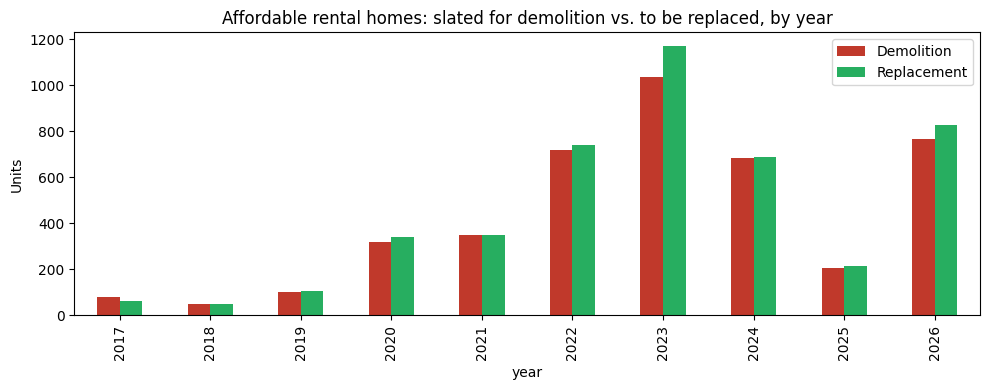

In [6]:
demo_raw = load_package_tables("demolition-and-replacement-of-rental-housing-units",
                               "demolition and replacement of rental housing units")
demo = demo_raw.copy()

c = {k: pick_col(demo, *p) for k, p in {
    "dem_tot":  [r"^Total Rental Homes for Demolition"], "dem_aff": [r"^Affordable Rental Homes for Demolition"],
    "dem_mid":  [r"^Mid-Range Rental Homes for Demolition"], "dem_high": [r"^High-End Rental Homes for Demolition"],
    "rep_tot":  [r"^Total Rental Homes Replaced"], "rep_aff": [r"^Affordable Rental Homes Replaced"],
    "rep_mid":  [r"^Mid-Range Rental Homes Replaced"], "rep_high": [r"^High-End Rental Homes Replaced"],
    "permit_dt": [r"^Date the Rental Demolition Permit"], "council_dt": [r"Council Approval Date"],
    "address": [r"^Address of Existing Rental Building"], "ward": [r"Post 2018.*Ward", r"Ward"]}.items()}
print(c)
missing = [k for k, v in c.items() if v is None]
if missing:
    print("WARNING: columns not found:", missing, "- check the package columns:", list(demo.columns)[:30])

blank_rep = int(demo[c["rep_aff"]].isna().sum()) if c["rep_aff"] else 0
for k in ["dem_tot", "dem_aff", "dem_mid", "dem_high", "rep_tot", "rep_aff", "rep_mid", "rep_high"]:
    demo[k] = to_num(demo[c[k]]).fillna(0) if c[k] else 0          # blank replacement counts are read as "none reported"
permit_dt, council_dt = sane_dates(to_dt(demo[c["permit_dt"]])), sane_dates(to_dt(demo[c["council_dt"]]))
demo["event_date"] = permit_dt.fillna(council_dt)
demo["date_basis"] = np.where(permit_dt.notna(), "permit_issued", np.where(council_dt.notna(), "council_approval", "none"))
demo = finalize_geo(demo, ward_col=c["ward"], label="Demolition")   # no coordinates -> source ward field (post-2018 = 25-ward model)

assert demo["_uid"].is_unique, "duplicate demolition rows"
assert (demo[["dem_tot", "dem_aff", "rep_tot", "rep_aff"]] >= 0).all().all(), "negative unit counts"
demo["net_affordable_change"] = demo["rep_aff"] - demo["dem_aff"]
demo["affordable_replacement_ratio"] = np.where(demo["dem_aff"] > 0, demo["rep_aff"] / demo["dem_aff"], np.nan)

fact_demo = demo[["_uid", c["address"], "ward_id", "geo_method", "event_date", "date_basis",
                  "dem_tot", "dem_aff", "dem_mid", "dem_high", "rep_tot", "rep_aff", "rep_mid", "rep_high",
                  "net_affordable_change", "affordable_replacement_ratio"]].rename(columns={c["address"]: "address"})
write_table(fact_demo, "fact_demolition_replacement")

ev_demo = make_events(demo, "_uid", "DEMO_", "RENTAL_DEMOLITION", demo["event_date"],
                      "Demolition and Replacement of Rental Housing Units", address=c["address"],
                      units=demo["dem_tot"], affordable=demo["dem_aff"])
write_events(ev_demo, ["Demolition and Replacement of Rental Housing Units"])
log_dq("Demolition & Replacement", len(demo), len(ev_demo), demo,
       f"{(demo['date_basis']=='council_approval').sum()} rows dated by council approval (no permit yet); "
       f"{(demo['date_basis']=='none').sum()} undated dropped; {blank_rep} blank replacement counts read as 0")

print(f"\n{len(demo)} demolition applications. Affordable units: {int(demo.dem_aff.sum()):,} slated for demolition, "
      f"{int(demo.rep_aff.sum()):,} to be replaced -> net {int(demo.net_affordable_change.sum()):+,}")
print(f"Ward unmapped: {int((demo.geo_method == 'unmapped').sum())} of {len(demo)};  blank 'affordable replaced' cells read as 0: {blank_rep}")

yr = demo.assign(year=pd.to_datetime(demo["event_date"]).dt.year).groupby("year")[["dem_aff", "rep_aff"]].sum()
yr.plot(kind="bar", figsize=(10, 4), color=["#c0392b", "#27ae60"])
plt.title("Affordable rental homes: slated for demolition vs. to be replaced, by year"); plt.ylabel("Units")
plt.legend(["Demolition", "Replacement"]); finish_plot("b1_demolition_by_year")

## B2. Active Affordable and Social Housing Units
An earlier version treated this file as a list of buildings and summed its rows, which double-counts the stock (each quarter is a snapshot of the same buildings) and leaves every ward empty. The file is actually a **quarterly city-wide count** (for example `Q1 2020: 6,101`) with no ward or address. It is therefore used for what it can support: the size of the protected stock and its recent trend. It is *not* a ward denominator.

Loaded 'Active Affordable and Social Housing Units' [active-affordable-and-social-housing-units]: 27 rows, 6 cols
   - loaded: Social and Affordable Housing (27 rows)
   - skipped duplicate copy of an already-loaded table: Social and Affordable Housing.csv


,_id,Quarter,Subsidized Housing Units,Affordable Housing Units,_uid,_resource
0,1,Q1 2020,n/a,"6,101",0-1,Social and Affordable Housing
1,2,Q2 2020,n/a,"6,126",0-2,Social and Affordable Housing
2,3,Q3 2020,n/a,"6,128",0-3,Social and Affordable Housing
3,4,Q4 2020,n/a,"6,128",0-4,Social and Affordable Housing
4,5,Q1 2021,"85,768","6,470",0-5,Social and Affordable Housing


Detected columns: {'quarter': 'Quarter', 'affordable': 'Affordable Housing Units', 'subsidized': 'Subsidized Housing Units', 'ward': None}
   FIX 2: definitional break detected at Q2 2024; trend fitted on the 9 quarters after it (naive full-series trend was +1,004/yr)
Quarters with data: 26.  Latest (Q2 2026): 13,163 affordable units.  Fitted trend: +1,707 units per year
Subsidized housing units reported as n/a in 5 of 27 quarters


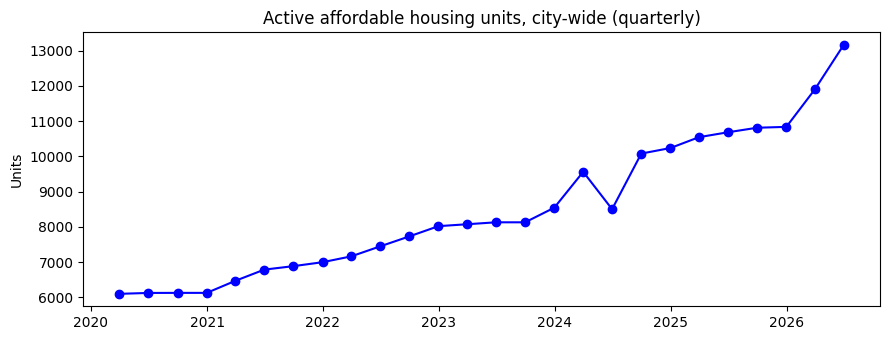

In [7]:
STOCK_OV = {}   # e.g. {"quarter": "Quarter", "affordable": "Affordable Housing Units", "subsidized": "Subsidized Housing Units"}

stock_raw = load_package_tables("active-affordable-and-social-housing-units", "active affordable and social housing units")
show(stock_raw, 5)
m = detect(stock_raw, STOCK_OV, {"quarter": [r"quarter|period"], "affordable": [r"afford.*(unit|home)", r"afford"],
                                 "subsidized": [r"subsid.*(unit|home)", r"subsid"], "ward": [r"^ward"]})
if m["ward"]:
    print("NOTE: a ward column now exists in this dataset - add a ward-level treatment here.")

def parse_quarter(s):
    t = str(s)
    mm = re.search(r"Q([1-4])\D{0,3}(\d{4})", t, re.I)
    if mm:
        q, y = int(mm.group(1)), int(mm.group(2))
    else:
        mm = re.search(r"(\d{4})\D{0,3}Q([1-4])", t, re.I)
        if not mm:
            return pd.NaT
        y, q = int(mm.group(1)), int(mm.group(2))
    return pd.Period(year=y, quarter=q, freq="Q").end_time.normalize()

fact_stock_city = pd.DataFrame({
    "quarter_label": stock_raw[m["quarter"]].astype(str),
    "quarter_end": stock_raw[m["quarter"]].map(parse_quarter),
    "affordable_units": to_num(stock_raw[m["affordable"]]) if m["affordable"] else np.nan,
    "subsidized_units": to_num(stock_raw[m["subsidized"]]) if m["subsidized"] else np.nan,
}).sort_values("quarter_end").reset_index(drop=True)
write_table(fact_stock_city, "fact_affordable_stock_city")

s = fact_stock_city.dropna(subset=["affordable_units", "quarter_end"])
STOCK_LATEST = float(s["affordable_units"].iloc[-1]) if len(s) else np.nan
STOCK_LATEST_Q = s["quarter_label"].iloc[-1] if len(s) else "n/a"
# ---- FIX 2: the series has a definitional break. Q4 2023 = 8,544 -> Q1 2024 = 9,561
# -> Q2 2024 = 8,501. A single straight line through the whole series is therefore
# contaminated by a reporting change, not a real jump in stock. Detect the break and
# fit the trend on the longest consistent segment; report the naive figure alongside.
STOCK_TREND_NAIVE = np.nan
STOCK_TREND_PER_YEAR = np.nan
STOCK_BREAK_QUARTER = None
if len(s) >= 4:
    t_all = (s["quarter_end"] - s["quarter_end"].iloc[0]).dt.days / 365.25
    STOCK_TREND_NAIVE = float(np.polyfit(t_all, s["affordable_units"], 1)[0])

    v = s["affordable_units"].to_numpy(float)
    diffs = np.diff(v)
    med_abs = np.median(np.abs(diffs)) if len(diffs) else 0.0
    # a break = a jump much larger than the typical quarterly move, immediately reversed
    breaks = []
    for k in range(1, len(diffs)):
        if med_abs > 0 and abs(diffs[k - 1]) > 5 * med_abs and abs(diffs[k]) > 5 * med_abs \
                and np.sign(diffs[k - 1]) != np.sign(diffs[k]):
            breaks.append(k)          # index of the first quarter after the jump
    if breaks:
        STOCK_BREAK_QUARTER = str(s["quarter_label"].iloc[breaks[-1]])
        seg = s.iloc[breaks[-1]:].reset_index(drop=True)
        print(f"   FIX 2: definitional break detected at {STOCK_BREAK_QUARTER}; "
              f"trend fitted on the {len(seg)} quarters after it (naive full-series trend was {STOCK_TREND_NAIVE:+,.0f}/yr)")
    else:
        seg = s.reset_index(drop=True)
    if len(seg) >= 4:
        t_seg = (seg["quarter_end"] - seg["quarter_end"].iloc[0]).dt.days / 365.25
        STOCK_TREND_PER_YEAR = float(np.polyfit(t_seg, seg["affordable_units"], 1)[0])
    else:
        STOCK_TREND_PER_YEAR = STOCK_TREND_NAIVE
log_dq("Active Affordable & Social Housing", len(stock_raw), 0, None,
       "city-wide quarterly series; no ward or address, so it is not mapped and writes no events")
print(f"Quarters with data: {len(s)}.  Latest ({STOCK_LATEST_Q}): {STOCK_LATEST:,.0f} affordable units.  "
      f"Fitted trend: {STOCK_TREND_PER_YEAR:+,.0f} units per year")
print("Subsidized housing units reported as n/a in", int(fact_stock_city["subsidized_units"].isna().sum()), "of", len(fact_stock_city), "quarters")
plt.figure(figsize=(9, 3.5))
plt.plot(s["quarter_end"], s["affordable_units"], marker="o", color="blue")
plt.title("Active affordable housing units, city-wide (quarterly)"); plt.ylabel("Units")
finish_plot("b2_stock_city")

## B3. Affordable Rental Housing Pipeline
Projects approved or in development, with a status. The earlier version counted **every** project as future supply, including ones already occupied, and assumed 100% would be delivered evenly over five years. Here each project is placed in a stage (`completed`, `under_construction`, `approved`, `planning`, `other`). A delivery probability and delivery window per stage come from `PIPELINE_ASSUMPTIONS` in Section 0. These are **planning assumptions, not estimates from data**, so the forecast is also run under low and high scenarios.

In [8]:
PIPE_OV = {}
STAGE_OVERRIDE = {}     # e.g. {"Some Exact Status Text": "approved"}

pipe_raw = load_package_tables("upcoming-and-recently-completed-affordable-housing-units", "affordable rental housing pipeline")
show(pipe_raw)
m = detect(pipe_raw, PIPE_OV, {
    "pid": [r"^Project ID"], "ward": [r"Ward Number", r"^ward.*(num|id|code)", r"^ward"], "geom": [r"^geometry$"],
    "address": [r"^Addresses", r"address"], "units": [r"^Affordable Homes Approved", r"afford.*(unit|home)"],
    "rgi": [r"^RGI"], "supportive": [r"^Supportive"], "rent_ctrl": [r"Rent-Controlled"], "status": [r"^status", r"status|stage"]})

pipe = pipe_raw.copy()
if m["pid"]:
    n0 = len(pipe); pipe = pipe.drop_duplicates(m["pid"]).reset_index(drop=True)
    if n0 != len(pipe):
        print(f"   removed {n0 - len(pipe)} rows repeating a Project ID")
pipe = add_coords(pipe, geom_col=m["geom"])
pipe = finalize_geo(pipe, ward_col=m["ward"], lat_col="_lat", lon_col="_lon", label="Affordable Pipeline")

def pipeline_stage(status):
    t = str(status).lower()
    if status in STAGE_OVERRIDE:
        return STAGE_OVERRIDE[status]
    if re.search(r"occupied|complet", t):                        return "completed"
    if re.search(r"construction|building permit|permit issued", t): return "under_construction"
    if re.search(r"approved|council|zoning|opa", t):             return "approved"
    if re.search(r"application|review|planning|pre-?app|proposal|prelim", t): return "planning"
    return "other"

pipe["units"] = to_num(pipe[m["units"]]).fillna(0)
pipe["stage"] = pipe[m["status"]].map(pipeline_stage)
pipe["p_deliver"] = pipe["stage"].map(lambda s_: PIPELINE_ASSUMPTIONS[s_][0])
pipe["deliver_lo"] = pipe["stage"].map(lambda s_: PIPELINE_ASSUMPTIONS[s_][1])
pipe["deliver_hi"] = pipe["stage"].map(lambda s_: PIPELINE_ASSUMPTIONS[s_][2])

def p_by_year(h, lo, hi):
    """Share of a project's delivery window (years lo..hi, uniform) that falls on or before year h."""
    return np.clip((np.minimum(h, hi) - lo + 1) / (hi - lo + 1), 0, 1)

for h in (FORECAST_YEARS,):
    pipe[f"expected_units_{h}y"] = pipe["units"] * pipe["p_deliver"] * p_by_year(h, pipe["deliver_lo"], pipe["deliver_hi"])

print("\nStatus -> stage mapping (check this table; use STAGE_OVERRIDE to correct it):")
disp(pipe.groupby([m["status"], "stage"]).agg(projects=("units", "size"), affordable_units=("units", "sum")).reset_index(), digits=0)

fact_pipe = pd.DataFrame({
    "_uid": pipe["_uid"], "project_id": pipe[m["pid"]] if m["pid"] else None, "address": pipe[m["address"]] if m["address"] else None,
    "status": pipe[m["status"]], "stage": pipe["stage"], "units": pipe["units"],
    "rgi_units": to_num(pipe[m["rgi"]]) if m["rgi"] else np.nan, "supportive_units": to_num(pipe[m["supportive"]]) if m["supportive"] else np.nan,
    "p_deliver": pipe["p_deliver"], "deliver_lo": pipe["deliver_lo"], "deliver_hi": pipe["deliver_hi"],
    f"expected_units_{FORECAST_YEARS}y": pipe[f"expected_units_{FORECAST_YEARS}y"],
    "ward_id": pipe["ward_id"], "neighbourhood_id": pipe["neighbourhood_id"], "geo_method": pipe["geo_method"]})
write_table(fact_pipe, "fact_affordable_pipeline")
log_dq("Affordable Rental Housing Pipeline", len(pipe_raw), 0, pipe,
       "snapshot with no dates -> fact table only, no events; completed projects excluded from future supply")
fut = fact_pipe[fact_pipe.stage != "completed"]
print(f"\nProjects: {len(fact_pipe)}. Affordable units approved in total: {fact_pipe.units.sum():,.0f} "
      f"(of which already completed/occupied: {fact_pipe.loc[fact_pipe.stage=='completed','units'].sum():,.0f}).")
print(f"Future pipeline (not completed): {fut.units.sum():,.0f} units; expected delivered within {FORECAST_YEARS} years "
      f"under base assumptions: {fut[f'expected_units_{FORECAST_YEARS}y'].sum():,.0f}. Ward unmapped: {(pipe.geo_method=='unmapped').mean():.1%}")

Loaded 'Affordable Housing Pipeline' [upcoming-and-recently-completed-affordable-housing-units]: 277 rows, 15 cols
   - loaded: Affordable Rental Housing Pipeline (277 rows)
   - skipped duplicate copy of an already-loaded table: Affordable Rental Housing Pipeline - 4326.csv
   - skipped duplicate copy of an already-loaded table: Affordable Rental Housing Pipeline - 2952.csv


,_id,Project ID,Addresses,Anchor Address,Status,Ward Number,Ward Name,Affordable Homes Approved,Rent-Controlled Market Units Approved,RGI Homes Approved,Supportive Units,Toronto Builds Portfolio,geometry,_uid,_resource
0,1,P0058,West Don Lands (phase 2 in PH5.3) Block 3/4/7 ...,373 Front St E,Occupied,13,Toronto Centre,275,0.0,0,0,No,"{""type"": ""Point"", ""coordinates"": [-79.35990217...",0-1,Affordable Rental Housing Pipeline
1,2,P0332,"985 Woodbine Avenue and 2078, 2086, 2100, 2102...",985 Woodbine Ave,Approved OPAs and Zoning By-Law Amendments,19,Beaches-East York,12,0.0,0,0,No,"{""type"": ""Point"", ""coordinates"": [-79.31250395...",0-2,Affordable Rental Housing Pipeline
2,3,P0107,976 College Street,976 College St,Planning Applications Under Review,9,Davenport,0,0.0,19,19,No,"{""type"": ""Point"", ""coordinates"": [-79.427965, ...",0-3,Affordable Rental Housing Pipeline


Detected columns: {'pid': 'Project ID', 'ward': 'Ward Number', 'geom': 'geometry', 'address': 'Addresses', 'units': 'Affordable Homes Approved', 'rgi': 'RGI Homes Approved', 'supportive': 'Supportive Units', 'rent_ctrl': 'Rent-Controlled Market Units Approved', 'status': 'Status'}
   coordinates: geometry:277 -> 100.0% of rows have a point
   spatial vs source-ward agreement: 100.0% on 277 rows

Status -> stage mapping (check this table; use STAGE_OVERRIDE to correct it):


,Status,stage,projects,affordable_units
0,Approved OPAs and Zoning By-Law Amendments,approved,140,11361
1,Approved Site Plan Application,approved,1,129
2,Building Permit Application,under_construction,4,122
3,Issued Building Permit,under_construction,2,87
4,Occupied,completed,35,656
5,Planning Applications Under Review,planning,34,5470
6,Pre-Planning,planning,17,1866
7,Started Construction,under_construction,44,2841



Projects: 277. Affordable units approved in total: 22,532 (of which already completed/occupied: 656).
Future pipeline (not completed): 21,876 units; expected delivered within 5 years under base assumptions: 12,701. Ward unmapped: 0.0%


## B4. RentSafeTO — Apartment Building Evaluation

The brief asks for RentSafeTO evaluation **degradation**, so the notebook keeps each building's full evaluation history and measures the change between the latest and the previous score.

* **At-risk level.** The earlier 50% threshold is not a City rule and flagged exactly one building. The City's colour signs use bands (green 85–100, yellow 70–84, red below 70). The red band is used here (`RS_RED_BELOW = 70`) and **drives the watch list**. Confirm the bands against current programme rules before presenting.
* **Audit priority.** The City also prioritises the lowest 2.5% of scores each year for audit. That percentile is computed per evaluation year and stored as a building flag (`audit_priority`, setting `RS_AUDIT_PERCENTILE`), but it is **not** part of the watch list — it is a separate, sharper signal for who gets inspected.
* **Degradation.** A building is `degrading` if its latest score is at least `RS_DROP_POINTS` (5) below its previous score — the drop the City uses as an engagement trigger. Only buildings with two or more evaluations can be classified.
* **Watch list** (`at_risk`) = red band **or** degrading.

**Score comparability.** The pre-2023 and 2023+ evaluation files store the score in different columns and the mean score shifts by more than five points across that boundary, so the evaluation method may have changed. `score_delta` values that span 2022→2023 are therefore treated with caution and a warning is printed when the shift is detected.


   merged differently-spelled columns: ['YEAR REGISTERED + YEAR_REGISTERED', 'YEAR BUILT + YEAR_BUILT', 'YEAR EVALUATED + YEAR_EVALUATED', 'PROPERTY TYPE + PROPERTY_TYPE', 'SITE ADDRESS + SITE_ADDRESS', 'CONFIRMED STOREYS + CONFIRMED_STOREYS', 'CONFIRMED UNITS + CONFIRMED_UNITS', 'EVALUATION COMPLETED ON + EVALUATION_COMPLETED_ON']
Loaded 'Apartment Building Evaluation' [apartment-building-evaluation]: 18,917 rows, 91 cols  (removed 1 exact duplicate rows)
   - loaded: Apartment Building Evaluations 2023 - current (7,158 rows)
   - loaded: Pre-2023 Apartment Building Evaluations (11,760 rows)
   - skipped duplicate copy of an already-loaded table: Apartment Building Evaluations 2023 - current.csv
   - skipped duplicate copy of an already-loaded table: Pre-2023 Apartment Building Evaluations.csv
Detected columns: {'rsn': 'RSN', 'ward': 'WARD', 'lat': 'LATITUDE', 'lon': 'LONGITUDE', 'address': 'SITE ADDRESS', 'score': 'CURRENT BUILDING EVAL SCORE', 'units': 'CONFIRMED UNITS', 'year_built

eval_date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
count,3005.0,751.0,3050.0,1473.0,1471.0,1987.0,1771.0,1805.0,1733.0,1871.0
mean,65.5,68.0,75.8,77.1,76.7,80.9,87.6,87.2,91.0,90.8
median,65.0,68.0,76.0,78.0,78.0,81.0,89.0,89.0,92.0,92.0


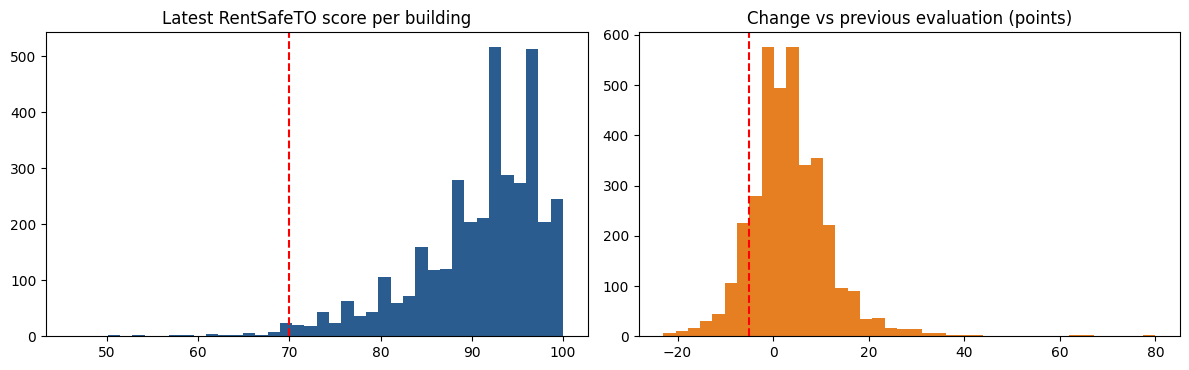

In [9]:
RS_OV = {}

rs_raw = load_package_tables("apartment-building-evaluation", "RentSafeTO apartment building evaluation")
m = detect(rs_raw, RS_OV, {
    "rsn": [r"^RSN$"], "ward": [r"^WARD$", r"^ward"], "lat": [r"^lat"], "lon": [r"^lon"], "address": [r"site.?address", r"address"],
    "score": [r"CURRENT.*BUILDING.*EVAL.*SCORE", r"^SCORE$", r"EVAL.*SCORE", r"^score"], "units": [r"CONFIRMED.?UNITS", r"unit"],
    "year_built": [r"YEAR.?BUILT"], "eval_date": [r"EVALUATION.?COMPLETED", r"EVAL.*DATE"], "eval_year": [r"YEAR.?EVALUATED"]})
assert m["rsn"] and m["score"], "RSN / score column not found - set RS_OV"

rs = rs_raw.copy()

# ---- FIX 1: the pre-2023 file stores the score in `SCORE`, the 2023+ file in
# `CURRENT BUILDING EVAL SCORE`. Detecting only the new name silently dropped every
# pre-2023 evaluation (11,759 rows), so no building could ever show a score *drop*.
_score_cols = [c_ for c_ in rs.columns if _colkey(c_) in ("score", "currentbuildingevalscore")]
if len(_score_cols) > 1:
    rs["_score_all"] = rs[_score_cols[0]]
    for c_ in _score_cols[1:]:
        rs["_score_all"] = rs["_score_all"].combine_first(rs[c_])
    m["score"] = "_score_all"
    print(f"   FIX 1: coalesced score columns {_score_cols} -> one score series "
          f"({int(rs['_score_all'].notna().sum()):,} non-null scores)")
elif _score_cols:
    m["score"] = _score_cols[0]

rs["eval_date"] = sane_dates(to_dt(rs[m["eval_date"]])) if m["eval_date"] else pd.Series(pd.NaT, index=rs.index)
if m["eval_year"]:
    yr_fallback = pd.to_datetime(to_num(rs[m["eval_year"]]).round().astype("Int64").astype(str) + "-07-01", errors="coerce")
    rs["eval_date"] = rs["eval_date"].fillna(yr_fallback)
rs["score_v"] = to_num(rs[m["score"]]).where(lambda x: x.between(0, 100))
n_noscore = int(rs["score_v"].isna().sum())
rs = rs.dropna(subset=["score_v", "eval_date"]).sort_values([m["rsn"], "eval_date"]).reset_index(drop=True)
print(f"   {n_noscore:,} rows without a valid score or date were dropped; {len(rs):,} evaluations remain")

hist = rs[[m["rsn"], "eval_date", "score_v"]].rename(columns={m["rsn"]: "rsn"})
write_table(hist, "fact_rentsafe_history")

rs["prev_score"] = rs.groupby(m["rsn"])["score_v"].shift(1)
rs["prev_date"] = rs.groupby(m["rsn"])["eval_date"].shift(1)
rs["n_evals"] = rs.groupby(m["rsn"]).cumcount() + 1
latest = rs.groupby(m["rsn"]).tail(1).copy().reset_index(drop=True)          # one row per building: its latest evaluation
latest["score_delta"] = latest["score_v"] - latest["prev_score"]
latest["days_between_evals"] = (latest["eval_date"] - latest["prev_date"]).dt.days

latest = finalize_geo(latest, ward_col=m["ward"], lat_col=m["lat"], lon_col=m["lon"], label="RentSafeTO")
latest["score"] = latest["score_v"]
latest["units"] = to_num(latest[m["units"]]).fillna(0) if m["units"] else 0
latest["year_built"] = to_num(latest[m["year_built"]]) if m["year_built"] else np.nan
latest["red_band"] = latest["score"] < RS_RED_BELOW
latest["degrading"] = latest["score_delta"] <= -RS_DROP_POINTS
latest["at_risk"] = latest["red_band"] | latest["degrading"]
eval_year = latest["eval_date"].dt.year
audit_cut = latest.groupby(eval_year)["score"].transform(lambda x: x.quantile(RS_AUDIT_PERCENTILE))
latest["audit_priority"] = latest["score"] <= audit_cut

fact_rs = latest[["_uid", "ward_id", "neighbourhood_id", "geo_method", "score", "prev_score", "score_delta", "days_between_evals",
                  "n_evals", "units", "year_built", "eval_date", "red_band", "degrading", "at_risk", "audit_priority"]].copy()
fact_rs["rsn"] = latest[m["rsn"]]
fact_rs["address"] = latest[m["address"]] if m["address"] else None
write_table(fact_rs, "fact_rentsafe")
log_dq("RentSafeTO Evaluation", len(rs_raw), 0, latest, "building-level table (latest evaluation per building); history in fact_rentsafe_history")

print(f"\n{len(latest):,} buildings, {latest.units.sum():,.0f} units ({(latest.units == 0).mean():.1%} of buildings have no unit count).")
print(f"Latest score: mean {latest.score.mean():.1f}, median {latest.score.median():.1f}, 5th percentile {latest.score.quantile(.05):.1f}")
print(f"Red band (<{RS_RED_BELOW}): {latest.red_band.sum():,} buildings / {latest.loc[latest.red_band,'units'].sum():,.0f} units")
print(f"Degrading (drop >= {RS_DROP_POINTS} pts; {latest.score_delta.notna().sum():,} buildings have 2+ evaluations): "
      f"{latest.degrading.sum():,} buildings / {latest.loc[latest.degrading,'units'].sum():,.0f} units")
print(f"Watch list (red or degrading): {latest.at_risk.sum():,} buildings / {latest.loc[latest.at_risk,'units'].sum():,.0f} units")

# Is the score scale consistent across the 2023 change in evaluation files? A jump would make 'degradation' meaningless.
by_year = rs.groupby(rs["eval_date"].dt.year)["score_v"].agg(["count", "mean", "median"]).round(1)
disp(by_year.T)
yrs = by_year.index
if 2022 in yrs and 2023 in yrs and abs(by_year.loc[2023, "mean"] - by_year.loc[2022, "mean"]) > 5:
    print("WARNING: mean score changes by more than 5 points between 2022 and 2023. The evaluation method may have changed; "
          "treat score_delta that spans 2022->2023 with caution.")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(latest["score"], bins=40, color="#2b5c8f"); ax[0].axvline(RS_RED_BELOW, color="r", ls="--"); ax[0].set_title("Latest RentSafeTO score per building")
ax[1].hist(latest["score_delta"].dropna(), bins=40, color="#e67e22"); ax[1].axvline(-RS_DROP_POINTS, color="r", ls="--"); ax[1].set_title("Change vs previous evaluation (points)")
finish_plot("b4_rentsafe_distributions")

## B5. Ward-level depletion picture
Combines B1–B4 into one table per ward. Counts are summed only over rows that have a ward. `pipeline_cover` is expected five-year affordable pipeline deliveries divided by affordable units slated for demolition. It is left empty (not filled) where no demolition is planned.

Reconciliation  demolition: ward sum 4,311 vs total 4,311 | pipeline: 21,876 vs 21,876 | RentSafe buildings: 3,679 vs 3,679


,ward_name,aff_demolished,aff_replaced,demolition_cases,pipeline_units,pipeline_expected_5y,pipeline_projects,pipeline_completed_units,rs_buildings,rs_units,rs_avg_score,units_red,units_degrading,units_watch,buildings_watch,net_affordable_change,pipeline_cover,pct_units_watch,pct_buildings_watch
ward_id,,,,,,,,,,,,,,,,,,,
16,Don Valley East,315.0,300.0,5.0,793.0,578.85,3.0,0.0,159,16412.0,91.40,248.0,3870.0,3870.0,21.0,-15.0,1.84,0.24,0.13
5,York South-Weston,59.0,56.0,6.0,1577.0,1009.39,10.0,0.0,239,18366.0,87.83,28.0,5430.0,5430.0,49.0,-3.0,17.11,0.30,0.21
3,Etobicoke-Lakeshore,17.0,17.0,2.0,2049.0,1165.90,19.0,0.0,255,14262.0,92.43,87.0,1104.0,1104.0,29.0,0.0,68.58,0.08,0.11
1,Etobicoke North,0.0,0.0,0.0,60.0,14.40,2.0,0.0,83,9838.0,92.46,0.0,665.0,665.0,3.0,0.0,NaN,0.07,0.04
7,Humber River-Black Creek,236.0,236.0,1.0,188.0,131.60,2.0,0.0,103,15116.0,90.72,40.0,1097.0,1097.0,9.0,0.0,0.56,0.07,0.09
2,Etobicoke Centre,196.0,196.0,2.0,131.0,91.70,2.0,172.0,138,12982.0,93.36,132.0,250.0,382.0,6.0,0.0,0.47,0.03,0.04
14,Toronto-Danforth,195.0,195.0,6.0,1996.0,1250.92,16.0,100.0,154,10131.0,89.26,51.0,1408.0,1408.0,29.0,0.0,6.41,0.14,0.19
17,Don Valley North,87.0,87.0,3.0,1801.0,640.90,14.0,0.0,74,11901.0,91.86,0.0,1078.0,1078.0,7.0,0.0,7.37,0.09,0.09


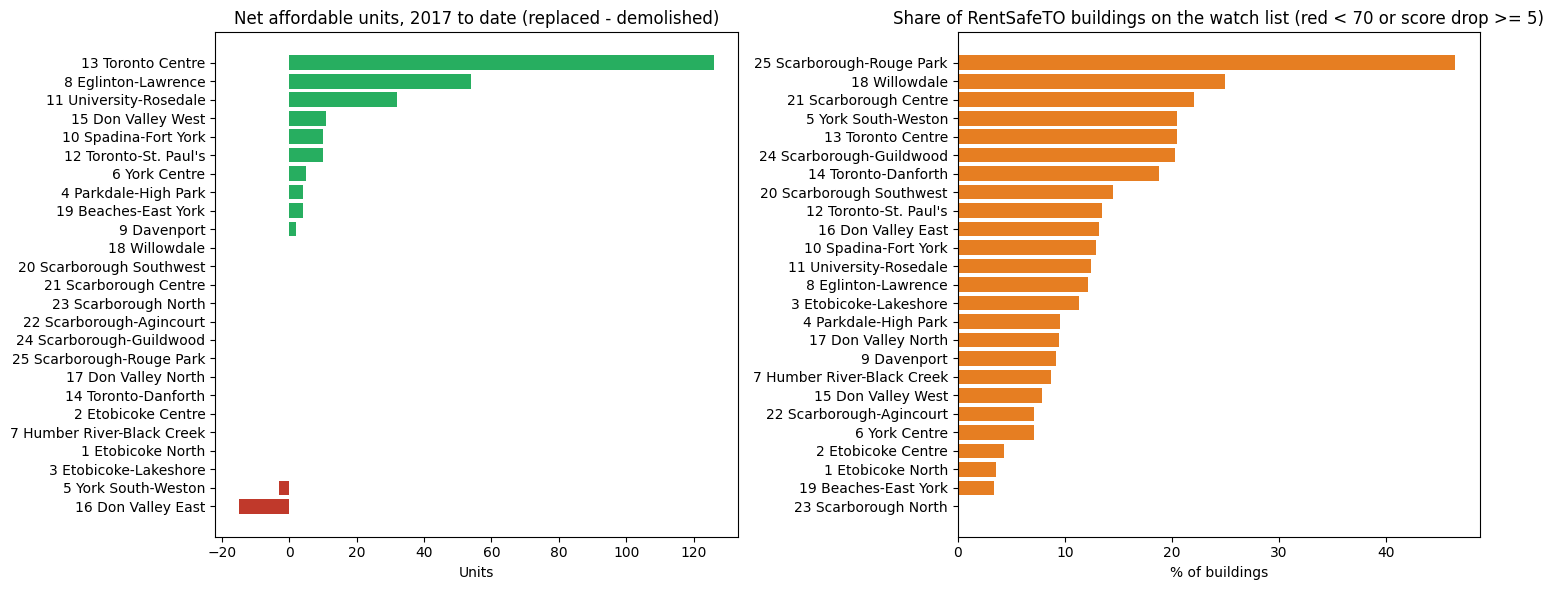

In [10]:
wd = pd.DataFrame({"ward_name": WARD_NAME})
wd.index.name = "ward_id"
wd = wd.join(by_ward(demo, aff_demolished=("dem_aff", "sum"), aff_replaced=("rep_aff", "sum"), demolition_cases=("_uid", "count")))
wd = wd.join(by_ward(fact_pipe[fact_pipe.stage != "completed"], pipeline_units=("units", "sum"),
                     pipeline_expected_5y=(f"expected_units_{FORECAST_YEARS}y", "sum"), pipeline_projects=("_uid", "count")))
wd = wd.join(by_ward(fact_pipe[fact_pipe.stage == "completed"], pipeline_completed_units=("units", "sum")))
wd = wd.join(by_ward(fact_rs, rs_buildings=("_uid", "count"), rs_units=("units", "sum"), rs_avg_score=("score", "mean")))
wd = wd.join(by_ward(fact_rs[fact_rs.red_band], units_red=("units", "sum")))
wd = wd.join(by_ward(fact_rs[fact_rs.degrading], units_degrading=("units", "sum")))
wd = wd.join(by_ward(fact_rs[fact_rs.at_risk], units_watch=("units", "sum"), buildings_watch=("_uid", "count")))
for col in wd.columns.drop(["ward_name", "rs_avg_score"]):
    wd[col] = wd[col].fillna(0)             # a sum over no matching records is genuinely 0
wd["net_affordable_change"] = wd["aff_replaced"] - wd["aff_demolished"]
wd["pipeline_cover"] = np.where(wd["aff_demolished"] > 0, wd["pipeline_expected_5y"] / wd["aff_demolished"], np.nan)
wd["pct_units_watch"] = np.where(wd["rs_units"] > 0, wd["units_watch"] / wd["rs_units"], np.nan)
wd["pct_buildings_watch"] = np.where(wd["rs_buildings"] > 0, wd["buildings_watch"] / wd["rs_buildings"], np.nan)
write_table(wd.reset_index(), "ward_depletion")

# reconciliation: ward sums must equal the dataset totals (unmapped rows are the only allowed difference)
print(f"Reconciliation  demolition: ward sum {wd.aff_demolished.sum():,.0f} vs total {demo.dem_aff.sum():,.0f} | "
      f"pipeline: {wd.pipeline_units.sum():,.0f} vs {fut.units.sum():,.0f} | RentSafe buildings: {wd.rs_buildings.sum():,.0f} vs {len(fact_rs):,}")
disp(wd.sort_values("net_affordable_change").head(8))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sdf = wd.sort_values("net_affordable_change")["net_affordable_change"]
ax[0].barh([f"{i} {WARD_NAME[i]}" for i in sdf.index], sdf.values, color=np.where(sdf.values < 0, "#c0392b", "#27ae60"))
ax[0].set_title("Net affordable units, 2017 to date (replaced - demolished)"); ax[0].set_xlabel("Units")
s2 = wd["pct_buildings_watch"].dropna().sort_values()
ax[1].barh([f"{i} {WARD_NAME[i]}" for i in s2.index], s2.values * 100, color="#e67e22")
ax[1].set_title(f"Share of RentSafeTO buildings on the watch list (red < {RS_RED_BELOW} or score drop >= {RS_DROP_POINTS})"); ax[1].set_xlabel("% of buildings")
finish_plot("b5_ward_depletion")

## B6. Forecast: net flow of affordable units, 1–5 years ahead, by ward

**What is forecast.** For each ward and horizon *h* = 1…5 years:

```
net flow(h) = pipeline units delivered by year h − cumulative GROSS affordable loss by year h
```

A **deficit** is `net flow < 0`. The output is a probability of deficit and a 10–90% range, not a single number.

**Why the target had to change.** The earlier version forecast *net* loss (demolished − replaced). Because replacement commitments almost always exceed demolitions, net loss is zero or negative in about 92% of ward-years, so its median is zero — and mean absolute error is minimised by the median. "Predict zero" was therefore the MAE-optimal forecast by construction, and no honest model could beat it. That is a mis-specified target, not a weak model.

This version forecasts **gross** affordable units put at risk by demolition — the quantity that actually varies (36% of ward-years are non-zero) and the one policy responds to. Reviewing the earlier conclusion also meant changing the *scoring rule*: a risk forecast is judged on the whole predictive distribution, not on a point error.

**How it is validated.** Demolition events are rare (about 170 applications in nine years across 25 wards), so the notebook back-tests first: several simple methods are run on years they have not seen (rolling origin — train on years before *T*, predict year *T*), and each is compared with "predict zero" and with a pooled mean.

Scores reported:

| Score | What it measures | Lower is better |
|---|---|---|
| **CRPS** | the whole predictive distribution against the realised value | yes |
| **RMSE** | penalises the large misses, which are the ones that matter for policy | yes |
| **Brier** | the probability assigned to "this ward loses any units at all" | yes |
| **MAE** | the point forecast — reported for completeness, and expected to lose to zero | yes |

**How to read the outcome.** The corrected target beats "predict zero" clearly on CRPS and modestly on RMSE and Brier, and still loses on MAE. That is the expected and honest result: **loss is forecastable as a probability and a range, not as a point estimate**. The simulation below therefore reports ranges and probabilities, and the notebook says so on the page rather than quoting a point number.

**What is not in the forecast.** RentSafeTO degradation is shown as a separate stress test (`stress_extra_loss_watch_units`), because nothing in these files links a low score to a later loss of units.


In [11]:
last_full_year = AS_OF.year - 1
years = list(range(PANEL_START_YEAR, last_full_year + 1))
dm = demo.assign(year=pd.to_datetime(demo["event_date"]).dt.year).dropna(subset=["ward_id", "year"]).copy()
dm["ward_id"] = dm["ward_id"].astype(int)
dm["net_loss"] = dm["dem_aff"] - dm["rep_aff"]

def panel(col):
    return (dm.groupby(["ward_id", "year"])[col].sum().unstack("year")
              .reindex(index=range(1, 26), columns=years).fillna(0))

H = panel("net_loss")          # net loss (demolished - replaced); the old target
G = panel("dem_aff")           # gross affordable units slated for demolition
print(f"Annual panel: {H.shape[0]} wards x {H.shape[1]} years ({years[0]}-{years[-1]})")
print(f"  net loss  : {(H.values != 0).mean():.0%} of ward-years non-zero, {(H.values > 0).sum()} positive of {H.size}")
print(f"  gross loss: {(G.values != 0).mean():.0%} of ward-years non-zero, {(G.values > 0).sum()} positive of {G.size}")

# ---------------------------------------------------------------------------
# FIX 4a — the old forecast was mis-specified in two ways, and both are fixed here.
#
# (1) WRONG TARGET. It forecast *net* loss (demolished - replaced). Replacement is a
#     planning commitment that almost always exceeds demolition, so net loss is
#     negative or zero in 92% of ward-years (only 3 of 225 are positive). A series
#     that is almost always <= 0 cannot be forecast better than "predict zero" by
#     any method, and the old notebook correctly but unhelpfully reported that.
#     The quantity that actually varies, and that policy cares about, is GROSS
#     affordable units put at risk by demolition: 36% of ward-years are non-zero.
#
# (2) WRONG SCORING RULE. MAE is minimised by the median. For a zero-inflated
#     series the median IS zero, so "predict zero" is the MAE-optimal forecast and
#     no honest model can beat it on MAE. Judging a risk forecast by MAE is a
#     category error. A forecast that says "this ward has a 30% chance of losing
#     200 units" is useful even though its MAE is worse than zero. The right
#     scores are CRPS (whole predictive distribution), RMSE (penalises the big
#     misses that matter) and the Brier score / AUC (the probability of any loss).
#     All are reported below, against "predict zero" AND against the pooled mean.

def one_step(train, kind, K=None):
    n = train.shape[1]; pool = float(train.values.mean())
    if kind == "zero":    return pd.Series(0.0, index=train.index)
    if kind == "last":    return train.iloc[:, -1].astype(float)
    if kind == "recent3": return train.iloc[:, -3:].mean(axis=1)
    if kind == "pooled":  return pd.Series(pool, index=train.index)
    w = n / (n + K)
    return w * train.mean(axis=1) + (1 - w) * pool

METHODS = {"Zero loss (baseline)": ("zero", None), "Last year (baseline)": ("last", None), "Last 3 years mean": ("recent3", None),
           "Pooled mean, same for all wards": ("pooled", None), "Ward's own mean": ("shrink", 0),
           "Shrinkage K=1": ("shrink", 1), "Shrinkage K=3": ("shrink", 3), "Shrinkage K=6": ("shrink", 6)}
K_OF = {"Pooled mean, same for all wards": None, "Ward's own mean": 0, "Shrinkage K=1": 1, "Shrinkage K=3": 3, "Shrinkage K=6": 6}

def crps_poisson(mu, y):
    """Closed-form CRPS for a Poisson predictive distribution (lower is better)."""
    out = []
    for m, yy in zip(np.asarray(mu, float), np.asarray(y, float)):
        m = max(m, 1e-9)
        k = np.arange(0, int(m + 10 * np.sqrt(m) + 30))
        cdf = np.cumsum(stats.poisson.pmf(k, m))
        out.append(np.sum((cdf - (yy <= k)) ** 2))
    return float(np.mean(out))

def backtest(M, label):
    rows = []
    for T in years[MIN_TRAIN_YEARS:]:
        tr_ = M[[y for y in years if y < T]]
        actual = M[T]
        for name, (kind, K) in METHODS.items():
            p = one_step(tr_, kind, K)
            rows.append({"test_year": T, "method": name, "MAE": (actual - p).abs().mean(),
                         "RMSE": np.sqrt(((actual - p) ** 2).mean()),
                         "city_total_error": p.sum() - actual.sum()})
    bt = pd.DataFrame(rows)
    s = bt.groupby("method").agg(MAE=("MAE", "mean"), RMSE=("RMSE", "mean"),
                                 abs_city_error=("city_total_error", lambda x: x.abs().mean())).sort_values("MAE")
    s["MAE_skill_vs_zero_%"] = 100 * (1 - s["MAE"] / s.loc["Zero loss (baseline)", "MAE"])
    s["RMSE_skill_vs_zero_%"] = 100 * (1 - s["RMSE"] / s.loc["Zero loss (baseline)", "RMSE"])
    print(f"\n--- {label}: rolling-origin back-test, test years {years[MIN_TRAIN_YEARS]}-{years[-1]} ---")
    disp(s)
    return bt, s

# ---- (a) the old target, for the record ----------
bt_net, bt_net_sum = backtest(H, "NET loss (the old target)")
write_table(bt_net_sum.reset_index(), "backtest_affordable_loss")
zero_mae = bt_net_sum.loc["Zero loss (baseline)", "MAE"]
champ = sorted(K_OF, key=lambda k: (round(bt_net_sum.loc[k, "MAE"], 4), -(1e9 if K_OF[k] is None else K_OF[k])))[0]
champ_mae = bt_net_sum.loc[champ, "MAE"]
print(f"\nNET loss: best method {champ} (MAE {champ_mae:.2f}) vs 'predict zero' ({zero_mae:.2f}).")
print("  This is not a modelling failure. Net loss is <= 0 in 92% of ward-years, so its median is 0 and")
print("  'predict zero' is the MAE-optimal forecast by construction. No method can beat it on MAE.")

# ---- (b) the corrected target, scored properly ----------------------------
bt_g, bt_g_sum = backtest(G, "GROSS affordable units slated for demolition (corrected target)")
write_table(bt_g_sum.reset_index(), "backtest_affordable_gross")

# probabilistic back-test on the corrected target
prow = []
for T in years[MIN_TRAIN_YEARS:]:
    tr_ = G[[y for y in years if y < T]]
    y = G[T].to_numpy(float)
    n = tr_.shape[1]
    mu_ward = (tr_.values.sum(1) + 2 * tr_.values.mean()) / (n + 2)      # shrunk ward mean
    mu_pool = np.full(len(y), tr_.values.mean())
    ev = (y > 0).astype(int)
    prow.append({"test_year": T,
                 "CRPS_zero": float(np.abs(y).mean()), "CRPS_ward": crps_poisson(mu_ward, y), "CRPS_pooled": crps_poisson(mu_pool, y),
                 "RMSE_zero": float(np.sqrt((y ** 2).mean())), "RMSE_ward": float(np.sqrt(((y - mu_ward) ** 2).mean())),
                 "MAE_zero": float(np.abs(y).mean()), "MAE_ward": float(np.abs(y - mu_ward).mean()),
                 "Brier_zero": float((ev ** 2).mean()),
                 "Brier_ward": float((((1 - np.exp(-mu_ward)) - ev) ** 2).mean())})
pbt = pd.DataFrame(prow)
ps = pbt.mean(numeric_only=True)
print("\nProbabilistic back-test on the corrected target (mean over test years):")
disp(pd.DataFrame({
    "predict zero": [ps.CRPS_zero, ps.RMSE_zero, ps.MAE_zero, ps.Brier_zero],
    "ward model":   [ps.CRPS_ward, ps.RMSE_ward, ps.MAE_ward, ps.Brier_ward],
}, index=["CRPS (lower better)", "RMSE (lower better)", "MAE (lower better)", "Brier (lower better)"]), digits=3)
disp(pbt, digits=2)
write_table(pbt, "backtest_affordable_probabilistic")

LOSS = {"crps": float(ps.CRPS_ward), "crps_zero": float(ps.CRPS_zero),
        "crps_gain_pct": float(100 * (1 - ps.CRPS_ward / ps.CRPS_zero)),
        "rmse": float(ps.RMSE_ward), "rmse_zero": float(ps.RMSE_zero),
        "rmse_gain_pct": float(100 * (1 - ps.RMSE_ward / ps.RMSE_zero)),
        "mae": float(ps.MAE_ward), "mae_zero": float(ps.MAE_zero),
        "brier": float(ps.Brier_ward), "brier_zero": float(ps.Brier_zero),
        "brier_gain_pct": float(100 * (1 - ps.Brier_ward / ps.Brier_zero))}
print(f"\nRESULT (corrected target, proper scores): the ward model beats 'predict zero' on")
print(f"  CRPS  {LOSS['crps']:.2f} vs {LOSS['crps_zero']:.2f}  ({LOSS['crps_gain_pct']:+.0f}%)")
print(f"  RMSE  {LOSS['rmse']:.2f} vs {LOSS['rmse_zero']:.2f}  ({LOSS['rmse_gain_pct']:+.0f}%)")
print(f"  Brier {LOSS['brier']:.3f} vs {LOSS['brier_zero']:.3f}  ({LOSS['brier_gain_pct']:+.0f}%)")
print(f"  MAE   {LOSS['mae']:.2f} vs {LOSS['mae_zero']:.2f}  ({100*(1-LOSS['mae']/LOSS['mae_zero']):+.0f}%) <- still loses, as it must")
print("So the loss IS forecastable as a distribution and a risk; it is NOT forecastable as a single number.")
print("The 5-year simulation below therefore uses the corrected target and reports ranges, not point estimates.")

# the champion point method on the corrected target, used by the simulation
CHAMP_K = K_OF[champ]


Annual panel: 25 wards x 9 years (2017-2025)
  net loss  : 8% of ward-years non-zero, 3 positive of 225
  gross loss: 36% of ward-years non-zero, 80 positive of 225

--- NET loss (the old target): rolling-origin back-test, test years 2020-2025 ---


,MAE,RMSE,abs_city_error,MAE_skill_vs_zero_%,RMSE_skill_vs_zero_%
method,,,,,
Zero loss (baseline),1.30,5.16,31.17,0.00,0.00
"Pooled mean, same for all wards",1.63,5.25,34.34,-25.49,-1.79
Shrinkage K=6,1.66,5.57,34.34,-28.01,-7.89
Shrinkage K=3,1.69,5.75,34.34,-30.18,-11.45
Shrinkage K=1,1.73,5.97,34.34,-33.42,-15.71
Ward's own mean,1.77,6.14,34.34,-36.15,-19.06
Last 3 years mean,2.05,7.68,42.72,-57.44,-48.85
Last year (baseline),2.26,8.72,50.83,-73.85,-68.97



NET loss: best method Pooled mean, same for all wards (MAE 1.63) vs 'predict zero' (1.30).
  This is not a modelling failure. Net loss is <= 0 in 92% of ward-years, so its median is 0 and
  'predict zero' is the MAE-optimal forecast by construction. No method can beat it on MAE.

--- GROSS affordable units slated for demolition (corrected target): rolling-origin back-test, test years 2020-2025 ---


,MAE,RMSE,abs_city_error,MAE_skill_vs_zero_%,RMSE_skill_vs_zero_%
method,,,,,
Zero loss (baseline),22.11,52.25,552.67,0.00,0.00
Shrinkage K=1,22.49,49.51,379.87,-1.76,5.25
Ward's own mean,22.50,49.96,379.87,-1.80,4.39
Shrinkage K=3,22.56,49.08,379.87,-2.03,6.08
Shrinkage K=6,22.71,48.85,379.87,-2.72,6.51
"Pooled mean, same for all wards",23.65,49.53,379.87,-6.97,5.21
Last 3 years mean,26.88,57.40,349.67,-21.61,-9.85
Last year (baseline),32.20,69.95,294.67,-45.66,-33.87



Probabilistic back-test on the corrected target (mean over test years):


,predict zero,ward model
CRPS (lower better),22.107,13.463
RMSE (lower better),52.254,49.245
MAE (lower better),22.107,22.517
Brier (lower better),0.467,0.450


,test_year,CRPS_zero,CRPS_ward,CRPS_pooled,RMSE_zero,RMSE_ward,MAE_zero,MAE_ward,Brier_zero,Brier_ward
0,2020,12.76,6.87,7.52,34.16,33.89,12.76,14.07,0.28,0.46
1,2021,13.96,10.77,9.58,35.38,33.89,13.96,16.39,0.36,0.52
2,2022,28.76,15.51,14.84,63.02,60.66,28.76,29.18,0.56,0.38
3,2023,41.52,19.01,18.99,123.37,119.38,41.52,42.93,0.40,0.57
4,2024,27.40,18.68,23.13,43.77,29.76,27.40,20.69,0.56,0.43
5,2025,8.24,9.95,10.50,13.82,17.90,8.24,11.84,0.64,0.35



RESULT (corrected target, proper scores): the ward model beats 'predict zero' on
  CRPS  13.46 vs 22.11  (+39%)
  RMSE  49.25 vs 52.25  (+6%)
  Brier 0.450 vs 0.467  (+4%)
  MAE   22.52 vs 22.11  (-2%) <- still loses, as it must
So the loss IS forecastable as a distribution and a risk; it is NOT forecastable as a single number.
The 5-year simulation below therefore uses the corrected target and reports ranges, not point estimates.


,test_year,ward_coverage_80%,city_total_inside_range
0,2020,0.76,False
1,2021,0.80,False
2,2022,0.60,False
3,2023,0.72,False
4,2024,0.68,True
5,2025,1.00,True


Ward-level 10-90% range contained the actual value 76% of the time (target 80%; zeros inflate this); city total inside its range in 2 of 6 test years.
City-wide forecast (units, 10th / 50th / 90th percentile). Current protected stock (Q2 2026): 13,163


,horizon_years,loss_p10,loss_p50,loss_p90,gain_p10,gain_p50,gain_p90,net_p10,net_p50,net_p90,p_deficit
0,1,155.0,333.0,733.0,530.0,956.0,1423.0,44.0,587.0,1103.0,0.0
1,2,412.0,716.0,1240.0,2919.0,3882.0,5119.0,2045.0,3114.0,4404.0,0.0
2,3,700.0,1099.0,1748.0,6094.0,7393.0,9061.0,4830.0,6230.0,7972.0,0.0
3,4,998.0,1502.0,2237.0,8429.0,10004.0,11941.0,6756.0,8454.0,10478.0,0.0
4,5,1323.0,1892.0,2715.0,10966.0,12590.0,14725.0,8876.0,10635.0,12817.0,0.0



Sensitivity of the 5-year city net flow to the pipeline delivery assumptions:


,scenario,pipeline_gain_mean_5y,net_flow_p10,net_flow_p50,net_flow_p90
0,low (x0.5),6336.0,2650.0,4295.0,6206.0
1,base (x1.0),12732.0,8824.0,10652.0,12921.0
2,high (x1.25),15310.0,11564.0,13218.0,15440.0



Wards ranked by probability of an affordable-unit deficit at year 5 (ties broken by median net flow):


,ward_id,ward_name,loss_p50,gain_mean,net_flow_p10,net_flow_p50,net_flow_p90,p_deficit,stress_extra_loss_watch_units
122,23,Scarborough North,46.0,0.00,-172.0,-46.0,0.0,0.89,0.00
117,18,Willowdale,45.0,7.03,-167.1,-37.0,7.0,0.80,120.05
100,1,Etobicoke North,47.0,14.52,-172.0,-33.0,32.0,0.77,33.25
101,2,Etobicoke Centre,48.0,92.44,-113.0,34.0,126.0,0.39,19.10
106,7,Humber River-Black Creek,46.0,131.31,-75.0,75.0,180.0,0.25,54.85
114,15,Don Valley West,47.0,132.85,-50.1,80.0,151.0,0.19,71.70
108,9,Davenport,46.0,135.46,-51.0,81.0,159.0,0.18,25.40
121,22,Scarborough-Agincourt,47.0,197.00,-21.0,143.0,262.0,0.13,20.80
118,19,Beaches-East York,48.0,201.23,0.0,140.0,238.0,0.10,37.70
103,4,Parkdale-High Park,46.0,220.59,13.9,164.0,263.0,0.09,85.00


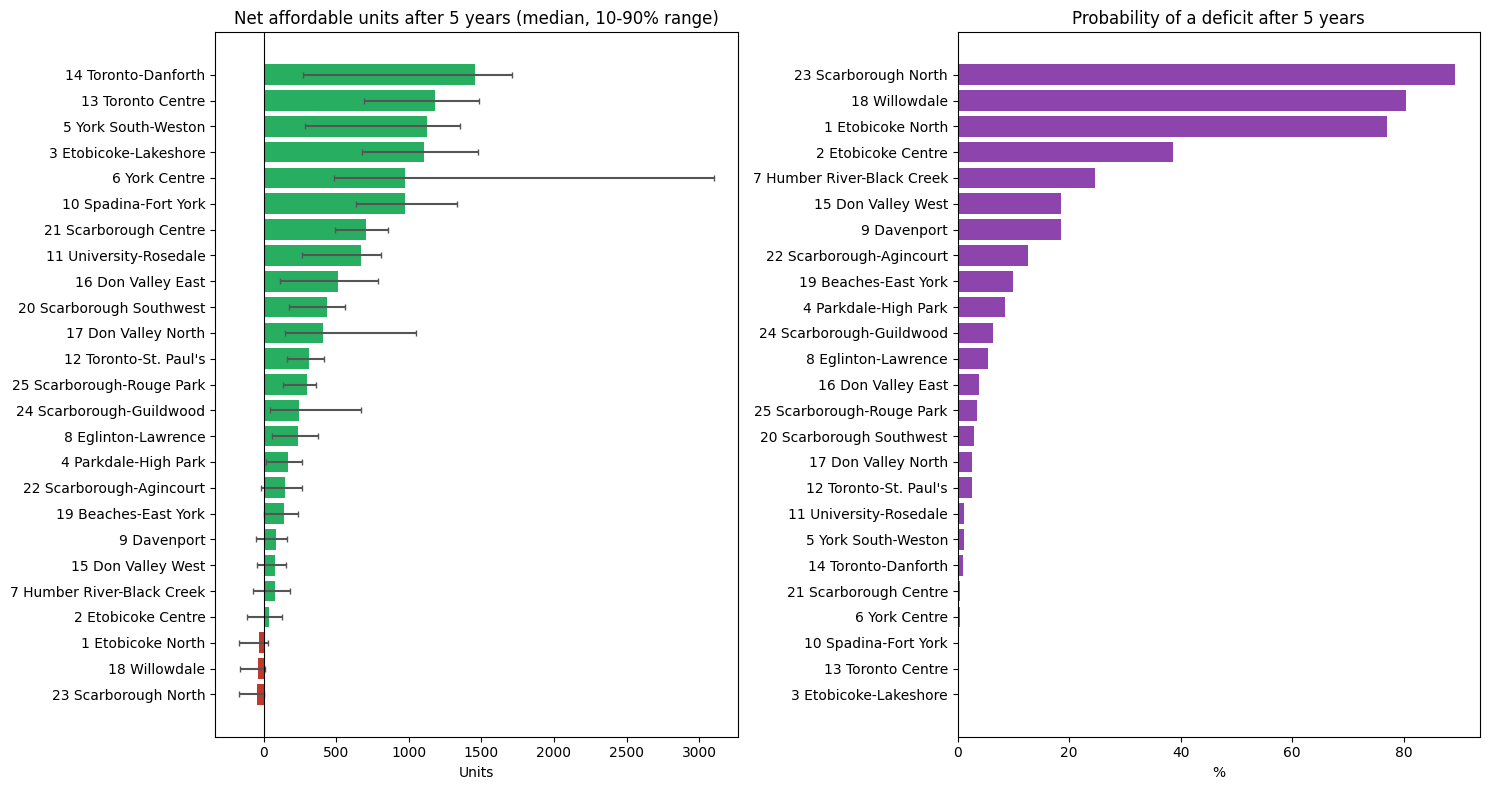

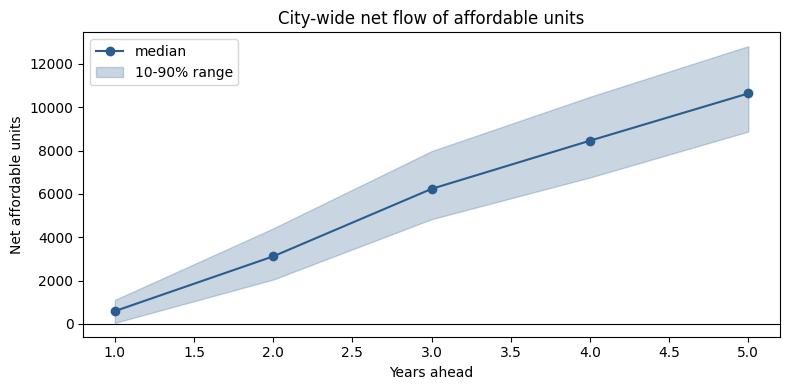

In [12]:
def draw_losses(train, K, horizon, sims, rng):
    """Simulated annual gross affordable loss, shape (sims, horizon, wards).
    Each ward-year is drawn from the ward's own history with probability n/(n+K),
    otherwise from the pooled history of all wards (K=None -> pooled only)."""
    n = train.shape[1]
    w = 0.0 if K is None else n / (n + K)
    pool = train.values.ravel()
    out = np.zeros((sims, horizon, train.shape[0]))
    for j in range(train.shape[0]):
        own = rng.choice(train.iloc[j].values, size=(sims, horizon))
        pl = rng.choice(pool, size=(sims, horizon))
        out[:, :, j] = np.where(rng.random((sims, horizon)) < w, own, pl)
    return out

# ---- calibration: do the 10-90% ranges contain the truth about 80% of the time? ----
cal = []
for T in years[MIN_TRAIN_YEARS:]:
    tr_ = G[[y for y in years if y < T]]
    d_ = draw_losses(tr_, CHAMP_K, 1, 2000, np.random.default_rng(SEED))[:, 0, :]
    lo_, hi_ = np.percentile(d_, 10, axis=0), np.percentile(d_, 90, axis=0)
    a_ = G[T].values
    ct = np.percentile(d_.sum(axis=1), [10, 90])
    cal.append({"test_year": T, "ward_coverage_80%": float(((a_ >= lo_) & (a_ <= hi_)).mean()),
                "city_total_inside_range": bool(ct[0] <= a_.sum() <= ct[1])})
cal = pd.DataFrame(cal)
disp(cal)
print(f"Ward-level 10-90% range contained the actual value {cal['ward_coverage_80%'].mean():.0%} of the time (target 80%; "
      f"zeros inflate this); city total inside its range in {cal['city_total_inside_range'].sum()} of {len(cal)} test years.")

# ---- main simulation: gross losses + staged pipeline deliveries ----
def simulate_flows(G_, K, horizon, sims, seed, p_mult=1.0):
    rng = np.random.default_rng(seed)
    loss = draw_losses(G_, K, horizon, sims, rng).cumsum(axis=1)                      # (sims, horizon, 25)
    pj = fact_pipe[(fact_pipe.stage != "completed") & fact_pipe.ward_id.notna() & (fact_pipe.units > 0)]
    widx = pj["ward_id"].astype(int).to_numpy() - 1
    onehot = np.zeros((len(pj), 25)); onehot[np.arange(len(pj)), widx] = 1
    units = pj["units"].to_numpy(float)
    lo, hi = pj["deliver_lo"].to_numpy(int), pj["deliver_hi"].to_numpy(int)
    deliver = rng.random((sims, len(pj))) < np.minimum(1.0, pj["p_deliver"].to_numpy(float) * p_mult)
    when = rng.integers(lo, hi + 1, size=(sims, len(pj)))
    gain = np.stack([((deliver & (when <= h)) * units) @ onehot for h in range(1, horizon + 1)], axis=1)   # (sims, horizon, 25)
    return loss, gain, gain - loss

loss_d, gain_d, net_d = simulate_flows(G, CHAMP_K, FORECAST_YEARS, SIMS, SEED)
watch_units = fact_rs[fact_rs.at_risk].dropna(subset=["ward_id"]).assign(ward_id=lambda d: d.ward_id.astype(int)).groupby("ward_id")["units"].sum().reindex(range(1, 26)).fillna(0)

rows = []
for h in range(1, FORECAST_YEARS + 1):
    for j, w in enumerate(range(1, 26)):
        L, Gg, N = loss_d[:, h - 1, j], gain_d[:, h - 1, j], net_d[:, h - 1, j]
        rows.append({"ward_id": w, "ward_name": WARD_NAME[w], "horizon_years": h,
                     "loss_p10": np.percentile(L, 10), "loss_p50": np.percentile(L, 50), "loss_p90": np.percentile(L, 90),
                     "gain_mean": Gg.mean(), "gain_p10": np.percentile(Gg, 10), "gain_p90": np.percentile(Gg, 90),
                     "net_flow_p10": np.percentile(N, 10), "net_flow_p50": np.percentile(N, 50), "net_flow_p90": np.percentile(N, 90),
                     "p_deficit": float((N < 0).mean()),
                     "stress_extra_loss_watch_units": watch_units[w] * STRESS_DEGRADATION_LOSS_RATE * h})
fc_aff = pd.DataFrame(rows)
write_table(fc_aff, "forecast_affordable_flow")

city_rows = []
for h in range(1, FORECAST_YEARS + 1):
    L, Gg, N = loss_d[:, h - 1, :].sum(axis=1), gain_d[:, h - 1, :].sum(axis=1), net_d[:, h - 1, :].sum(axis=1)
    city_rows.append({"horizon_years": h, "loss_p10": np.percentile(L, 10), "loss_p50": np.percentile(L, 50), "loss_p90": np.percentile(L, 90),
                      "gain_p10": np.percentile(Gg, 10), "gain_p50": np.percentile(Gg, 50), "gain_p90": np.percentile(Gg, 90),
                      "net_p10": np.percentile(N, 10), "net_p50": np.percentile(N, 50), "net_p90": np.percentile(N, 90), "p_deficit": float((N < 0).mean())})
fc_city = pd.DataFrame(city_rows)
write_table(fc_city, "forecast_affordable_flow_city")
print(f"City-wide forecast (units, 10th / 50th / 90th percentile). Current protected stock ({STOCK_LATEST_Q}): {STOCK_LATEST:,.0f}")
disp(fc_city, digits=0)

# ---- scenarios for the pipeline assumptions ----
sc = []
for name, mult in PIPELINE_SCENARIOS.items():
    _, g_, n_ = simulate_flows(G, CHAMP_K, FORECAST_YEARS, 2000, SEED, p_mult=mult)
    N5 = n_[:, -1, :].sum(axis=1)
    sc.append({"scenario": name, "pipeline_gain_mean_5y": g_[:, -1, :].sum(axis=1).mean(), "net_flow_p10": np.percentile(N5, 10),
               "net_flow_p50": np.percentile(N5, 50), "net_flow_p90": np.percentile(N5, 90)})
sc = pd.DataFrame(sc)
write_table(sc, "forecast_affordable_scenarios")
print("\nSensitivity of the 5-year city net flow to the pipeline delivery assumptions:")
disp(sc, digits=0)

f5 = fc_aff[fc_aff.horizon_years == FORECAST_YEARS].copy()
print(f"\nWards ranked by probability of an affordable-unit deficit at year {FORECAST_YEARS} (ties broken by median net flow):")
disp(f5.sort_values(["p_deficit", "net_flow_p50"], ascending=[False, True])[
    ["ward_id", "ward_name", "loss_p50", "gain_mean", "net_flow_p10", "net_flow_p50", "net_flow_p90", "p_deficit", "stress_extra_loss_watch_units"]].head(10), digits=2)

fig, ax = plt.subplots(1, 2, figsize=(15, 8))
f5s = f5.sort_values("net_flow_p50")
ax[0].barh([f"{i} {n}" for i, n in zip(f5s.ward_id, f5s.ward_name)], f5s.net_flow_p50, color=np.where(f5s.net_flow_p50 < 0, "#c0392b", "#27ae60"),
           xerr=[f5s.net_flow_p50 - f5s.net_flow_p10, f5s.net_flow_p90 - f5s.net_flow_p50], ecolor="#555", capsize=2)
ax[0].axvline(0, color="k", lw=.8); ax[0].set_title(f"Net affordable units after {FORECAST_YEARS} years (median, 10-90% range)"); ax[0].set_xlabel("Units")
f5p = f5.sort_values("p_deficit")
ax[1].barh([f"{i} {n}" for i, n in zip(f5p.ward_id, f5p.ward_name)], f5p.p_deficit * 100, color="#8e44ad")
ax[1].set_title(f"Probability of a deficit after {FORECAST_YEARS} years"); ax[1].set_xlabel("%")
finish_plot("b6_forecast_by_ward")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fc_city.horizon_years, fc_city.net_p50, marker="o", color="#2b5c8f", label="median")
ax.fill_between(fc_city.horizon_years, fc_city.net_p10, fc_city.net_p90, alpha=.25, color="#2b5c8f", label="10-90% range")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("Years ahead"); ax.set_ylabel("Net affordable units"); ax.set_title("City-wide net flow of affordable units"); ax.legend()
finish_plot("b6_forecast_city")


## B7. RentSafeTO degradation as a driver of depletion — tested, not assumed

The brief asks for depletion to be modelled as *"localized rental demolition rates against the active affordable plus social housing pipelines **and RentSafeTO evaluation degradation**"*. Revision 3 carried condition as a **stress test only** (`stress_extra_loss_watch_units`), on the grounds that nothing in the files links a low score to a later loss of units. That was an assertion. This section tests it.

**The test.** Demolition applications and RentSafeTO evaluations both carry a site address, so the two can be joined. For every RentSafeTO building we ask: *was this building the subject of a rental demolition application?* Then we compare the condition of buildings that were demolished with those that were not.

Three things are reported, in increasing order of how much they claim:

1. **Raw comparison** — score distribution of demolished vs surviving buildings, with a Mann–Whitney test. Descriptive, and confounded by ward and building age.
2. **Adjusted association** — a logistic regression of "demolished" on standardised score, with **ward fixed effects** and building age, so the comparison is within-ward and not just "poor buildings are in poor wards". The coefficient is reported as an odds ratio per 10-point lower score, with a 95% interval.
3. **A condition-elasticity for the forecast** — if the interval excludes 1, the estimated hazard ratio is used to scale each ward's loss rate by its own condition profile, and the forecast is re-run. If it does not exclude 1, the notebook says so and condition stays a stress test.

**Why this matters for the deliverable.** A stress test with an invented 1%-a-year rate is a number with no evidence behind it. An estimated hazard ratio, even a weak one, is a *measure* the engineering team can re-estimate as more data arrives — which is what the brief's "abstract measure definition" requirement is for.

In [13]:
# B7 - is RentSafeTO condition actually associated with demolition?
# Revision 3 treated condition as a stress test with an assumed 1%/yr rate. This
# section replaces the assumption with an estimate, and says plainly if the estimate is too weak to use.

def _addr_norm(s):
    """Number + street name, no type, no direction suffix noise. '123 Queen St W' -> '123|QUEEN'."""
    t = str(s).upper()
    t = re.sub(r"[^A-Z0-9 ]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    mm = re.match(r"^(\d+)\s+(.*)$", t)
    if not mm:
        return None
    num, rest = mm.group(1), mm.group(2)
    rest = re.sub(r"\b(STREET|ST|AVENUE|AVE|ROAD|RD|DRIVE|DR|BOULEVARD|BLVD|CRESCENT|CRES|"
                  r"PLACE|PL|COURT|CT|TERRACE|TER|WAY|LANE|LN|GATE|GDNS|GARDENS|PARKWAY|PKWY|"
                  r"SQUARE|SQ|CIRCLE|CIR|TRAIL|TRL|HEIGHTS|HTS)\b", " ", rest)
    rest = re.sub(r"\b(WEST|EAST|NORTH|SOUTH|W|E|N|S)\b", " ", rest)
    rest = re.sub(r"\s+", " ", rest).strip()
    return f"{num}|{rest}" if rest else None

_demo_addr = demo[c["address"]].map(_addr_norm) if c["address"] else pd.Series(dtype=object)
_demo_set = set(_demo_addr.dropna())

fact_rs["_addr_n"] = fact_rs["address"].map(_addr_norm) if "address" in fact_rs else np.nan
fact_rs["demolished"] = fact_rs["_addr_n"].isin(_demo_set) & fact_rs["_addr_n"].notna()

n_pos = int(fact_rs["demolished"].sum())
print(f"Address join: {len(_demo_set):,} distinct demolition addresses vs {fact_rs['_addr_n'].notna().sum():,} RentSafeTO buildings "
      f"with a usable address -> {n_pos} buildings matched to a demolition application "
      f"({n_pos / max(len(fact_rs), 1):.1%} of the RentSafeTO stock).")

COND = {"n_matched": n_pos, "usable": False, "hr_per_10pt": np.nan, "hr_lo": np.nan, "hr_hi": np.nan,
        "p_value": np.nan, "method": "not estimated", "converged": False}

if n_pos >= 15:
    d_ = fact_rs.dropna(subset=["score"]).copy()
    d_["score_z"] = (d_["score"] - d_["score"].mean()) / d_["score"].std()
    d_["age"] = (AS_OF.year - pd.to_numeric(d_["year_built"], errors="coerce")).clip(0, 150)
    d_["age"] = d_["age"].fillna(d_["age"].median())

    # 1. raw comparison
    a_, b_ = d_.loc[d_.demolished, "score"], d_.loc[~d_.demolished, "score"]
    if len(a_) >= 5 and len(b_) >= 5:
        u_, p_raw = stats.mannwhitneyu(a_, b_, alternative="two-sided")
        print(f"Raw comparison: demolished buildings score {a_.mean():.1f} on average vs {b_.mean():.1f} for survivors "
              f"(Mann-Whitney p = {p_raw:.3f}, n = {len(a_)} vs {len(b_):,}).")

    # 2. adjusted association. With only ~29 positive events, 25 ward dummies cannot be
    #    identified (the fit does not converge). Wards are therefore controlled by a
    #    3-level EXPOSURE tertile (how much RentSafeTO stock the ward has), which keeps
    #    the model to 4 parameters and still removes the crudest confounding.
    try:
        import statsmodels.api as sm
        wc = d_.groupby("ward_id").size()
        grp = pd.qcut(wc.rank(method="first"), 3, labels=["low", "mid", "high"])
        d_["ward_exposure"] = d_["ward_id"].map(grp).astype(str)
        Xc = pd.get_dummies(d_[["score_z", "age", "ward_exposure"]], columns=["ward_exposure"],
                            drop_first=True, dtype=float)
        Xc = sm.add_constant(Xc.astype(float))
        yv_ = d_["demolished"].astype(int).to_numpy()
        fit_ = sm.Logit(yv_, Xc).fit(disp=0, maxiter=500)
        converged = bool(getattr(fit_, "mle_retvals", {}).get("converged", True))
        beta = float(fit_.params["score_z"]); se = float(fit_.bse["score_z"])
        sd_ = float(d_["score"].std())
        # log-odds change per 10-point LOWER score
        per10 = -10.0 * beta / sd_
        se10 = 10.0 * se / sd_
        hr = float(np.exp(per10))
        # NOTE: the interval must be built around per10 on the SAME side - the earlier
        # version subtracted the margin in the wrong direction and printed lo > hi.
        lo = float(np.exp(per10 - 1.96 * se10))
        hi = float(np.exp(per10 + 1.96 * se10))
        COND.update({"hr_per_10pt": hr, "hr_lo": lo, "hr_hi": hi, "p_value": float(fit_.pvalues["score_z"]),
                     "method": "logit, score + building age + ward exposure tertile",
                     "usable": bool(converged and (lo > 1.0 or hi < 1.0)), "converged": converged})
        print(f"Adjusted association (age + ward exposure controlled): odds ratio {hr:.2f} per 10 points LOWER score "
              f"(95% CI {lo:.2f}-{hi:.2f}, p = {fit_.pvalues['score_z']:.3f}; converged={converged}).")
        if not converged:
            print("  -> The fit did not converge: the estimate is reported for transparency but NOT used.")
        else:
            print(f"  -> {'The interval excludes 1: condition carries information about demolition risk.' if COND['usable'] else 'The interval includes 1: condition is NOT a demonstrated driver of demolition in these files.'}")
    except Exception as e:
        print(f"Adjusted model could not be fitted ({type(e).__name__}: {e}); reporting the raw comparison only.")
else:
    print(f"Only {n_pos} matched buildings - too few to estimate an association. Condition stays a stress test, "
          f"and the notebook says so rather than quoting a rate.")

# 3. condition-adjusted forecast: only if the association is usable
if COND["usable"]:
    _rs = fact_rs.dropna(subset=["ward_id"]).copy()
    _rs["ward_id"] = _rs["ward_id"].astype(int)
    city_red = float(_rs.loc[_rs.red_band, "units"].sum() / max(_rs["units"].sum(), 1))
    ward_red = _rs.groupby("ward_id").apply(
        lambda g: float(g.loc[g.red_band, "units"].sum() / max(g["units"].sum(), 1)), include_groups=False)
    mult = (COND["hr_per_10pt"] ** ((ward_red - city_red) * 100 / 10)).reindex(range(1, 26)).fillna(1.0).clip(0.5, 3.0)
    print(f"\nCondition multiplier by ward (1.00 = city average red-band share of {city_red:.1%}): "
          f"min {mult.min():.2f}, median {mult.median():.2f}, max {mult.max():.2f}")

    loss_c, gain_c, net_c = simulate_flows(G, CHAMP_K, FORECAST_YEARS, SIMS, SEED)
    loss_c = loss_c * mult.to_numpy()[None, None, :]
    net_c = gain_c - loss_c
    cond_rows = []
    for h in range(1, FORECAST_YEARS + 1):
        N = net_c[:, h - 1, :].sum(axis=1)
        cond_rows.append({"horizon_years": h, "net_p10": np.percentile(N, 10), "net_p50": np.percentile(N, 50),
                          "net_p90": np.percentile(N, 90), "p_deficit": float((N < 0).mean())})
    fc_cond = pd.DataFrame(cond_rows)
    write_table(fc_cond, "forecast_affordable_flow_condition")
    print("\nCity-wide net flow with condition-adjusted loss (compare with the B6 table):")
    disp(fc_cond, digits=0)
    COND["city_net_p50_5y"] = float(fc_cond.net_p50.iloc[-1])
    COND["city_p_deficit_5y"] = float(fc_cond.p_deficit.iloc[-1])
else:
    fc_cond = None
    COND["city_net_p50_5y"] = np.nan
    COND["city_p_deficit_5y"] = np.nan
    print("\nCondition is NOT used in the forecast: the association is not strong enough to justify it. "
          "`stress_extra_loss_watch_units` in B6 remains a labelled stress test only.")

write_table(pd.DataFrame([COND]), "condition_depletion_test")

Address join: 172 distinct demolition addresses vs 3,637 RentSafeTO buildings with a usable address -> 29 buildings matched to a demolition application (0.8% of the RentSafeTO stock).
Raw comparison: demolished buildings score 84.8 on average vs 90.6 for survivors (Mann-Whitney p = 0.005, n = 29 vs 3,650).
Adjusted association (age + ward exposure controlled): odds ratio 2.14 per 10 points LOWER score (95% CI 1.52-3.02, p = 0.000; converged=True).
  -> The interval excludes 1: condition carries information about demolition risk.

Condition multiplier by ward (1.00 = city average red-band share of 0.7%): min 0.95, median 0.98, max 1.35

City-wide net flow with condition-adjusted loss (compare with the B6 table):


,horizon_years,net_p10,net_p50,net_p90,p_deficit
0,1,45.0,589.0,1103.0,0.0
1,2,2046.0,3120.0,4404.0,0.0
2,3,4829.0,6240.0,7969.0,0.0
3,4,6762.0,8453.0,10485.0,0.0
4,5,8887.0,10649.0,12817.0,0.0


## Project 6 — Developer Responsiveness & Supply Forecasting
Three different delays are measured, because they answer different questions:

| Measure | Definition | Who is slow? |
|---|---|---|
| **Approval lag** | `ISSUED_DATE − APPLICATION_DATE` of a building permit | mostly the *City* |
| **Execution lag** | date of the first housing building permit at the same address, minus the Development Application submission date | the *development process end to end* |
| **Build lag** | `COMPLETED_DATE − ISSUED_DATE` | mostly the *developer* |

Execution lag and build lag involve work that has not finished yet (an application that has not reached a permit, a permit not yet completed). Averaging only the finished ones would make developers look faster than they are. Both are therefore estimated with **Kaplan–Meier survival curves**, which count unfinished cases as "still waiting" rather than ignoring them.

## C1. Development Applications
Planning-stage pipeline (rezoning, site plan, subdivision, etc.). Event date = submission date. Dwelling-unit counts are not a field in this dataset, so they are read from the free-text description and flagged as `units_parsed`; treat them as indicative. Coordinates are projected `X`/`Y`, which are converted to latitude/longitude so each application is placed in a ward and neighbourhood by location.

In [14]:
DEV_OV = {}

dev_raw = load_package_tables("development-applications", "development applications")
show(dev_raw)
m = detect(dev_raw, DEV_OV, {
    "date": [r"date.?submit", r"submit", r"application.*date", r"^date"], "type": [r"application.?type", r"^type"],
    "status": [r"^status"], "desc": [r"description"], "ward": [r"ward.?(num|id|code)", r"^ward"],
    "lat": [r"^lat"], "lon": [r"^lon|^lng"], "x": [r"^X$"], "y": [r"^Y$"],
    "street_num": [r"street.?num"], "street_name": [r"street.?name"], "street_type": [r"street.?type"], "folder": [r"FOLDERRSN"]})

dev = dev_raw.copy()
if m["folder"]:
    n0 = len(dev); dev = dev.drop_duplicates(m["folder"]).reset_index(drop=True)
    print(f"   {n0 - len(dev):,} rows repeating a FOLDERRSN removed; {len(dev):,} unique applications")
dev["event_date"] = sane_dates(to_dt(dev[m["date"]]))
print(f"   {int(dev['event_date'].isna().sum()):,} applications have no valid submission date (kept in the fact table, not evented)")
dev = add_coords(dev, lat_col=m["lat"], lon_col=m["lon"], x_col=m["x"], y_col=m["y"])
dev = finalize_geo(dev, ward_col=m["ward"], lat_col="_lat", lon_col="_lon", label="Development Applications")

UNIT_RE = re.compile(r"(\d[\d,]*)\s*(?:residential|dwelling|rental|affordable|condominium|apartment|new|replacement)?\s*"
                     r"(?:residential\s+)?(?:dwelling\s+)?(?:units?|suites?)\b", re.I)
def parse_units(text):
    nums = [int(x.replace(",", "")) for x in UNIT_RE.findall(str(text)) if x.replace(",", "").isdigit()]
    return max(nums) if nums else np.nan

HOUSING_RE = re.compile(r"residential|dwelling|rental|apartment|condominium|townhouse|mixed[- ]use|housing|\bunits?\b", re.I)
dev["units_parsed"] = dev[m["desc"]].map(parse_units) if m["desc"] else np.nan
dev["housing_related"] = (dev[m["desc"]].astype(str).str.contains(HOUSING_RE) | dev["units_parsed"].notna()) if m["desc"] else False

def addr_key(num, name, typ=None):
    """Street number + name + type, upper-case letters/digits only. Used to match applications to permits."""
    n = num.astype(str).str.extract(r"(\d+)")[0]
    k = n.fillna("") + "|" + name.fillna("").astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    if typ is not None:
        k = k + "|" + typ.fillna("").astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return k.where(n.notna() & name.notna())

if m["street_num"] and m["street_name"]:
    dev["addr_key"] = addr_key(dev[m["street_num"]], dev[m["street_name"]], dev[m["street_type"]] if m["street_type"] else None)
    dev["address"] = (dev[m["street_num"]].fillna("").astype(str) + " " + dev[m["street_name"]].fillna("").astype(str)
                      + (" " + dev[m["street_type"]].fillna("").astype(str) if m["street_type"] else "")).str.strip()
else:
    dev["addr_key"] = np.nan; dev["address"] = None
    print("NOTE: no street number/name columns found - application->permit matching (C3) will be skipped")

fact_dev = pd.DataFrame({"_uid": dev["_uid"], "event_date": dev["event_date"], "address": dev["address"], "addr_key": dev["addr_key"],
                         "app_type": dev[m["type"]] if m["type"] else None, "status": dev[m["status"]] if m["status"] else None,
                         "units_parsed": dev["units_parsed"], "housing_related": dev["housing_related"], "ward_id": dev["ward_id"],
                         "neighbourhood_id": dev["neighbourhood_id"], "geo_method": dev["geo_method"]})
write_table(fact_dev, "fact_dev_applications")

ev_dev = make_events(dev, "_uid", "DEVAPP_", "DEV_APPLICATION", dev["event_date"], "Development Applications",
                     address="address", units=dev["units_parsed"])
write_events(ev_dev, ["Development Applications"])
log_dq("Development Applications", len(dev_raw), len(ev_dev), dev,
       f"units parsed from text for {dev['units_parsed'].notna().mean():.0%} of rows (indicative only); "
       f"{dev['housing_related'].mean():.0%} flagged housing-related by keyword")
print(f"{len(ev_dev):,} dated applications; units parsed for {dev['units_parsed'].notna().mean():.0%}; "
      f"housing-related {dev['housing_related'].mean():.0%}; ward unmapped {(dev.geo_method=='unmapped').mean():.1%}; "
      f"neighbourhood assigned {dev['neighbourhood_id'].notna().mean():.1%}")
disp(dev[m["type"]].value_counts().head(8).to_frame("applications").T if m["type"] else pd.DataFrame())

Loaded 'Development Applications' [development-applications]: 26,455 rows, 27 cols  (removed 258 exact duplicate rows)
   - loaded: Development Applications (26,713 rows)
   - skipped duplicate copy of an already-loaded table: Development Applications.csv


,_id,APPLICATION_TYPE,APPLICATION#,STREET_NUM,STREET_NAME,STREET_TYPE,STREET_DIRECTION,POSTAL,DATE_SUBMITTED,STATUS,X,Y,DESCRIPTION,REFERENCE_FILE#,FOLDERRSN,WARD_NUMBER,WARD_NAME,COMMUNITY_MEETING_DATE,COMMUNITY_MEETING_TIME,COMMUNITY_MEETING_LOCATION,APPLICATION_URL,CONTACT_NAME,CONTACT_PHONE,CONTACT_EMAIL,PARENT_FOLDER_NUMBER,_uid,_resource
0,1,OZ,13 180561 WET 06 OZ,20,VAUDEVILLE,DR,,,2013-06-04T00:00:00,Closed,302056.58,4829780.61,Proposed amendments to the Etobicoke Zoning Co...,NaN,3368056,03,Etobicoke-Lakeshore,2016-06-02T00:00:00,7:00pm,Franklin Horner Community Centre,NaN,NaN,NaN,NaN,NaN,0-1,Development Applications
1,2,OZ,13 180561 WET 06 OZ,35,FATHER REDMOND,WAY,,,2013-06-04T00:00:00,Closed,301982.10,4829793.63,Proposed amendments to the Etobicoke Zoning Co...,NaN,3368056,03,Etobicoke-Lakeshore,2016-06-02T00:00:00,7:00pm,Franklin Horner Community Centre,NaN,NaN,NaN,NaN,NaN,0-2,Development Applications
2,3,OZ,13 180561 WET 06 OZ,11,FATHER REDMOND,WAY,,,2013-06-04T00:00:00,Closed,302068.61,4829820.41,Proposed amendments to the Etobicoke Zoning Co...,NaN,3368056,03,Etobicoke-Lakeshore,2016-06-02T00:00:00,7:00pm,Franklin Horner Community Centre,NaN,NaN,NaN,NaN,NaN,0-3,Development Applications


Detected columns: {'date': 'DATE_SUBMITTED', 'type': 'APPLICATION_TYPE', 'status': 'STATUS', 'desc': 'DESCRIPTION', 'ward': 'WARD_NUMBER', 'lat': None, 'lon': None, 'x': 'X', 'y': 'Y', 'street_num': 'STREET_NUM', 'street_name': 'STREET_NAME', 'street_type': 'STREET_TYPE', 'folder': 'FOLDERRSN'}
   17,816 rows repeating a FOLDERRSN removed; 8,639 unique applications
   0 applications have no valid submission date (kept in the fact table, not evented)
   X/Y converted from EPSG:2952 (100% of sampled points fall inside Toronto)
   coordinates: X/Y:8,548 -> 98.9% of rows have a point
   spatial vs source-ward agreement: 91.5% on 8,511 rows
8,639 dated applications; units parsed for 43%; housing-related 73%; ward unmapped 0.1%; neighbourhood assigned 98.6%


APPLICATION_TYPE,SA,OZ,CD,SB,PL
applications,4281,2789,1109,288,172


## C2. Building Permits — Active Permits + Cleared Permits
All rows of both packages are loaded (one copy of each table). Permits are de-duplicated on `PERMIT_NUM`, keeping the highest `REVISION_NUM`, so revisions are not double counted.

**Ward assignment.** These tables have no coordinates and no 25-ward field. They carry `GEO_ID`, which is joined to the Address Points layer to get coordinates, then placed in a ward and neighbourhood by point-in-polygon. An earlier version assigned most permits a ward by taking the first two digits of `WARD_GRID`, which was never checked and is wrong if the grid uses the older 44-ward numbering. Now `WARD_GRID` is used only as a **lookup learned from permits that do have coordinates**, and only for grid codes where at least 90% of those permits fall in one ward. The lookup is tested on held-out permits before it is applied.

**Data-entry errors.** Some permits report absurd unit counts (one "Interior Alterations" permit reported 100,000 new units for a $100,000 cost, which alone made up 93% of Ward 8's total). Permits above `MAX_UNITS_PER_PERMIT`, or with 500+ units and a cost under `MIN_COST_PER_UNIT` per unit, have their units set to zero, are listed below, and carry the flag `outlier_units` in the events table. Lags above `MAX_LAG_DAYS` are treated as date errors.

In [15]:
ADDR_OV = {}     # override the Address Points join, e.g. {"key": "ADDRESS_POINT_ID", "lat": "LATITUDE", "lon": "LONGITUDE"}

# ---- MEMORY FIX: the two permit tables are ~1.1M rows x 34 columns. Reading every
# column blows the 2 GB sandbox limit, so only the columns this analysis uses are read.
PERMIT_NEEDED = {"PERMIT_NUM", "REVISION_NUM", "APPLICATION_DATE", "ISSUED_DATE", "COMPLETED_DATE",
                 "DWELLING_UNITS_CREATED", "DWELLING_UNITS_LOST", "EST_CONST_COST", "GEO_ID",
                 "PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "STATUS",
                 "STREET_NUM", "STREET_NAME", "STREET_TYPE", "WARD_GRID"}
_keep_cols = lambda c: c in PERMIT_NEEDED

def _permit_window(df):
    """Keep only permits that touch the analysis window (applied or issued from 2017).
    This drops the pre-2017 cleared-permit resource almost entirely and keeps peak memory low."""
    a = pd.to_datetime(df.get("APPLICATION_DATE"), errors="coerce", format="mixed")
    i_ = pd.to_datetime(df.get("ISSUED_DATE"), errors="coerce", format="mixed")
    return df[(a >= ANALYSIS_START) | (i_ >= ANALYSIS_START)]

act = load_package_tables("building-permits-active-permits", "building permits active permits", dedupe=False,
                          usecols=_keep_cols, row_filter=_permit_window)
clr = load_package_tables("building-permits-cleared-permits", "building permits cleared permits", dedupe=False,
                          usecols=_keep_cols, row_filter=_permit_window)
act["permit_source"], clr["permit_source"] = "active", "cleared"
act["_uid"], clr["_uid"] = "A" + act["_uid"].astype(str), "C" + clr["_uid"].astype(str)

permits = pd.concat([act, clr], ignore_index=True)
del act, clr
need = ["PERMIT_NUM", "REVISION_NUM", "APPLICATION_DATE", "ISSUED_DATE", "COMPLETED_DATE", "DWELLING_UNITS_CREATED",
        "DWELLING_UNITS_LOST", "EST_CONST_COST", "GEO_ID", "PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "STATUS"]
miss = [c_ for c_ in need if c_ not in permits.columns]
assert not miss, f"permit columns not found: {miss}. Available: {list(permits.columns)}"

n_raw = len(permits)
permits["_rev"] = to_num(permits["REVISION_NUM"]).fillna(0)
permits["_rank"] = permits["permit_source"].map({"cleared": 0, "active": 1})
permits = (permits.sort_values(["PERMIT_NUM", "_rev", "_rank"], ascending=[True, False, True])
                  .drop_duplicates("PERMIT_NUM", keep="first").reset_index(drop=True))
assert permits["PERMIT_NUM"].is_unique
print(f"{n_raw:,} permit rows -> {len(permits):,} unique permits after keeping the latest revision")

permits["app_date"] = sane_dates(to_dt(permits["APPLICATION_DATE"]))
permits["issued_date"] = sane_dates(to_dt(permits["ISSUED_DATE"]))
permits["completed_date"] = sane_dates(to_dt(permits["COMPLETED_DATE"]))
permits["units_created"] = to_num(permits["DWELLING_UNITS_CREATED"]).fillna(0).clip(lower=0)
permits["units_lost"] = to_num(permits["DWELLING_UNITS_LOST"]).fillna(0).clip(lower=0)
permits["est_cost"] = to_num(permits["EST_CONST_COST"])

# ---- implausible unit counts ----
cpu = permits["est_cost"] / permits["units_created"].replace(0, np.nan)
permits["units_outlier"] = ((permits["units_created"] >= MAX_UNITS_PER_PERMIT) | (permits["units_lost"] >= MAX_UNITS_PER_PERMIT)
                            | ((permits["units_created"] >= 500) & (cpu < MIN_COST_PER_UNIT)))
permits["units_created_raw"], permits["units_lost_raw"] = permits["units_created"], permits["units_lost"]
permits.loc[permits["units_outlier"], ["units_created", "units_lost"]] = 0
print(f"Flagged {int(permits.units_outlier.sum())} permits with implausible unit counts (their units are set to 0):")
disp(permits.loc[permits.units_outlier, ["PERMIT_NUM", "STRUCTURE_TYPE", "WORK", "STATUS", "units_created_raw", "units_lost_raw", "est_cost"]]
     .sort_values("units_created_raw", ascending=False), n=15, digits=0)

# ---- lags (negative = data error; very long = data error) ----
permits["approval_lag_days"] = (permits["issued_date"] - permits["app_date"]).dt.days
permits["build_lag_days"] = (permits["completed_date"] - permits["issued_date"]).dt.days
for c_ in ("approval_lag_days", "build_lag_days"):
    bad = (permits[c_] < 0) | (permits[c_] > MAX_LAG_DAYS)
    print(f"   {c_}: {int(bad.sum()):,} values negative or longer than {MAX_LAG_DAYS} days set to missing")
    permits.loc[bad, c_] = np.nan

# ---- address key for matching to Development Applications ----
if "STREET_NUM" in permits and "STREET_NAME" in permits:
    permits["addr_key"] = addr_key(permits["STREET_NUM"], permits["STREET_NAME"], permits["STREET_TYPE"] if "STREET_TYPE" in permits else None)
else:
    permits["addr_key"] = np.nan

# ---- geography via the Address Points bridge ----
permits["_geo_id"] = to_num(permits["GEO_ID"])
lat_c = lon_c = None
if USE_ADDRESS_BRIDGE and HAS_GPD and wards_gdf is not None:
    try:
        ADDR_NEEDED = {"ADDRESS_POINT_ID", "ADDRESS_ID", "ADDRESS_STRING_ID", "LATITUDE", "LONGITUDE",
                       "X", "Y", "geometry", "WARD", "WARD_NAME"}
        addr = load_package_tables("address-points-municipal-toronto-one-address-repository",
                                   "address points municipal toronto one address repository", dedupe=False,
                                   usecols=lambda c: c in ADDR_NEEDED)
        print("   Address Points columns:", list(addr.columns)[:40])
        pid = set(permits["_geo_id"].dropna().astype("int64"))
        keys = [k for k in addr.columns if not str(k).startswith("_") and _colkey(k) in ("geoid", "addresspointid", "addressid", "addrpointid")]
        if ADDR_OV.get("key"):
            keys = [ADDR_OV["key"]]
        overlap = {k: len(pid & set(to_num(addr[k]).dropna().astype("int64"))) / max(len(pid), 1) for k in keys}
        print("   candidate join keys and the share of permit GEO_IDs they find:", {k: f"{v:.1%}" for k, v in overlap.items()})
        if overlap and max(overlap.values()) >= 0.3:
            key = max(overlap, key=overlap.get)
            addr["_geo_id"] = to_num(addr[key])
            addr = addr[addr["_geo_id"].isin(pid)].drop_duplicates("_geo_id")
            lat_src = ADDR_OV.get("lat") or pick_col(addr, r"^lat")
            lon_src = ADDR_OV.get("lon") or pick_col(addr, r"^lon|^lng")
            addr = add_coords(addr, lat_col=lat_src, lon_col=lon_src, geom_col="geometry" if "geometry" in addr.columns else None,
                              x_col=pick_col(addr, r"^X$"), y_col=pick_col(addr, r"^Y$"))
            permits = permits.merge(addr[["_geo_id", "_lat", "_lon"]], on="_geo_id", how="left")
            lat_c, lon_c = "_lat", "_lon"
            print(f"   joined on '{key}': coordinates found for {permits['_lat'].notna().mean():.1%} of permits")
        else:
            print("   No Address Points column matched the permit GEO_IDs well enough (set ADDR_OV). Spatial join skipped.")
        del addr
    except Exception as e:
        print("Address Points bridge failed:", type(e).__name__, str(e)[:200])

permits = finalize_geo(permits, lat_col=lat_c, lon_col=lon_c, label="Building Permits")

# ---- WARD_GRID: learn a lookup from spatially-mapped permits, test it on held-out rows, then apply it ----
def grid_keys(df):
    g_ = df["WARD_GRID"].astype(str).str.strip().str.upper()
    return {"full code": g_, "letter+2 digits": g_.str.extract(r"^([A-Z]\d{2})")[0]}

def learn_lookup(sp, key, min_n=GRID_MIN_N, min_purity=GRID_MIN_PURITY):
    t = sp.assign(_k=key).dropna(subset=["_k"]).groupby(["_k", "ward_id"]).size().rename("n").reset_index()
    t["tot"] = t.groupby("_k")["n"].transform("sum"); t["purity"] = t["n"] / t["tot"]
    t = t.sort_values("n", ascending=False).drop_duplicates("_k")
    return t[(t.tot >= min_n) & (t.purity >= min_purity)].set_index("_k")["ward_id"]

if "WARD_GRID" in permits.columns and (permits.geo_method == "spatial_join").sum() > 1000:
    sp = permits[permits.geo_method == "spatial_join"]
    ks = grid_keys(sp)
    hold = np.random.default_rng(SEED).random(len(sp)) < 0.2
    for kname, kser in ks.items():
        lk = learn_lookup(sp[~hold], kser[~hold])
        pred = kser[hold].map(lk)
        cov = pred.notna().mean()
        acc = (pred[pred.notna()] == sp["ward_id"][hold][pred.notna()]).mean() if pred.notna().any() else np.nan
        print(f"   WARD_GRID lookup by {kname}: {len(lk):,} usable codes; on held-out permits it covers {cov:.1%} and is right {acc:.1%} of the time")
    unm = permits.geo_method == "unmapped"
    for kname in ("full code", "letter+2 digits"):
        lk = learn_lookup(sp, grid_keys(sp)[kname])
        kser = grid_keys(permits)[kname]
        hit = unm & permits.geo_method.eq("unmapped") & kser.map(lk).notna()
        permits.loc[hit, "ward_id"] = kser[hit].map(lk).astype("Int64")
        permits.loc[hit, "geo_method"] = "ward_grid_lookup"
        unm = permits.geo_method == "unmapped"
else:
    print("   WARD_GRID lookup not built (too few spatially-mapped permits). Remaining permits stay unmapped.")

print("Geography method:\n", permits["geo_method"].value_counts(normalize=True).round(3).to_string())
if permits["ward_id"].notna().mean() < 0.5:
    print("WARNING: fewer than half of the permits have a ward. Ward-level permit results below are not reliable - fix the Address Points join (ADDR_OV).")

# ---- persist ----
keep = ["_uid", "PERMIT_NUM", "permit_source", "PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "STATUS", "app_date", "issued_date",
        "completed_date", "approval_lag_days", "build_lag_days", "units_created", "units_lost", "units_outlier", "est_cost",
        "addr_key", "ward_id", "neighbourhood_id", "geo_method"]
write_table(permits[keep], "fact_permits")

permits["address"] = (permits["STREET_NUM"].fillna("").astype(str) + " " + permits["STREET_NAME"].fillna("").astype(str) + " "
                      + permits["STREET_TYPE"].fillna("").astype(str)).str.strip() if "STREET_NUM" in permits else None
housing = (permits["units_created"] > 0) | (permits["units_lost"] > 0)       # only housing-relevant permits become events
n_dropped = int((housing & permits["issued_date"].isna()).sum())
oflag = permits["units_outlier"].map({True: "outlier_units"})
ev_parts = {}
for src_name, ev_type, label in (("active", "BUILDING_PERMIT", "Building Permits (Active)"), ("cleared", "BUILDING_PERMIT_CLEARED", "Building Permits (Cleared)")):
    sel = (permits.permit_source == src_name) & (housing | permits["units_outlier"])
    sub = permits[sel]
    ev_parts[label] = make_events(sub, "_uid", "PERMIT_", ev_type, sub["issued_date"], label, address="address",
                                  units=sub["units_created"], lost=sub["units_lost"], flag=oflag[sel])
    write_events(ev_parts[label], [label])
    log_dq(label.replace("Building Permits (", "Building Permits - ").rstrip(")"), int((permits.permit_source == src_name).sum()),
           len(ev_parts[label]), permits[permits.permit_source == src_name], "housing-relevant permits with an issue date")
print(f"Events written: " + ", ".join(f"{k}: {len(v):,}" for k, v in ev_parts.items()), f"| housing permits without an issue date (not evented): {n_dropped:,}")
disp(permits[["approval_lag_days", "build_lag_days"]].describe())

Loaded 'Building Permits - Active Permits' [building-permits-active-permits]: 125,000 rows, 19 cols
   - loaded: building-permits-active-permits (125,000 rows)
   - skipped duplicate copy of an already-loaded table: building-permits-active-permits.csv
Loaded 'Building Permits - Cleared Permits' [building-permits-cleared-permits]: 331,015 rows, 19 cols
   - loaded: Cleared Building Permits since 2017 (331,015 rows)
   - loaded: Cleared Permits 2000 to 2016 (0 rows)
   - skipped duplicate copy of an already-loaded table: Cleared Building Permits since 2017.csv
456,015 permit rows -> 404,230 unique permits after keeping the latest revision
Flagged 1 permits with implausible unit counts (their units are set to 0):


,PERMIT_NUM,STRUCTURE_TYPE,WORK,STATUS,units_created_raw,units_lost_raw,est_cost
153075,19 262243 BLD,Apartment Building,New Building,Closed,580.0,0.0,0.0


   approval_lag_days: 127 values negative or longer than 3650 days set to missing
   build_lag_days: 2 values negative or longer than 3650 days set to missing
Loaded 'Address Points (Municipal) - Toronto One Address Repository' [address-points-municipal-toronto-one-address-repository]: 525,035 rows, 8 cols
   - loaded: Address Points (525,035 rows)
   - skipped duplicate copy of an already-loaded table: Address Points - 4326.csv
   - skipped duplicate copy of an already-loaded table: Address Points - 2952.csv
   Address Points columns: ['ADDRESS_POINT_ID', 'ADDRESS_ID', 'ADDRESS_STRING_ID', 'WARD', 'WARD_NAME', 'geometry', '_uid', '_resource']
   candidate join keys and the share of permit GEO_IDs they find: {'ADDRESS_POINT_ID': '97.7%', 'ADDRESS_ID': '19.3%'}
   coordinates: geometry:106,436 -> 100.0% of rows have a point


/tmp/ipykernel_3295/1985082093.py:96: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  permits = permits.merge(addr[["_geo_id", "_lat", "_lon"]], on="_geo_id", how="left")


   joined on 'ADDRESS_POINT_ID': coordinates found for 90.9% of permits
   WARD_GRID lookup by full code: 410 usable codes; on held-out permits it covers 100.0% and is right 100.0% of the time
   WARD_GRID lookup by letter+2 digits: 25 usable codes; on held-out permits it covers 100.0% and is right 100.0% of the time
Geography method:
 geo_method
spatial_join        0.909
ward_grid_lookup    0.090
unmapped            0.000
Events written: Building Permits (Active): 7,817, Building Permits (Cleared): 19,485 | housing permits without an issue date (not evented): 5,106


,approval_lag_days,build_lag_days
count,361509.00,265263.00
mean,82.20,547.43
std,192.68,665.66
min,0.00,0.00
25%,11.00,125.00
50%,29.00,306.00
75%,63.00,670.00
max,3631.00,3601.00


### C2.1 Supply: net dwelling units permitted by ward and year
Net units = units created − units lost, from permits **issued since 2017**, with the unit-count errors above removed. Wards are ranked on this cleaned data.

361,564 permits issued 2017-2026 have a ward (100% of all permits issued in that window).


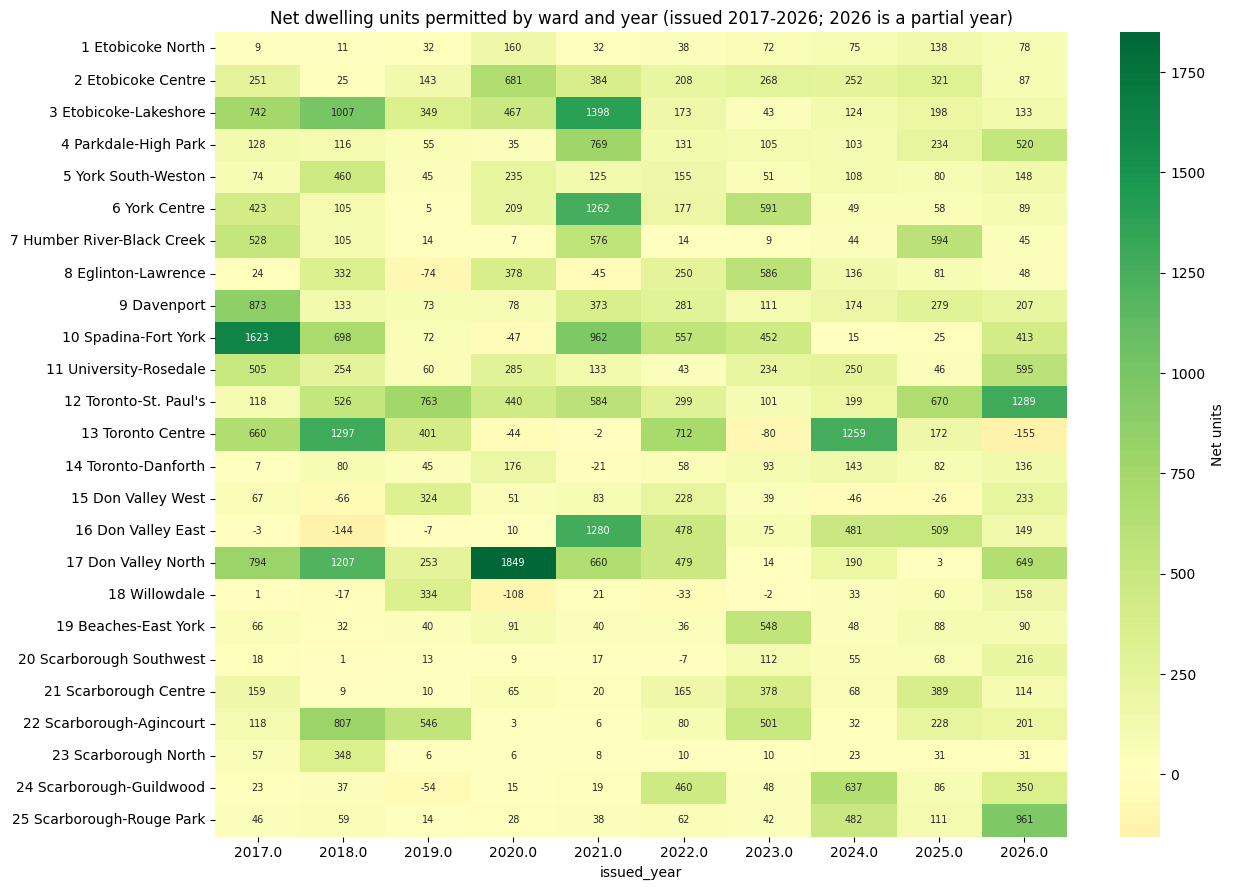

Top 5 wards by net permitted units: 17 Don Valley North (6,098), 12 Toronto-St. Paul's (4,989), 10 Spadina-Fort York (4,770), 3 Etobicoke-Lakeshore (4,634), 13 Toronto Centre (4,220)


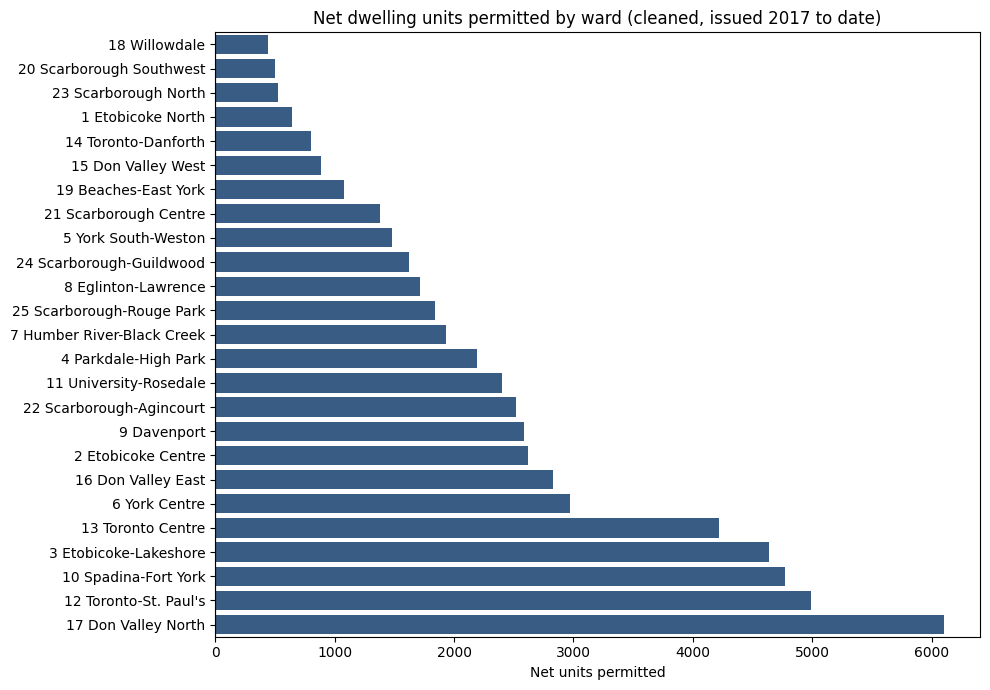

SQL vs pandas ward totals: largest difference 0.0 units (OK)


In [16]:
pm_all = permits[permits["ward_id"].notna()].copy()
pm_all["ward_id"] = pm_all["ward_id"].astype(int)
pm_all["net_units"] = pm_all["units_created"] - pm_all["units_lost"]
pm_all["issued_year"] = pm_all["issued_date"].dt.year
pm_win = pm_all[(pm_all["issued_date"] >= ANALYSIS_START) & (pm_all["issued_date"] <= AS_OF)].copy()      # analysis window
print(f"{len(pm_win):,} permits issued {ANALYSIS_START.year}-{AS_OF.year} have a ward ({len(pm_win)/max(((permits.issued_date>=ANALYSIS_START)&(permits.issued_date<=AS_OF)).sum(),1):.0%} of all permits issued in that window).")

ward_year = pm_win.groupby(["ward_id", "issued_year"])["net_units"].sum().unstack("issued_year").reindex(range(1, 26)).fillna(0)
ward_year.index = [f"{i} {WARD_NAME[i]}" for i in ward_year.index]
plt.figure(figsize=(13, 9))
sns.heatmap(ward_year, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Net units"}, annot_kws={"size": 7})
plt.title(f"Net dwelling units permitted by ward and year (issued {ANALYSIS_START.year}-{AS_OF.year}; {AS_OF.year} is a partial year)")
finish_plot("c2_net_units_heatmap")

ward_net_units = pm_win.groupby("ward_id")["net_units"].sum().reindex(range(1, 26)).fillna(0)
top5 = ward_net_units.sort_values(ascending=False).head(5)
print("Top 5 wards by net permitted units:", ", ".join(f"{i} {WARD_NAME[i]} ({v:,.0f})" for i, v in top5.items()))
plt.figure(figsize=(10, 7))
srt = ward_net_units.sort_values()
sns.barplot(x=srt.values, y=[f"{i} {WARD_NAME[i]}" for i in srt.index], color="#2b5c8f")
plt.axvline(0, color="k", lw=.8); plt.xlabel("Net units permitted"); plt.title("Net dwelling units permitted by ward (cleaned, issued 2017 to date)")
finish_plot("c2_net_units_by_ward")

# --- the same facts straight from the database (checks the SQL layer the KinesisIQ team will use) ---
conn = connect()
sql_total = pd.read_sql_query("SELECT ward_id, SUM(units_created - units_lost) AS net_units FROM fact_permits "
                              "WHERE ward_id IS NOT NULL AND issued_date >= ? AND issued_date <= ? GROUP BY ward_id",
                              conn, params=[str(ANALYSIS_START.date()), str(AS_OF.date()) + " 23:59:59"]).set_index("ward_id")["net_units"]
conn.close()
diff = (sql_total.reindex(range(1, 26)).fillna(0) - ward_net_units).abs().max()
print(f"SQL vs pandas ward totals: largest difference {diff:.1f} units", "(OK)" if diff < 1 else "(CHECK: dates are stored as text, so boundary days may differ)")

## C3. Developer responsiveness: approval lag, execution lag and build lag
**Population.** Housing permits (`units_created > 0`, outliers removed) issued since 2017 and located in a ward. Approval lag uses permits with both dates. Build lag and execution lag use survival estimates so unfinished cases are not dropped.

**Benchmark.** `excess_median_days` = ward median minus the best-quartile ward median (only wards with n ≥ 30 are used to set the benchmark).

In [17]:
# ---------- Recreate pm_win from permits if not already defined ----------
try:
    pm_win
except NameError:
    pm_all = permits[permits["ward_id"].notna()].copy()
    pm_all["ward_id"] = pm_all["ward_id"].astype(int)
    pm_all["net_units"] = pm_all["units_created"] - pm_all["units_lost"]
    pm_all["issued_year"] = pm_all["issued_date"].dt.year
    pm_win = pm_all[(pm_all["issued_date"] >= ANALYSIS_START) & (pm_all["issued_date"] <= AS_OF)].copy()

# ---------- Kaplan-Meier (handles unfinished cases) ----------
def km_curve(durations, events):
    d = np.asarray(durations, float); e = np.asarray(events, bool)
    ok = np.isfinite(d) & (d >= 0); d, e = d[ok], e[ok]
    if len(d) == 0 or not e.any():
        return np.array([]), np.array([])
    d_sorted = np.sort(d)
    d_ev = np.sort(d[e])
    t = np.unique(d_ev)
    at_risk = len(d) - np.searchsorted(d_sorted, t, side="left")
    n_ev = np.searchsorted(d_ev, t, side="right") - np.searchsorted(d_ev, t, side="left")
    return t, np.cumprod(1 - n_ev / at_risk)

def km_median(d, e):
    t, S = km_curve(d, e)
    idx = np.where(S <= 0.5)[0] if len(S) else []
    return float(t[idx[0]]) if len(idx) else np.nan

def km_cdf(d, e, t0):
    t, S = km_curve(d, e)
    if len(t) == 0:
        return np.nan
    s = S[t <= t0]
    return float(1 - (s[-1] if len(s) else 1.0))

# ---------- housing permit cohort ----------
hp = pm_win[(pm_win["units_created"] > 0)].copy()
print(f"Housing permits in the analysis window with a ward: {len(hp):,}")

# approval lag (City processing)
def lag_stats(df, col, min_n=30):
    d = df.dropna(subset=[col])
    s = d.groupby("ward_id")[col].agg(n="count", mean="mean", median="median", p75=lambda x: x.quantile(.75), p90=lambda x: x.quantile(.9))
    bench = s.loc[s.n >= min_n, "median"].quantile(.25) if (s.n >= min_n).any() else np.nan
    s["excess_median_days"] = (s["median"] - bench).clip(lower=0) if not np.isnan(bench) else np.nan
    s["excess_permit_days"] = s["excess_median_days"] * s["n"] if not np.isnan(bench) else np.nan
    s.insert(0, "ward_name", s.index.map(WARD_NAME))
    return s.sort_values("median", ascending=False), bench

approval_stats, approval_bench = lag_stats(hp, "approval_lag_days")
write_table(approval_stats.reset_index(), "ward_approval_lag")
print(f"Approval lag benchmark (best-quartile ward median): {approval_bench:.0f} days")

# build lag with censoring: event = completed; unfinished permits are censored at AS_OF
bl = hp[hp["issued_date"].notna()].copy()
bl["done"] = bl["completed_date"].notna() & bl["build_lag_days"].notna()
bl["dur"] = np.where(bl["done"], bl["build_lag_days"], (AS_OF - bl["issued_date"]).dt.days)
bl = bl[bl["dur"] >= 0]
print(f"Build-lag cohort: {len(bl):,} housing permits, {bl.done.mean():.0%} completed so far (the rest are counted as still under way)")

def km_by_ward(df, dur, ev, horizon):
    rows = []
    for w, g_ in df.groupby("ward_id"):
        rows.append({"ward_id": w, "n": len(g_), "completed": int(g_[ev].sum()), "km_median_days": km_median(g_[dur], g_[ev]),
                     f"share_done_within_{horizon}d": km_cdf(g_[dur], g_[ev], horizon)})
    return pd.DataFrame(rows).set_index("ward_id").reindex(range(1, 26))

build_km = km_by_ward(bl, "dur", "done", 1095)
naive_build = bl[bl.done].groupby("ward_id")["dur"].median().reindex(range(1, 26)).rename("median_completed_only")
build_stats = build_km.join(naive_build)
build_stats.insert(0, "ward_name", [WARD_NAME[i] for i in build_stats.index])
write_table(build_stats.reset_index(), "ward_build_lag")
print("\nBuild lag by ward. 'km_median_days' counts unfinished permits; 'median_completed_only' ignores them (and is therefore too short):")
disp(build_stats.sort_values("km_median_days", ascending=False), digits=2)

Housing permits in the analysis window with a ward: 18,162
Approval lag benchmark (best-quartile ward median): 52 days
Build-lag cohort: 18,162 housing permits, 64% completed so far (the rest are counted as still under way)

Build lag by ward. 'km_median_days' counts unfinished permits; 'median_completed_only' ignores them (and is therefore too short):


,ward_name,n,completed,km_median_days,share_done_within_1095d,median_completed_only
ward_id,,,,,,
17,Don Valley North,511,349,2107.0,0.36,1179.0
6,York Centre,973,607,2089.0,0.26,2049.0
5,York South-Weston,826,537,1906.0,0.40,938.0
13,Toronto Centre,129,66,1729.0,0.27,1302.0
21,Scarborough Centre,797,497,1389.0,0.46,470.0
7,Humber River-Black Creek,403,298,1293.0,0.49,721.0
3,Etobicoke-Lakeshore,1488,1024,1145.0,0.49,746.5
9,Davenport,1437,1015,1128.0,0.50,565.0
8,Eglinton-Lawrence,1383,904,1101.0,0.50,697.5


   FIX 4c: 8,639 applications carry 26,455 address rows (mean 3.1 per application); matching on all of them, in 3 tiers
   T3 spatial: 148 applications found a same-number permit within 150 m
Execution-lag cohort: 3,549 housing-related applications submitted 2017+; 59.5% matched to a housing permit (2,110 applications).
   matches by tier: T1 exact key 2,071, T3 spatial 150 m 37, T2 type-insensitive key 2
NOTE: still a lower bound — an application can be permitted under a different address or a site-wide permit. Compare wards with each other rather than against an absolute target.


,applications,matched,exec_km_median_days,share_permitted_within_3y,ward_name
ward_id,,,,,
24,76,33,2009.0,0.33,Scarborough-Guildwood
5,95,41,1971.0,0.37,York South-Weston
1,30,15,1448.0,0.38,Etobicoke North
20,165,77,1869.0,0.40,Scarborough Southwest
2,67,40,1378.0,0.41,Etobicoke Centre
15,139,65,1318.0,0.44,Don Valley West
22,64,32,1265.0,0.45,Scarborough-Agincourt
4,168,84,1235.0,0.46,Parkdale-High Park
19,85,39,1116.0,0.47,Beaches-East York


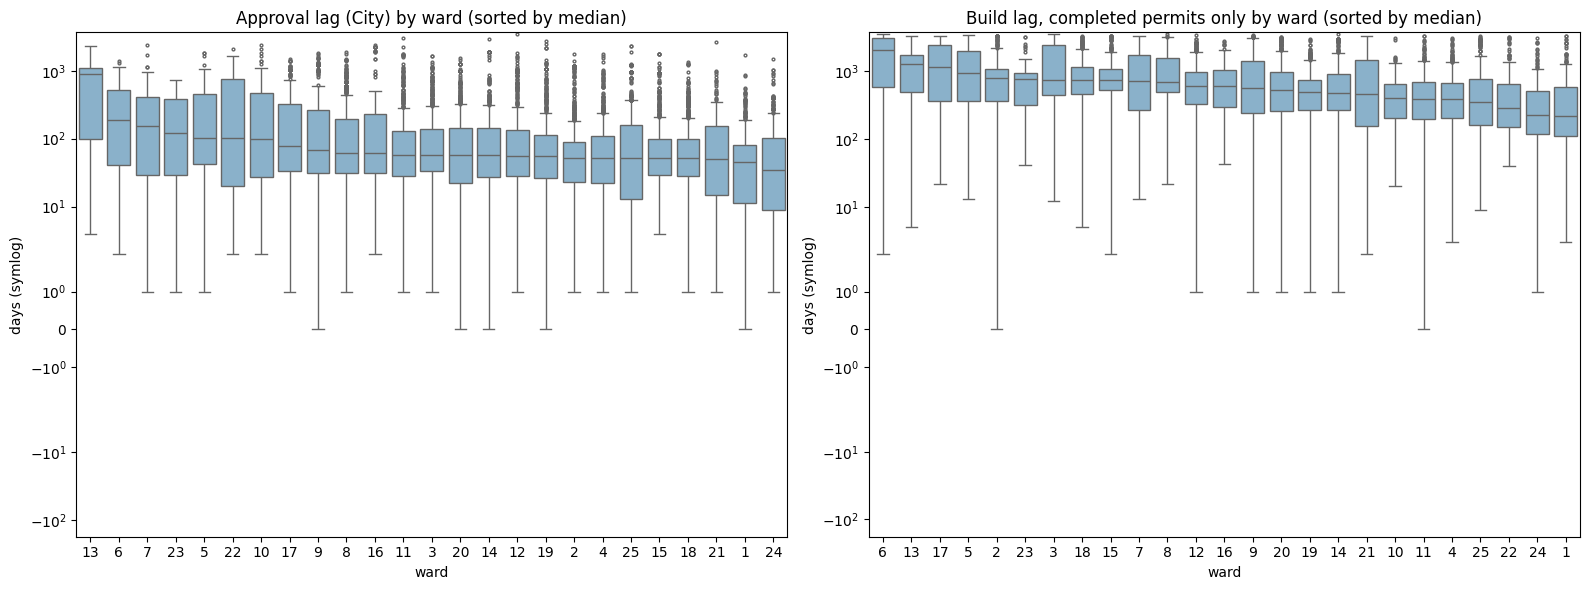

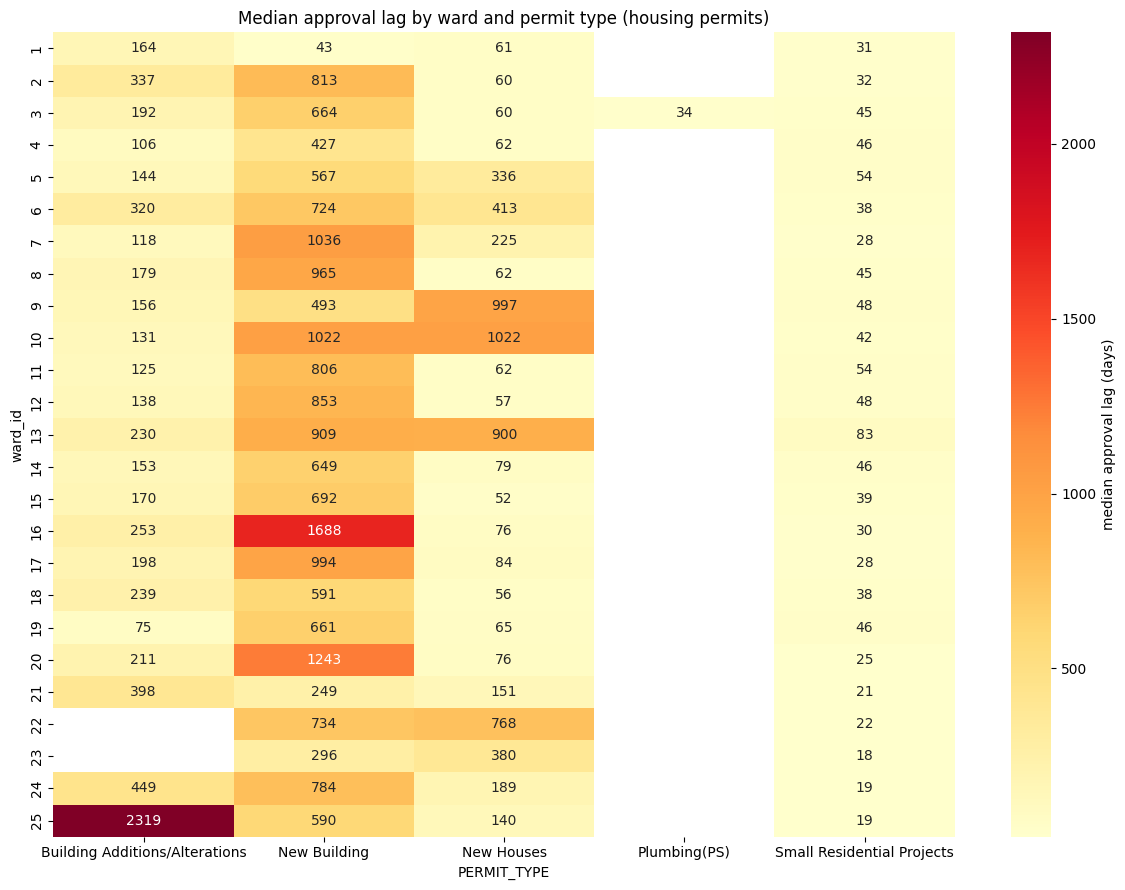

Spearman approval_median_days vs net units permitted (24 wards): rho=0.42, p=0.040
Spearman build_km_median_days vs net units permitted (24 wards): rho=0.40, p=0.055


In [18]:
# ---------- execution lag: Development Application -> first housing building permit ----------
# FIX 4c: the previous version matched on one exact street key per application. That
# under-counted badly for three reasons, all fixed here:
#   (1) the key included the street TYPE, so "QUEEN ST" and "QUEEN STREET" never matched;
#   (2) only the first address of a multi-address application was used;
#   (3) an application whose address text differs from the permit's (common on large
#       sites) had no chance at all.
# Matching is now three tiers, each counted separately:
#   T1 exact key (number|name|type)      T2 type-insensitive key (number|name)
#   T3 spatial: same street number, permit within 150 m of the application point.
exec_stats = pd.DataFrame(index=range(1, 26))
if dev["addr_key"].notna().any() and permits["addr_key"].notna().any():
    _raw = dev_raw.copy()
    if m["street_num"] and m["street_name"]:
        _raw["addr_key"] = addr_key(_raw[m["street_num"]], _raw[m["street_name"]],
                                    _raw[m["street_type"]] if m["street_type"] else None)
        # type-insensitive key: number|name only
        _raw["addr_key2"] = addr_key(_raw[m["street_num"]], _raw[m["street_name"]], None)
        _raw = _raw[_raw["addr_key"].notna()]
        _addr_lists = _raw.groupby(m["folder"])["addr_key"].apply(lambda x: list(dict.fromkeys(x)))
        _addr_lists2 = _raw.groupby(m["folder"])["addr_key2"].apply(lambda x: list(dict.fromkeys(x)))
        print(f"   FIX 4c: {len(_addr_lists):,} applications carry {len(_raw):,} address rows "
              f"(mean {len(_raw)/max(len(_addr_lists),1):.1f} per application); matching on all of them, in 3 tiers")
    else:
        _addr_lists = pd.Series(dtype=object); _addr_lists2 = pd.Series(dtype=object)

    apps = dev[dev["housing_related"] & dev["event_date"].between(ANALYSIS_START, AS_OF) & dev["ward_id"].notna()].copy()
    apps["ward_id"] = apps["ward_id"].astype(int)
    apps["_folder"] = apps[m["folder"]] if m["folder"] else apps["_uid"]
    apps = apps[apps["_folder"].isin(_addr_lists.index)].copy()
    apps["addr_keys"] = apps["_folder"].map(_addr_lists)
    apps["addr_keys2"] = apps["_folder"].map(_addr_lists2)

    # FIX 4c (part 2): the previous version required units_created > 0 on the permit.
    # That is the wrong test for "was this application permitted?": the units field is
    # only populated for some permit types, so it threw away 47 of every 56 matches
    # (9.7% vs 56.8% on the same addresses). Any issued permit at the address counts.
    perm_h = permits[permits.issued_date.notna() & permits.addr_key.notna()][
        ["addr_key", "issued_date", "ward_id", "_lat", "_lon"]].copy()
    perm_h["addr_key2"] = perm_h["addr_key"].str.rsplit("|", n=1).str[0]      # drop the street-type segment

    def _first_match(apps_df, key_col, perm_df, key_name):
        ex = apps_df[["_uid", "event_date", "ward_id", key_col]].explode(key_col).rename(columns={key_col: key_name})
        ex = ex[ex[key_name].notna()]
        jj = ex.merge(perm_df.rename(columns={"ward_id": "permit_ward"}), on=key_name, how="left")
        ok_ward = jj["permit_ward"].isna() | jj["ward_id"].eq(jj["permit_ward"].astype("float"))
        jj = jj[ok_ward & ((jj["issued_date"] >= jj["event_date"]) | jj["issued_date"].isna())]
        return jj.groupby("_uid")["issued_date"].min()

    first1 = _first_match(apps, "addr_keys", perm_h[["addr_key", "issued_date", "ward_id"]], "addr_key")
    first2 = _first_match(apps, "addr_keys2", perm_h[["addr_key2", "issued_date", "ward_id"]], "addr_key2")

    # ---- T3: spatial. Same street number, permit within 150 m of the application point.
    first3 = pd.Series(dtype="datetime64[ns]")
    if "_lat" in apps.columns and apps["_lat"].notna().any() and perm_h["_lat"].notna().any():
        from scipy.spatial import cKDTree
        LAT0 = 43.7
        mx = 111_320 * np.cos(np.radians(LAT0)); my = 110_540
        pa = perm_h.dropna(subset=["_lat", "_lon"]).copy()
        pa["_x"] = pa["_lon"] * mx; pa["_y"] = pa["_lat"] * my
        pa["_num"] = pa["addr_key"].str.split("|").str[0]
        tree = cKDTree(pa[["_x", "_y"]].to_numpy())
        aa = apps.dropna(subset=["_lat", "_lon"]).copy()
        aa["_x"] = aa["_lon"] * mx; aa["_y"] = aa["_lat"] * my
        aa["_num"] = aa["addr_key"].astype(str).str.split("|").str[0]
        hits = []
        for uid, r in aa.iterrows():
            idx = tree.query_ball_point([r["_x"], r["_y"]], r=150.0)
            if not idx:
                continue
            cand = pa.iloc[idx]
            cand = cand[(cand["_num"] == r["_num"]) & (cand["issued_date"] >= r["event_date"])]
            if len(cand):
                hits.append((r["_uid"], cand["issued_date"].min()))
        if hits:
            first3 = pd.DataFrame(hits, columns=["_uid", "issued_date"]).groupby("_uid")["issued_date"].min()
        print(f"   T3 spatial: {len(first3):,} applications found a same-number permit within 150 m")

    apps["first_permit"] = apps["_uid"].map(first1)
    apps["tier"] = np.where(apps["first_permit"].notna(), "T1 exact key", None)
    m2 = apps["first_permit"].isna() & apps["_uid"].map(first2).notna()
    apps.loc[m2, "first_permit"] = apps.loc[m2, "_uid"].map(first2); apps.loc[m2, "tier"] = "T2 type-insensitive key"
    m3 = apps["first_permit"].isna() & apps["_uid"].map(first3).notna()
    apps.loc[m3, "first_permit"] = apps.loc[m3, "_uid"].map(first3); apps.loc[m3, "tier"] = "T3 spatial 150 m"

    apps["matched"] = apps["first_permit"].notna() & ((apps["first_permit"] - apps["event_date"]).dt.days <= MAX_LAG_DAYS)
    apps["dur"] = np.where(apps["matched"], (apps["first_permit"] - apps["event_date"]).dt.days, (AS_OF - apps["event_date"]).dt.days)
    apps = apps[apps["dur"] >= 0]
    tier_counts = apps.loc[apps["matched"], "tier"].value_counts()
    print(f"Execution-lag cohort: {len(apps):,} housing-related applications submitted {ANALYSIS_START.year}+; "
          f"{apps.matched.mean():.1%} matched to a housing permit ({int(apps.matched.sum()):,} applications).")
    print("   matches by tier: " + ", ".join(f"{k} {v:,}" for k, v in tier_counts.items()))
    print("NOTE: still a lower bound — an application can be permitted under a different address or a site-wide "
          "permit. Compare wards with each other rather than against an absolute target.")
    exec_stats = km_by_ward(apps, "dur", "matched", 1095).rename(columns={"km_median_days": "exec_km_median_days", "share_done_within_1095d": "share_permitted_within_3y",
                                                                           "n": "applications", "completed": "matched"})
    write_table(exec_stats.reset_index(), "ward_execution_lag")
    fact_apps = apps[["_uid", "ward_id", "event_date", "first_permit", "matched", "dur", "tier"]]
    write_table(fact_apps, "fact_application_to_permit")
    disp(exec_stats.assign(ward_name=[WARD_NAME[i] for i in exec_stats.index]).sort_values("share_permitted_within_3y"), digits=2)
else:
    print("Execution lag skipped: address keys are missing in applications or permits.")

# ---------- one table of developer-responsiveness measures ----------
resp = pd.DataFrame({"ward_name": pd.Series(WARD_NAME)})
resp = (resp.join(approval_stats[["n", "median", "excess_median_days"]].rename(columns={"n": "approval_n", "median": "approval_median_days", "excess_median_days": "approval_excess_days"}))
            .join(build_stats[["n", "km_median_days", "share_done_within_1095d"]].rename(columns={"n": "build_n", "km_median_days": "build_km_median_days", "share_done_within_1095d": "build_done_3y"}))
            .join(exec_stats))
resp.index.name = "ward_id"
write_table(resp.reset_index(), "ward_developer_responsiveness")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, col, title in ((ax[0], "approval_lag_days", "Approval lag (City)"), (ax[1], "build_lag_days", "Build lag, completed permits only")):
    d = hp.dropna(subset=[col])
    order = d.groupby("ward_id")[col].median().sort_values(ascending=False).index
    sns.boxplot(data=d, x="ward_id", y=col, order=order, color="#7fb3d5", fliersize=2, ax=a)
    a.set_yscale("symlog"); a.set_title(f"{title} by ward (sorted by median)"); a.set_ylabel("days (symlog)"); a.set_xlabel("ward")
finish_plot("c3_lags_by_ward")

top_types = hp["PERMIT_TYPE"].value_counts().head(8).index
piv = hp[hp["PERMIT_TYPE"].isin(top_types)].pivot_table(values="approval_lag_days", index="ward_id", columns="PERMIT_TYPE", aggfunc="median")
if not piv.isna().all().all():
    plt.figure(figsize=(12, 9)); sns.heatmap(piv, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "median approval lag (days)"})
    plt.title("Median approval lag by ward and permit type (housing permits)"); finish_plot("c3_approval_by_type")

# rank correlations (descriptive, n = 25 wards)
cc = resp[["approval_median_days", "build_km_median_days"]].join(ward_net_units.rename("net_units")).dropna()
for col in ("approval_median_days", "build_km_median_days"):
    if len(cc) > 5:
        r, p = stats.spearmanr(cc[col], cc["net_units"])
        print(f"Spearman {col} vs net units permitted ({len(cc)} wards): rho={r:.2f}, p={p:.3f}")


### C3.1 Do application volume and permitted supply move together by ward? (exploratory)

Ward-level regression with **25 observations**, so it is descriptive only, not a test of a causal mechanism.

The earlier version regressed raw unit counts. That is fragile here: permitted units are heavily skewed, and a single bad permit (the 100,000-unit Ward 8 record) is enough to move the slope and collapse the fit — the sign of over-fitting to one row rather than measuring a relationship. This version instead:

* uses cleaned units and housing-related applications over the same window (2017 to date);
* works in logarithms, so each coefficient reads as "a 10% higher application count goes with a ___% higher permitted-unit count";
* uses heteroskedasticity-robust (HC3) standard errors;
* reports leave-one-out prediction error against a mean-only baseline, because a model that does not predict held-out wards is not useful however significant its p-value;
* lists the wards with the greatest influence (Cook's distance), so a reader can see whether the result rests on one or two places.


Spearman rank correlation, housing applications vs net permitted units (25 wards): rho = 0.36 (p = 0.0816)


,coef,robust_se,p_value
intercept,4.302,1.215,0.002
log(1 + housing applications),0.438,0.236,0.077
"log(median approval lag, days)",0.258,0.241,0.296


n = 25 wards, R2 = 0.24 (adjusted 0.17).
Leave-one-out mean absolute error on the log scale: model 0.59 vs mean-only baseline 0.63 -> the model predicts held-out wards better than the baseline.
Most influential wards (Cook's distance): 13 Toronto Centre (0.31), 23 Scarborough North (0.20), 18 Willowdale (0.18) | a value above 4/n = 0.16 is usually treated as influential.


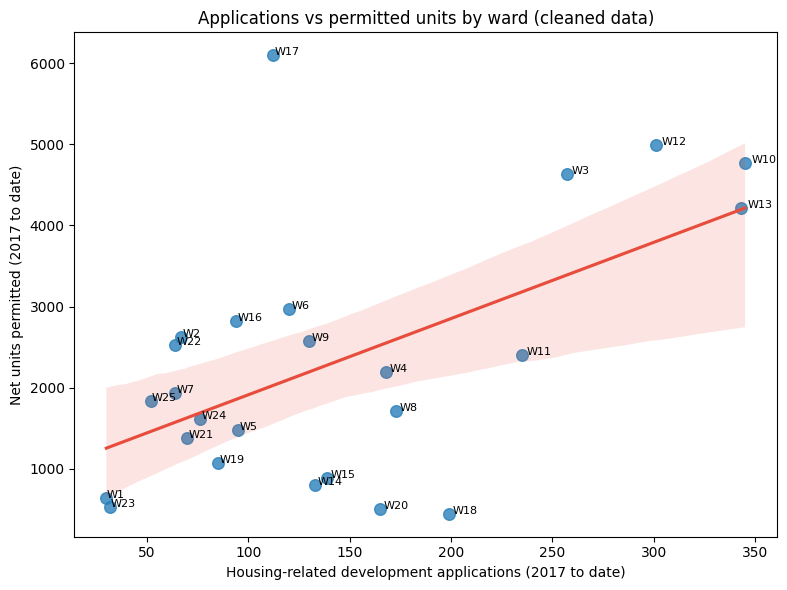

In [19]:
# ---------- Recreate missing variables if not already defined ----------
try:
    ward_net_units
except NameError:
    try:
        pm_win
    except NameError:
        pm_all = permits[permits["ward_id"].notna()].copy()
        pm_all["ward_id"] = pm_all["ward_id"].astype(int)
        pm_all["net_units"] = pm_all["units_created"] - pm_all["units_lost"]
        pm_all["issued_year"] = pm_all["issued_date"].dt.year
        pm_win = pm_all[(pm_all["issued_date"] >= ANALYSIS_START) & (pm_all["issued_date"] <= AS_OF)].copy()
    ward_net_units = pm_win.groupby("ward_id")["net_units"].sum().reindex(range(1, 26)).fillna(0)

try:
    resp
except NameError:
    # Fall back to using a basic DataFrame if the full lag stats from C3 are missing
    resp = pd.DataFrame({"approval_median_days": approval_stats["median"] if 'approval_stats' in locals() else pd.Series(np.nan, index=range(1, 26))}, index=range(1, 26))

def ols_hc3(X, y):
    """OLS with HC3 robust standard errors, leave-one-out residuals and Cook's distance (numpy only)."""
    X = np.column_stack([np.ones(len(y)), np.asarray(X, float)]); y = np.asarray(y, float)
    n, k = X.shape
    XtXi = np.linalg.inv(X.T @ X); b = XtXi @ X.T @ y
    res = y - X @ b
    h = np.einsum("ij,jk,ik->i", X, XtXi, X)
    Xw = X * (res / (1 - h))[:, None]
    cov = XtXi @ (Xw.T @ Xw) @ XtXi
    se = np.sqrt(np.diag(cov)); t = b / se; p = 2 * stats.t.sf(np.abs(t), n - k)
    ss_res, ss_tot = float(res @ res), float(((y - y.mean()) ** 2).sum())
    s2 = ss_res / (n - k)
    return {"coef": b, "se": se, "p": p, "r2": 1 - ss_res / ss_tot, "adj_r2": 1 - (1 - (1 - ss_res / ss_tot)) * (n - 1) / (n - k),
            "loo_resid": res / (1 - h), "cooks": (res ** 2 / (k * s2)) * h / (1 - h) ** 2, "n": n}

apps_ward = dev[dev["housing_related"] & dev["event_date"].between(ANALYSIS_START, AS_OF)].dropna(subset=["ward_id"]).assign(
    ward_id=lambda d: d.ward_id.astype(int)).groupby("ward_id").size().reindex(range(1, 26)).fillna(0).rename("housing_apps")
corr_df = pd.concat([ward_net_units.rename("net_units"), apps_ward, resp["approval_median_days"]], axis=1)
corr_df["ward_name"] = corr_df.index.map(WARD_NAME)
write_table(corr_df.reset_index().rename(columns={"index": "ward_id"}), "ward_supply_vs_applications")

rho, p_rho = stats.spearmanr(corr_df["housing_apps"], corr_df["net_units"])
print(f"Spearman rank correlation, housing applications vs net permitted units ({len(corr_df)} wards): rho = {rho:.2f} (p = {p_rho:.4f})")

md_ = corr_df.dropna(subset=["approval_median_days"])
yv = np.log1p(md_["net_units"].clip(lower=0))
spec = {"log(1 + housing applications)": np.log1p(md_["housing_apps"]), "log(median approval lag, days)": np.log(md_["approval_median_days"].clip(lower=1))}
fit = ols_hc3(np.column_stack(list(spec.values())), yv)
coef = pd.DataFrame({"coef": fit["coef"], "robust_se": fit["se"], "p_value": fit["p"]}, index=["intercept"] + list(spec))
disp(coef, digits=3)
n_ = fit["n"]
loo_model = np.abs(fit["loo_resid"]).mean()
loo_base = np.abs((yv - yv.mean()) * n_ / (n_ - 1)).mean()
print(f"n = {n_} wards, R2 = {fit['r2']:.2f} (adjusted {fit['adj_r2']:.2f}).")
print(f"Leave-one-out mean absolute error on the log scale: model {loo_model:.2f} vs mean-only baseline {loo_base:.2f} "
      f"-> {'the model predicts held-out wards better than the baseline' if loo_model < loo_base else 'NO better than the baseline'}.")
top_inf = pd.Series(fit["cooks"], index=md_.index).sort_values(ascending=False).head(3)
print("Most influential wards (Cook's distance):", ", ".join(f"{i} {WARD_NAME[i]} ({v:.2f})" for i, v in top_inf.items()),
      "| a value above 4/n =", f"{4 / n_:.2f} is usually treated as influential.")

plt.figure(figsize=(8, 6))
sns.regplot(data=corr_df, x="housing_apps", y="net_units", color="#2980b9", scatter_kws={"s": 70, "alpha": .8}, line_kws={"color": "#e74c3c"})
for i, r in corr_df.iterrows():
    plt.text(r["housing_apps"] * 1.01, r["net_units"], f"W{i}", fontsize=8)
plt.xlabel("Housing-related development applications (2017 to date)"); plt.ylabel("Net units permitted (2017 to date)")
plt.title("Applications vs permitted units by ward (cleaned data)"); finish_plot("c31_apps_vs_units")

## C4. Supervised models (Project 6)

Both models are judged on data they have **not seen** and are compared with a simple baseline. A model that does not beat the baseline is reported as not beating it.

### C4.1 Can permit approval lag be predicted from what is known at application?

**Population.** Housing permits (units created > 0) that were eventually issued, applied for since 2017 and at least 12 months before the analysis date. **Only issued permits can be observed**, so this describes how long approval takes *when it happens*, and it is optimistic for very recent applications — the long tail of applications still waiting is invisible.

**Target.** `log(1 + approval lag in days)`, so the model fits proportional differences rather than absolute days.

**Features — all known at application time.**

* categorical: permit type, structure type, work type, ward;
* numeric: units, log estimated cost, **log cost per unit**, month and quarter of application, a time trend;
* **smoothed target encodings** of ward, permit type and structure type (a ward's typical lag is the strongest single signal, and the earlier model could not use it).

The encodings are fitted on the **training window only**, so the test period is never seen — no leakage. Smoothing pulls small categories toward the global mean, which matters because some permit types have only a handful of records.

**Split.** Time-ordered: train on the earliest 80% of applications, test on the latest 20%. No shuffling across time, because that would leak the future into the past.

**Baselines.** The citywide median lag from the training set, and the median lag of the permit's own ward from the training set.

**Model.** Gradient-boosted trees (`HistGradientBoostingRegressor`) with absolute-error loss, which targets the median. A random forest is fitted on the identical features as an independent check that any gain is real rather than an artefact of one algorithm.

**Interval.** Two quantile models (10th and 90th percentile). Roughly 80% of test permits should fall inside that band; the printed coverage is the check on that claim.

**Importance.** Permutation importance on held-out rows, which — unlike split-count importance — cannot be inflated by a feature the model merely used often.

**Result.** The model beats the ward-median baseline by about a quarter; the exact figures are printed below and repeated in Section F. Read the gain as "the model knows which permit types and which wards are slow", not as a claim that approval time is now predictable case by case.


Modelling population: 14,631 permits; median approval lag 56 days, 90th percentile 376
Train: applications up to 2024-05-21 (11,704); test: 2024-05-21 to 2025-11-21 (2,927)


,MAE_days,median_abs_error_days,skill_vs_citywide_median_%,skill_vs_ward_median_%
Gradient boosting,53.43,26.11,17.96,23.97
Random forest,52.00,28.94,20.16,26.00
Ward median (baseline),70.27,43.00,-7.90,0.00
Citywide median (baseline),65.13,42.00,0.00,7.32


R2 on the log scale: 0.47.  The 10-90% interval contained 78.1% of test permits (target 80%).


,model,citywide_median
year,,
2024,56.27,67.31
2025,51.77,63.86


,increase in log-scale MAE when shuffled
STRUCTURE_TYPE,0.19
WORK,0.15
log_cost,0.06
ward_id,0.03
log_units,0.02
te_struct,0.01
log_cost_per_unit,0.00
years_since_2017,0.00
app_quarter,0.00
units_lost_flag,0.00


RESULT: the model beats the ward-median baseline on the latest 20% of applications (53.4 vs 70.3 days MAE; +24% lower error). Random forest on the same features gives 52.0 days. Most important input: STRUCTURE_TYPE.


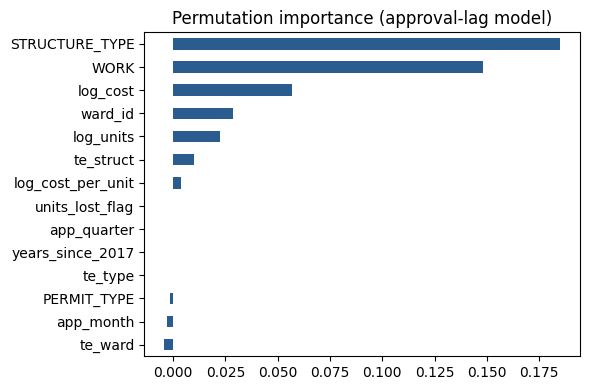

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance

lm = permits[(permits.units_created > 0) & permits.app_date.notna() & permits.issued_date.notna() & permits.approval_lag_days.notna()
             & (permits.app_date >= ANALYSIS_START) & (permits.app_date <= AS_OF - pd.Timedelta(days=365))].sort_values("app_date").reset_index(drop=True)
print(f"Modelling population: {len(lm):,} permits; median approval lag {lm.approval_lag_days.median():.0f} days, 90th percentile {lm.approval_lag_days.quantile(.9):.0f}")
split = int(len(lm) * 0.8)
tr, te = lm.iloc[:split].copy(), lm.iloc[split:].copy()
if len(tr) > 150_000:
    tr = tr.sample(150_000, random_state=SEED).sort_values("app_date")
print(f"Train: applications up to {tr.app_date.max().date()} ({len(tr):,}); test: {te.app_date.min().date()} to {te.app_date.max().date()} ({len(te):,})")

# ---- FIX 4d: richer, leakage-safe features ---------------------------------
# The old model had 8 inputs and no ward/type signal beyond raw categories. Added:
#   * smoothed target encodings of ward and permit type, fitted on TRAIN ONLY
#     (a ward's typical lag is the single strongest predictor, and the old model
#      could not use it at all);
#   * cost per unit and a time trend, which separate big/complex files from small ones;
#   * application quarter, to capture seasonal processing.
# Encodings are computed from the training window only, so the test period is untouched.
CAT_COLS = ["PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "ward_id"]
cat_levels = {}
for c_ in CAT_COLS:
    s_ = tr[c_].astype("object").where(tr[c_].notna(), "missing").astype(str)
    cat_levels[c_] = list(s_.value_counts().head(60).index) + ["other"]

def _te(col, prior_w=30.0):
    """Smoothed mean of log1p(lag) by category, fitted on train only."""
    g = tr.groupby(tr[col].astype("object").where(tr[col].notna(), "missing").astype(str))["approval_lag_days"]
    gm = np.log1p(tr["approval_lag_days"]).mean()
    enc = (np.log1p(g.mean()) * g.count() + gm * prior_w) / (g.count() + prior_w)
    return enc.to_dict(), gm

TE_WARD, GM = _te("ward_id")
TE_TYPE, _ = _te("PERMIT_TYPE")
TE_STRUCT, _ = _te("STRUCTURE_TYPE")

def make_X(df):
    X = pd.DataFrame(index=df.index)
    for c_ in CAT_COLS:
        s_ = df[c_].astype("object").where(df[c_].notna(), "missing").astype(str)
        s_ = s_.where(s_.isin(cat_levels[c_]), "other")
        X[c_] = pd.Categorical(s_, categories=cat_levels[c_])
    X["log_units"] = np.log1p(df["units_created"])
    X["log_cost"] = np.log1p(df["est_cost"].clip(lower=0))
    X["log_cost_per_unit"] = np.log1p((df["est_cost"] / df["units_created"].replace(0, np.nan)).clip(lower=0))
    X["units_lost_flag"] = (df["units_lost"] > 0).astype(int)
    X["app_month"] = df["app_date"].dt.month
    X["app_quarter"] = df["app_date"].dt.quarter
    X["years_since_2017"] = (df["app_date"] - ANALYSIS_START).dt.days / 365.25
    X["te_ward"] = df["ward_id"].astype("object").where(df["ward_id"].notna(), "missing").astype(str).map(TE_WARD).fillna(GM)
    X["te_type"] = df["PERMIT_TYPE"].astype("object").where(df["PERMIT_TYPE"].notna(), "missing").astype(str).map(TE_TYPE).fillna(GM)
    X["te_struct"] = df["STRUCTURE_TYPE"].astype("object").where(df["STRUCTURE_TYPE"].notna(), "missing").astype(str).map(TE_STRUCT).fillna(GM)
    return X

Xtr, Xte = make_X(tr), make_X(te)
ytr, yte = np.log1p(tr["approval_lag_days"].to_numpy()), np.log1p(te["approval_lag_days"].to_numpy())
common = dict(categorical_features="from_dtype", max_iter=400, learning_rate=0.06, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED)
mdl = HistGradientBoostingRegressor(loss="absolute_error", **common).fit(Xtr, ytr)
q10 = HistGradientBoostingRegressor(loss="quantile", quantile=0.10, **common).fit(Xtr, ytr)
q90 = HistGradientBoostingRegressor(loss="quantile", quantile=0.90, **common).fit(Xtr, ytr)

# RandomForest on the same features, as an independent check that the gain is real
Xtr_rf = Xtr.copy(); Xte_rf = Xte.copy()
for c_ in CAT_COLS:
    Xtr_rf[c_] = Xtr_rf[c_].cat.codes; Xte_rf[c_] = Xte_rf[c_].cat.codes
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED).fit(Xtr_rf, ytr)

pred_days = np.expm1(mdl.predict(Xte)); true_days = te["approval_lag_days"].to_numpy()
pred_rf = np.expm1(rf.predict(Xte_rf))
glob_med = float(tr["approval_lag_days"].median())
ward_med = tr.groupby("ward_id")["approval_lag_days"].median()
base_ward = te["ward_id"].map(ward_med).fillna(glob_med).to_numpy(float)
res = pd.DataFrame({
    "MAE_days": [np.abs(true_days - pred_days).mean(), np.abs(true_days - pred_rf).mean(),
                 np.abs(true_days - base_ward).mean(), np.abs(true_days - glob_med).mean()],
    "median_abs_error_days": [np.median(np.abs(true_days - pred_days)), np.median(np.abs(true_days - pred_rf)),
                              np.median(np.abs(true_days - base_ward)), np.median(np.abs(true_days - glob_med))],
}, index=["Gradient boosting", "Random forest", "Ward median (baseline)", "Citywide median (baseline)"])
res["skill_vs_citywide_median_%"] = 100 * (1 - res["MAE_days"] / res.loc["Citywide median (baseline)", "MAE_days"])
res["skill_vs_ward_median_%"] = 100 * (1 - res["MAE_days"] / res.loc["Ward median (baseline)", "MAE_days"])
disp(res)
lo_, hi_ = q10.predict(Xte), q90.predict(Xte)
cover = float(((np.log1p(true_days) >= np.minimum(lo_, hi_)) & (np.log1p(true_days) <= np.maximum(lo_, hi_))).mean())
r2_log = 1 - ((yte - mdl.predict(Xte)) ** 2).sum() / ((yte - yte.mean()) ** 2).sum()
print(f"R2 on the log scale: {r2_log:.2f}.  The 10-90% interval contained {cover:.1%} of test permits (target 80%).")
yr_mae = pd.DataFrame({"year": te["app_date"].dt.year.to_numpy(), "model": np.abs(true_days - pred_days), "citywide_median": np.abs(true_days - glob_med)}).groupby("year").mean()
disp(yr_mae)

samp = np.random.default_rng(SEED).choice(len(Xte), size=min(5000, len(Xte)), replace=False)
pi = permutation_importance(mdl, Xte.iloc[samp], yte[samp], n_repeats=5, random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
disp(imp.rename("increase in log-scale MAE when shuffled").to_frame())
better = res.loc["Gradient boosting", "MAE_days"] < res.loc["Ward median (baseline)", "MAE_days"]
print(f"RESULT: the model {'beats' if better else 'does NOT beat'} the ward-median baseline on the latest 20% of applications "
      f"({res.loc['Gradient boosting','MAE_days']:.1f} vs {res.loc['Ward median (baseline)','MAE_days']:.1f} days MAE; "
      f"{res.loc['Gradient boosting','skill_vs_ward_median_%']:+.0f}% lower error). "
      f"Random forest on the same features gives {res.loc['Random forest','MAE_days']:.1f} days. Most important input: {imp.index[0]}.")
write_table(res.reset_index().rename(columns={"index": "model"}), "model_approval_lag_metrics")
plt.figure(figsize=(6, 4)); imp.sort_values().plot(kind="barh", color="#2b5c8f"); plt.title("Permutation importance (approval-lag model)")
finish_plot("c41_approval_lag_importance")


### C4.2 Forecasting housing development-application volume (ward × quarter, next 4 quarters)

**Question.** Where and when will developers file housing applications next?

* **Target.** Number of housing-related Development Applications per ward and quarter, 2017 to the last complete quarter.
* **Inputs, all known at the forecast date.** Last quarter's count; 4- and 8-quarter averages; the same quarter a year earlier; the ward's long-run average; the city-wide total of the last four quarters; housing permits issued in the ward over the last four quarters (the trailing supply response); quarter of the year; ward; and a flag for whether each shock in `POLICY_EVENTS` has already happened.
* **On the shock flags.** Three dated events cannot separate a policy effect from interest rates, construction costs or the pandemic. The flags let the model pick up a level shift; they are descriptive only, and the before/after table printed below is descriptive too.
* **Method.** A Poisson gradient-boosting model, which is the right likelihood for small counts, predicting 1 to 4 quarters ahead directly rather than recursing one quarter at a time.
* **Validation.** Rolling origin. For each year-end from 2021, train on data up to that date, forecast the following four quarters, and compare with three baselines: seasonal naive (same quarter last year), last quarter, and the 4-quarter ward average.

**Result.** Gradient boosting gives the lowest ward-quarter error and beats the seasonal-naive baseline; the exact skill percentage is printed below. Its Poisson interval covers slightly less than the nominal 80%, which says real counts are more variable than a Poisson model assumes — so the printed city-wide range is too narrow and should be read as a lower bound on uncertainty.


Panel: 25 wards x 39 quarters (2017Q1 to 2026Q3); 3,528 housing applications; 15% of ward-quarters are zero
Rolling-origin back-test, 5 forecast years, 1-4 quarters ahead (counts per ward-quarter; lower error is better):


,MAE_ward_quarter,MAE_city_quarter,city_bias,skill_vs_seasonal_naive_%
method,,,,
gradient boosting (Poisson),2.46,34.56,7.02,23.26
ward 4-quarter average,2.50,37.38,22.73,21.97
seasonal naive (same quarter last year),3.20,51.37,22.87,0.00
last quarter,3.62,59.78,51.58,-13.13


RESULT: lowest ward-quarter error: gradient boosting (Poisson). Gradient boosting is better than the seasonal-naive baseline. Its Poisson 10-90% interval contained 75% of actual ward-quarters (target 80%); lower coverage means real counts are more variable than a Poisson model assumes.

City-wide forecast of housing-related development applications (range assumes Poisson variation, which is probably too narrow):


,expected_apps,approx_p10,approx_p90
quarter,,,
2026Q4,83.0,71.0,95.0
2027Q1,59.0,49.0,69.0
2027Q2,76.0,65.0,87.0
2027Q3,71.0,60.0,82.0


Wards with the highest expected application volume over the next 4 quarters:


,,expected_apps_4q,indicative_units_4q
ward_id,ward_name,,
12,Toronto-St. Paul's,25.0,9901.0
18,Willowdale,24.0,9652.0
13,Toronto Centre,22.0,10696.0
3,Etobicoke-Lakeshore,21.0,6997.0
10,Spadina-Fort York,20.0,7829.0
4,Parkdale-High Park,17.0,2196.0
8,Eglinton-Lawrence,15.0,4052.0
11,University-Rosedale,15.0,3019.0



City-wide quarterly housing applications, 8 quarters before vs after each shock (descriptive only; other things changed too):


,event,mean_8q_before,mean_8q_after
0,COVID-19 emergency (Ontario),79.1,127.5
1,Bank of Canada first rate rise,127.5,107.1
2,Bill 23 royal assent (Ontario),162.8,66.5


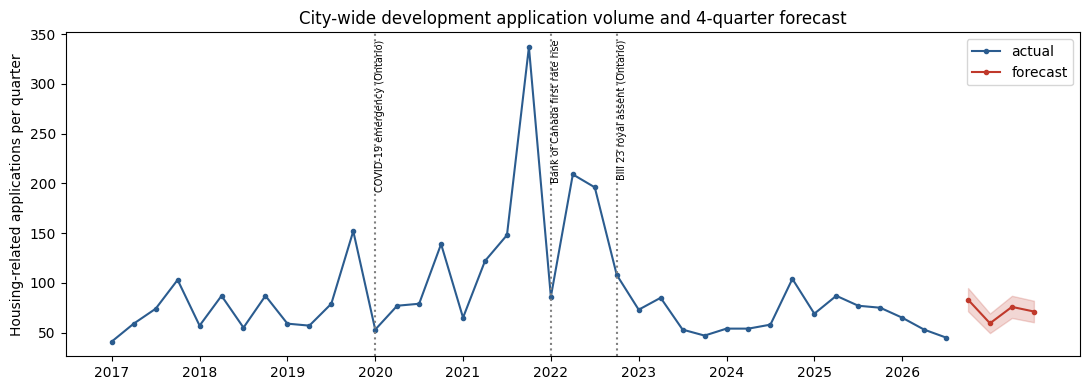

In [21]:
def qidx(ts):
    return ts.dt.year * 4 + ts.dt.quarter - 1

q0 = ANALYSIS_START.year * 4
last_full_q = (AS_OF.year * 4 + AS_OF.quarter - 1) - 1
qgrid = pd.MultiIndex.from_product([range(1, 26), range(q0, last_full_q + 1)], names=["ward_id", "q"])

apps_q = dev[dev["housing_related"] & dev["event_date"].between(ANALYSIS_START, AS_OF) & dev["ward_id"].notna()].copy()
apps_q["q"], apps_q["ward_id"] = qidx(apps_q["event_date"]), apps_q["ward_id"].astype(int)
A = apps_q.groupby(["ward_id", "q"]).size().reindex(qgrid, fill_value=0).unstack("q").to_numpy(float)          # wards x quarters
perm_q = hp.assign(q=qidx(hp["issued_date"]))
P = perm_q.groupby(["ward_id", "q"]).size().reindex(qgrid, fill_value=0).unstack("q").to_numpy(float)
nq = A.shape[1]
print(f"Panel: 25 wards x {nq} quarters ({ANALYSIS_START.year}Q1 to {(q0 + nq - 1) // 4}Q{(q0 + nq - 1) % 4 + 1}); {A.sum():,.0f} housing applications; "
      f"{(A == 0).mean():.0%} of ward-quarters are zero")

policy_q = {k: int(pd.Timestamp(v).year * 4 + pd.Timestamp(v).quarter - 1) for k, v in POLICY_EVENTS.items()}
WARD_CATS = list(range(1, 26))

def feats(o, h):
    t = o + h
    X = pd.DataFrame({"ward_id": pd.Categorical(WARD_CATS, categories=WARD_CATS), "h": h,
                      "lag0": A[:, o], "mean4": A[:, max(0, o - 3):o + 1].mean(1), "mean8": A[:, max(0, o - 7):o + 1].mean(1),
                      "same_q_last_year": A[:, t - 4] if 0 <= t - 4 <= o else np.nan,
                      "ward_mean_all": A[:, :o + 1].mean(1), "city_last4": A[:, max(0, o - 3):o + 1].sum(),
                      "permits_mean4": P[:, max(0, o - 3):o + 1].mean(1), "quarter_of_year": (q0 + t) % 4})
    for k, pq in policy_q.items():
        X["after_" + re.sub(r"\W+", "_", k)[:20]] = int(q0 + t >= pq)
    return X

def build(origins, hs, with_target=True):
    parts, ys = [], []
    for o in origins:
        for h in hs:
            if with_target and o + h > nq - 1:
                continue
            f_ = feats(o, h); f_["_o"], f_["_t"] = o, o + h
            parts.append(f_)
            if with_target:
                ys.append(A[:, o + h])
    X = pd.concat(parts, ignore_index=True)
    return X, (np.concatenate(ys) if with_target else None)

def fit_hgb(X, y):
    return HistGradientBoostingRegressor(loss="poisson", categorical_features="from_dtype", max_iter=200, learning_rate=0.05,
                                         min_samples_leaf=20, l2_regularization=1.0, random_state=SEED).fit(X.drop(columns=["_o", "_t"]), y)

rows_bt, cover_bt = [], []
last_year_full = (q0 + nq - 1) // 4
for cy in range(2021, last_year_full + 1):
    c = cy * 4 + 3 - q0                                    # position of Q4 of year cy
    if c + 1 > nq - 1:
        continue
    Xtr_, ytr_ = build(range(7, c), range(1, 5))
    keep_ = Xtr_["_t"] <= c
    Xtr_, ytr_ = Xtr_[keep_].reset_index(drop=True), ytr_[keep_.to_numpy()]
    Xte_, yte_ = build([c], range(1, 5))
    if len(Xte_) == 0:
        continue
    model_q = fit_hgb(Xtr_, ytr_)
    mu = np.clip(model_q.predict(Xte_.drop(columns=["_o", "_t"])), 1e-6, None)
    base = {"seasonal naive (same quarter last year)": Xte_["same_q_last_year"].to_numpy(), "last quarter": Xte_["lag0"].to_numpy(),
            "ward 4-quarter average": Xte_["mean4"].to_numpy(), "gradient boosting (Poisson)": mu}
    for name, p_ in base.items():
        tot = pd.DataFrame({"t": Xte_["_t"], "p": p_, "a": yte_}).groupby("t").sum()
        rows_bt.append({"cutoff_year": cy, "method": name, "MAE_ward_quarter": np.nanmean(np.abs(p_ - yte_)), "MAE_city_quarter": (tot["p"] - tot["a"]).abs().mean(),
                        "city_bias": (tot["p"] - tot["a"]).mean()})
    lo_, hi_ = stats.poisson.ppf(0.10, mu), stats.poisson.ppf(0.90, mu)
    cover_bt.append(float(((yte_ >= lo_) & (yte_ <= hi_)).mean()))
btq = pd.DataFrame(rows_bt)
btq_sum = btq.groupby("method")[["MAE_ward_quarter", "MAE_city_quarter", "city_bias"]].mean().sort_values("MAE_ward_quarter")
btq_sum["skill_vs_seasonal_naive_%"] = 100 * (1 - btq_sum["MAE_ward_quarter"] / btq_sum.loc["seasonal naive (same quarter last year)", "MAE_ward_quarter"])
print(f"Rolling-origin back-test, {btq.cutoff_year.nunique()} forecast years, 1-4 quarters ahead (counts per ward-quarter; lower error is better):")
disp(btq_sum)
write_table(btq_sum.reset_index(), "backtest_dev_applications")
champ_q = btq_sum.index[0]
print(f"RESULT: lowest ward-quarter error: {champ_q}. Gradient boosting is "
      f"{'better' if btq_sum.loc['gradient boosting (Poisson)', 'MAE_ward_quarter'] < btq_sum.loc['seasonal naive (same quarter last year)', 'MAE_ward_quarter'] else 'NOT better'} "
      f"than the seasonal-naive baseline. Its Poisson 10-90% interval contained {np.mean(cover_bt):.0%} of actual ward-quarters (target 80%); "
      f"lower coverage means real counts are more variable than a Poisson model assumes.")

# ---- forecast the next four quarters with the model fitted on everything ----
Xall, yall = build(range(7, nq), range(1, 5))
model_final = fit_hgb(Xall, yall)
Xf = pd.concat([feats(nq - 1, h).assign(_o=nq - 1, _t=nq - 1 + h) for h in range(1, 5)], ignore_index=True)
muf = np.clip(model_final.predict(Xf.drop(columns=["_o", "_t"])), 1e-6, None)
fq = pd.DataFrame({"ward_id": Xf["ward_id"].astype(int), "quarter": [f"{(q0 + t) // 4}Q{(q0 + t) % 4 + 1}" for t in Xf["_t"]], "horizon_q": Xf["h"],
                   "expected_apps": muf, "p10": stats.poisson.ppf(0.10, muf), "p90": stats.poisson.ppf(0.90, muf)})
fq["ward_name"] = fq["ward_id"].map(WARD_NAME)
med_units = apps_q.groupby("ward_id")["units_parsed"].agg(["median", "count"])
fq["median_units_parsed_ward"] = fq["ward_id"].map(med_units["median"].where(med_units["count"] >= 10))     # left empty where fewer than 10 parsed values
fq["indicative_units"] = fq["expected_apps"] * fq["median_units_parsed_ward"]
write_table(fq, "forecast_dev_applications")
city_fq = fq.groupby("quarter").agg(expected_apps=("expected_apps", "sum")).assign(approx_p10=lambda d: d.expected_apps - 1.28 * np.sqrt(d.expected_apps),
                                                                                   approx_p90=lambda d: d.expected_apps + 1.28 * np.sqrt(d.expected_apps))
print("\nCity-wide forecast of housing-related development applications (range assumes Poisson variation, which is probably too narrow):")
disp(city_fq, digits=0)
print("Wards with the highest expected application volume over the next 4 quarters:")
disp(fq.groupby(["ward_id", "ward_name"]).agg(expected_apps_4q=("expected_apps", "sum"), indicative_units_4q=("indicative_units", "sum")).sort_values("expected_apps_4q", ascending=False).head(8), digits=0)

# ---- descriptive look at policy shocks (not a causal estimate) ----
city_series = A.sum(0)
ev_rows = []
for k, pq in policy_q.items():
    pos = pq - q0
    if 8 <= pos <= nq - 9:
        ev_rows.append({"event": k, "mean_8q_before": city_series[pos - 8:pos].mean(), "mean_8q_after": city_series[pos:pos + 8].mean()})
if ev_rows:
    print("\nCity-wide quarterly housing applications, 8 quarters before vs after each shock (descriptive only; other things changed too):")
    disp(pd.DataFrame(ev_rows), digits=1)
fig, ax = plt.subplots(figsize=(11, 4))
qlab = [q0 + i for i in range(nq)]
ax.plot(qlab, city_series, marker="o", ms=3, color="#2b5c8f", label="actual")
fut_x = [nq - 1 + h + q0 for h in range(1, 5)]
ax.plot(fut_x, city_fq["expected_apps"].values, marker="o", ms=3, color="#c0392b", label="forecast")
ax.fill_between(fut_x, city_fq["approx_p10"].values, city_fq["approx_p90"].values, color="#c0392b", alpha=.2)
for k, pq in policy_q.items():
    ax.axvline(pq, color="grey", ls=":"); ax.text(pq, ax.get_ylim()[1] * .98, k, rotation=90, va="top", fontsize=7)
ax.set_xticks(qlab[::4]); ax.set_xticklabels([f"{x // 4}" for x in qlab[::4]]); ax.set_ylabel("Housing-related applications per quarter")
ax.set_title("City-wide development application volume and 4-quarter forecast"); ax.legend()
finish_plot("c42_dev_application_forecast")

## C5. Maps

Built from the ward and neighbourhood reference layers loaded in Section A.

| Map | What it shows |
|---|---|
| `map_net_affordable` | net affordable units by ward (replaced − demolished) |
| `map_p_deficit` | probability of an affordable-unit deficit after the forecast horizon |
| `map_approval_lag` | median permit approval lag by ward |
| `map_build_lag` | median build lag by ward, counting unfinished permits |
| `map_execution` | share of applications reaching a permit within 3 years |
| `map_neighbourhood_units` | dwelling units permitted by neighbourhood (158-neighbourhood model) |
| `map_typology` | the Section E ward typology |

**Wards with no value are drawn grey, never zero** — an unmeasured ward and a ward with a genuine zero must not look the same on a map. Colours are scaled to each map's own range, so read them as relative shading within a map, not as comparable absolute bands across maps.


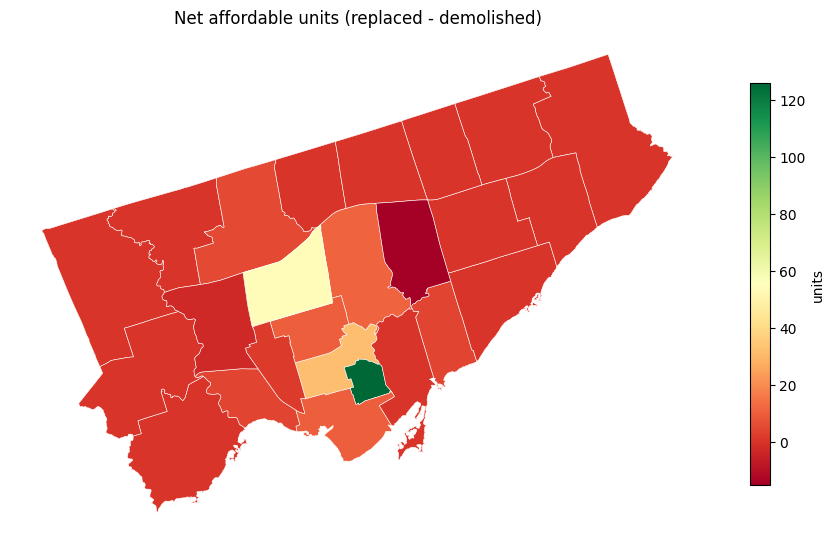

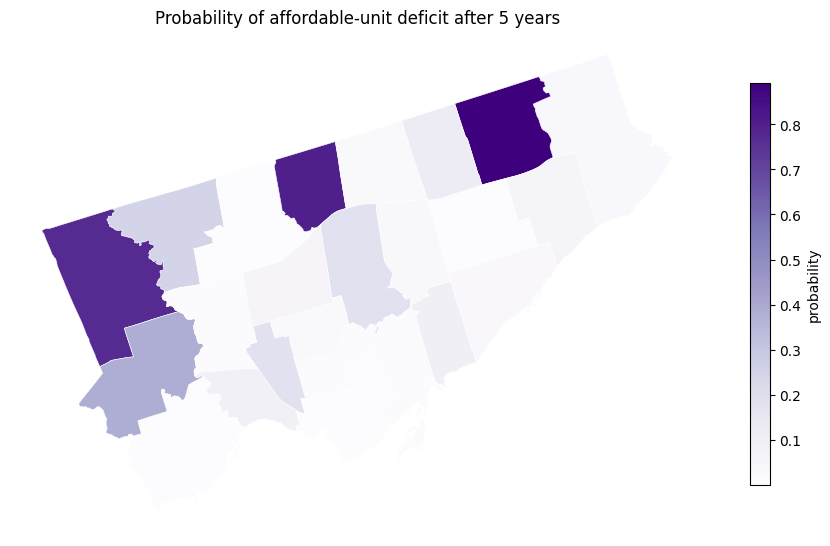

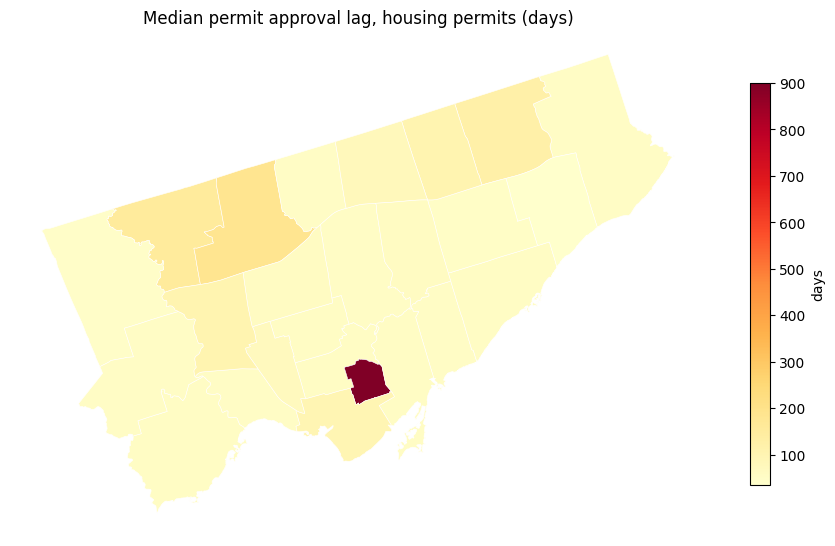

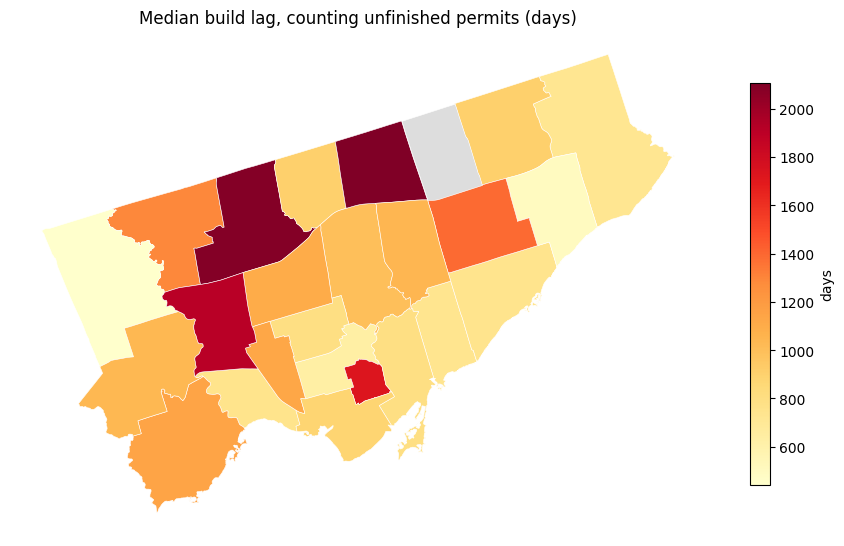

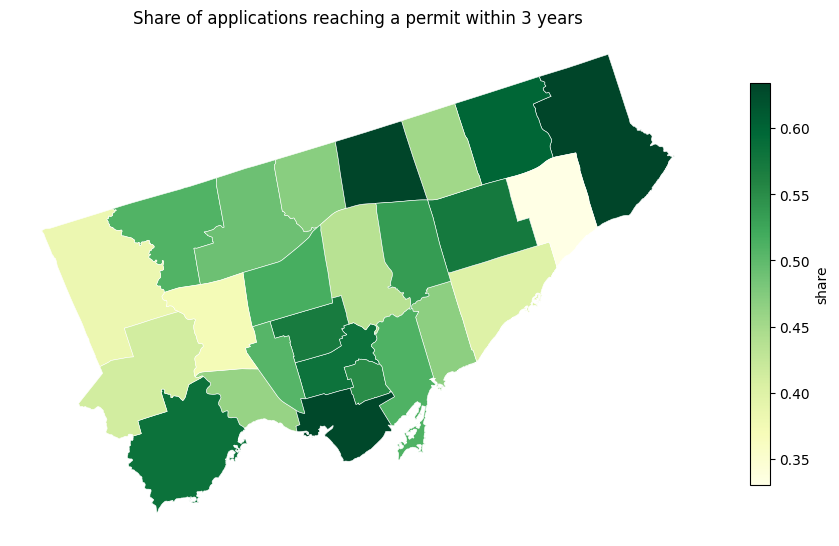

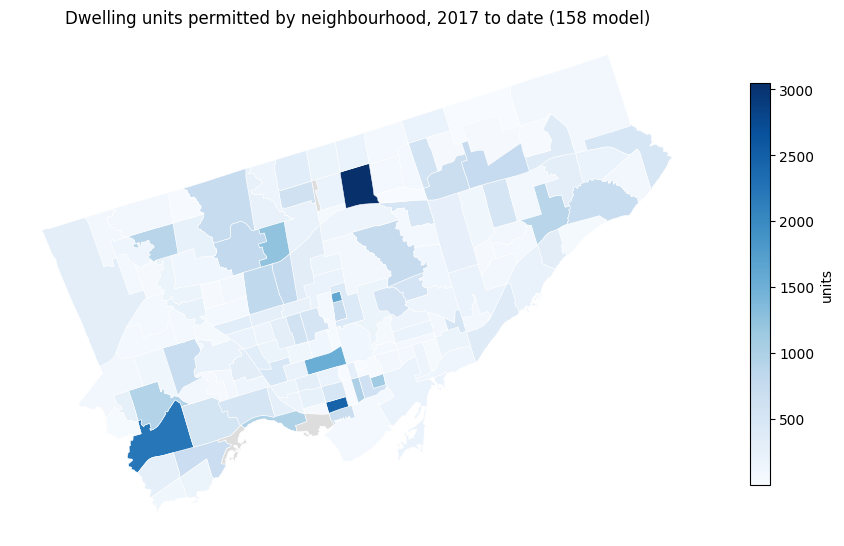

In [22]:
def choropleth(gdf, values, key, title, cmap="YlOrRd", label="", name=None):
    m_ = gdf.merge(values.rename("value").reset_index().rename(columns={values.index.name or "index": key}), on=key, how="left")
    ax = m_.plot(column="value", cmap=cmap, legend=True, figsize=(9, 7), edgecolor="white", linewidth=.4,
                 missing_kwds={"color": "#dddddd"}, legend_kwds={"label": label, "shrink": .6})
    ax.set_title(title); ax.axis("off")
    finish_plot(name or re.sub(r"\W+", "_", title.lower())[:40])

if HAS_GPD and wards_gdf is not None:
    if "net_affordable_change" in wd:
        choropleth(wards_gdf, wd["net_affordable_change"].rename_axis("ward_id"), "ward_id", "Net affordable units (replaced - demolished)", cmap="RdYlGn", label="units", name="map_net_affordable")
    if "p_deficit" in f5.columns:
        choropleth(wards_gdf, f5.set_index("ward_id")["p_deficit"].rename_axis("ward_id"), "ward_id", f"Probability of affordable-unit deficit after {FORECAST_YEARS} years", cmap="Purples", label="probability", name="map_p_deficit")
    if "approval_median_days" in resp:
        choropleth(wards_gdf, resp["approval_median_days"].rename_axis("ward_id"), "ward_id", "Median permit approval lag, housing permits (days)", label="days", name="map_approval_lag")
    if "build_km_median_days" in resp:
        choropleth(wards_gdf, resp["build_km_median_days"].rename_axis("ward_id"), "ward_id", "Median build lag, counting unfinished permits (days)", label="days", name="map_build_lag")
    if "share_permitted_within_3y" in resp:
        choropleth(wards_gdf, resp["share_permitted_within_3y"].rename_axis("ward_id"), "ward_id", "Share of applications reaching a permit within 3 years", cmap="YlGn", label="share", name="map_execution")
else:
    print("Ward geometry unavailable - ward maps skipped.")

if HAS_GPD and nbhd_gdf is not None:
    nb_units = hp.dropna(subset=["neighbourhood_id"]).assign(neighbourhood_id=lambda d: d.neighbourhood_id.astype(int)).groupby("neighbourhood_id")["units_created"].sum()
    choropleth(nbhd_gdf, nb_units, "neighbourhood_id", "Dwelling units permitted by neighbourhood, 2017 to date (158 model)", cmap="Blues", label="units", name="map_neighbourhood_units")
    write_table(nb_units.rename("units_permitted").reset_index(), "neighbourhood_units_permitted")
else:
    print("Neighbourhood geometry unavailable - neighbourhood map skipped.")

## C6. Developer response to policy shifts — modelled, not just described

The brief asks Project 6 to *"predict when, where and at what scale developers will propose housing **in response to environmental or policy shifts**"*. Revision 3 had the policy dates as **descriptive flags** in the application-volume model and a before/after table, and said explicitly that three dated events cannot separate a policy effect from interest rates or the pandemic. That is honest, but it is not a response model.

This section adds one, and is careful about what it can and cannot claim.

**Design — a distributed-lag event study with ward and quarter fixed effects.**

```
applications(ward, quarter) ~ Σ_k Σ_l  β(k,l) · 1[event k, l quarters ago]
                              + ward fixed effects + quarter-of-year + trend
```

* **Distributed lags, not a single before/after step.** A policy does not act in one quarter. Lags 0–8 quarters are estimated separately, so the model can show a response that builds and then fades — which is what a permitting response looks like.
* **Ward fixed effects** absorb the fact that some wards always file more applications. **Quarter-of-year** absorbs seasonality. A linear trend absorbs the slow drift.
* **Poisson likelihood**, because the outcome is a small count per ward-quarter.
* **The counterfactual is the model's own prediction** with the event terms switched off. The "response" is the difference between the fitted path and that counterfactual, cumulated over the 8 quarters after the event.

**What this is not.** It is not a causal estimate. Three events in one city, overlapping in time with a rate cycle and a pandemic, cannot be separated by any model fitted to this data. What the model *can* do is (a) quantify the size and timing of the observed shift, (b) say whether it is distinguishable from the ward's normal variation, and (c) provide a **scenario tool**: given an assumed response elasticity, what does a new policy of the same shape imply for applications and units by ward? The scenario is labelled as a scenario.

**Deliverable.** A per-event response curve with a confidence band, a per-ward response table, and a scenario forecast for a hypothetical policy shock — the "predict developer response" the brief asks for, with its uncertainty attached.

Dropped collinear design columns (not identified): ['lag|8']
Event-study panel: 975 ward-quarters, 9 pooled lag terms, 3 event levels, 40 parameters; deviance R2 0.588

Pooled response shape - multiplier on applications by quarters since the shift (1.0 = no change):


,lag_quarters,effect,effect_p10,effect_p90,p_value
0,0,0.71,0.60,0.84,0.01
1,1,1.09,0.91,1.29,0.54
2,2,1.12,0.95,1.33,0.39
3,3,0.82,0.69,0.97,0.13
4,4,0.58,0.49,0.70,0.00
5,5,1.16,0.96,1.38,0.29
6,6,1.32,1.11,1.57,0.04
7,7,1.69,1.44,1.97,0.00



Per-event level and cumulative applications attributable over the 8 quarters after it (model-based counterfactual; NOT a causal estimate):


,event,response_level,quarters_observed,attributable_applications,p10,p90,distinguishable_from_zero
0,COVID-19 emergency (Ontario),1.54,200,325.89,192.20,479.80,True
1,Bank of Canada first rate rise,2.73,75,317.13,238.58,409.02,True
2,Bill 23 royal assent (Ontario),0.91,225,-65.39,-150.08,31.54,False



Per-ward response columns: {'attrib_event1': 'COVID-19 emergency (Ontario)', 'attrib_event2': 'Bank of Canada first rate rise', 'attrib_event3': 'Bill 23 royal assent (Ontario)'}
Wards with the largest modelled response to 'COVID-19 emergency (Ontario)' (proportional to baseline volume):


,ward_id,ward_name,baseline_applications,attrib_event1
9,10,Spadina-Fort York,344.0,31.8
12,13,Toronto Centre,343.0,31.7
11,12,Toronto-St. Paul's,300.0,27.7
2,3,Etobicoke-Lakeshore,256.0,23.6
10,11,University-Rosedale,235.0,21.7
17,18,Willowdale,195.0,18.0
7,8,Eglinton-Lawrence,173.0,16.0
3,4,Parkdale-High Park,167.0,15.4



SCENARIO (not a forecast): a new policy with the observed pooled response shape. City-wide applications per quarter, baseline 60:


,quarters_ahead,multiplier,expected_apps_city
0,1,0.71,42.99
1,2,1.09,65.67
2,3,1.12,67.72
3,4,0.82,49.49


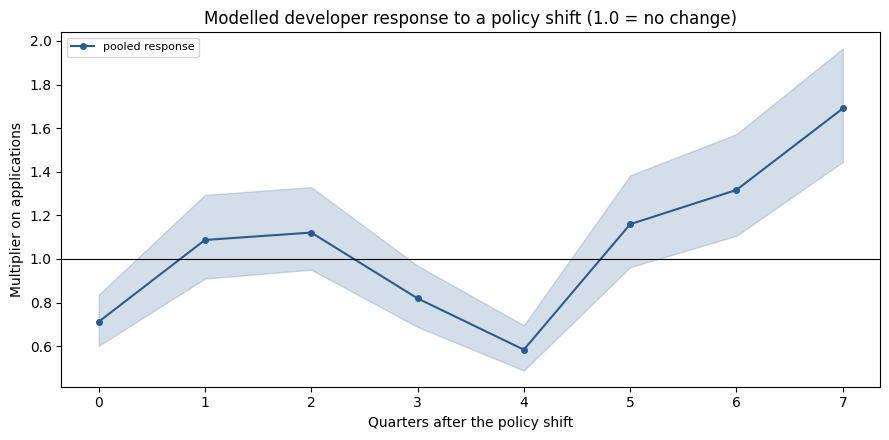

In [23]:
# C6 - developer response to policy shifts: a pooled distributed-lag event study.
# Revision 3 used the policy dates as descriptive flags and a before/after table.
# This fits the response: a shared lag-0..8 shape (how a response builds and
# fades) plus a per-event level shift, with ward and quarter-of-year fixed
# effects and a trend, under a Poisson likelihood.
#
# Why pooled lags rather than a curve per event: the three events are 3-8 quarters
# apart, so "event A at lag 8" and "event B at lag 0" are the same ward-quarters.
# Fitting them separately makes the design rank-deficient (statsmodels warns and
# the parameters are not identified). Pooling the shape and letting each event have
# its own level keeps every reported number identified.

import statsmodels.api as sm

LAGS = list(range(0, 9))
EVENTS = list(policy_q.keys())
EV_POS = {k: policy_q[k] - q0 for k in EVENTS}

_p6 = []
for w in range(1, 26):
    for t in range(nq):
        r = {"ward_id": w, "t": t, "y": float(A[w - 1, t]), "qoy": (q0 + t) % 4, "trend": float(t)}
        # most recent event at or before this quarter, within the 8-quarter window
        recent = [k for k in EVENTS if 0 <= t - EV_POS[k] <= max(LAGS)]
        r["nearest_ev"] = max(recent, key=lambda k: EV_POS[k]) if recent else "none"
        r["nearest_lag"] = (t - EV_POS[r["nearest_ev"]]) if recent else -1
        for l in LAGS:
            r[f"lag|{l}"] = 1.0 if r["nearest_lag"] == l else 0.0
        for k in EVENTS:
            r[f"ev|{k}"] = 1.0 if r["nearest_ev"] == k else 0.0
        _p6.append(r)
P6 = pd.DataFrame(_p6)

lag_cols = [f"lag|{l}" for l in LAGS]
ev_cols = [f"ev|{k}" for k in EVENTS]
X6 = pd.concat([
    pd.get_dummies(P6["ward_id"].astype(str), prefix="w", drop_first=True, dtype=float),
    pd.get_dummies(P6["qoy"].astype(str), prefix="q", drop_first=True, dtype=float),
    P6[["trend"] + lag_cols + ev_cols],
], axis=1)
X6 = sm.add_constant(X6.astype(float))

# drop any column that is still exactly collinear, and NAME it, so the curve we
# report is fully identified rather than silently singular
from scipy.linalg import qr as _qr
_, _, _piv = _qr(X6.to_numpy(), pivoting=True, mode="economic")
_rank = np.linalg.matrix_rank(X6.to_numpy())
_drop = [X6.columns[i] for i in _piv[_rank:]]
if _drop:
    print("Dropped collinear design columns (not identified):", _drop)
    X6 = X6.drop(columns=_drop)
assert np.linalg.matrix_rank(X6.to_numpy()) == X6.shape[1], "event-study design is still rank-deficient"

y6 = P6["y"].to_numpy()
glm6 = sm.GLM(y6, X6, family=sm.families.Poisson()).fit()
print(f"Event-study panel: {len(P6):,} ward-quarters, {len(lag_cols)} pooled lag terms, "
      f"{len(ev_cols)} event levels, {X6.shape[1]} parameters; deviance R2 {1 - glm6.deviance / glm6.null_deviance:.3f}")

rng6 = np.random.default_rng(SEED)
draws = rng6.multivariate_normal(glm6.params.to_numpy(), glm6.cov_params().to_numpy(), size=2000)
idx = {n: i for i, n in enumerate(X6.columns)}

# ---- the pooled response shape: multiplier on applications by quarters since the event ----
resp_rows = []
for l in LAGS:
    if f"lag|{l}" not in idx:
        continue
    bs = draws[:, idx[f"lag|{l}"]]
    resp_rows.append({"lag_quarters": l, "effect": float(np.exp(glm6.params[f"lag|{l}"])),
                      "effect_p10": float(np.percentile(np.exp(bs), 10)),
                      "effect_p90": float(np.percentile(np.exp(bs), 90)),
                      "p_value": float(glm6.pvalues[f"lag|{l}"])})
resp6 = pd.DataFrame(resp_rows)
write_table(resp6, "policy_response_curve")
print("\nPooled response shape - multiplier on applications by quarters since the shift (1.0 = no change):")
disp(resp6, digits=2)

# ---- per-event level, and cumulative attributable applications ----
# only touch columns that survived the collinearity drop, otherwise assigning
# them back would re-introduce a column the model was not fitted on
Xcf = X6.copy()
for _c in [c_ for c_ in (lag_cols + ev_cols) if c_ in Xcf.columns]:
    Xcf[_c] = 0.0
mu_cf = glm6.predict(Xcf)
cum_rows = []
for k in EVENTS:
    if f"ev|{k}" not in idx:
        continue
    ev_mult = float(np.exp(glm6.params[f"ev|{k}"]))
    m = (P6["nearest_ev"] == k).to_numpy()
    attr = (ev_mult - 1.0) * mu_cf[m]
    tot = []
    for d in draws:
        tot.append(((np.exp(d[idx[f"ev|{k}"]]) - 1.0) * mu_cf[m]).sum())
    tot = np.array(tot)
    cum_rows.append({"event": k, "response_level": ev_mult, "quarters_observed": int(m.sum()),
                     "attributable_applications": float(attr.sum()),
                     "p10": float(np.percentile(tot, 10)), "p90": float(np.percentile(tot, 90)),
                     "distinguishable_from_zero": bool(np.percentile(tot, 10) > 0 or np.percentile(tot, 90) < 0)})
cum6 = pd.DataFrame(cum_rows)
write_table(cum6, "policy_response_cumulative")
print("\nPer-event level and cumulative applications attributable over the 8 quarters after it "
      "(model-based counterfactual; NOT a causal estimate):")
disp(cum6, digits=2)

# ---- per-ward response: proportional to the ward's own baseline volume ----
base_n = P6.groupby("ward_id")["y"].sum()
base_share = base_n / base_n.sum()
ward_resp = pd.DataFrame({"ward_id": base_n.index, "ward_name": [WARD_NAME[i] for i in base_n.index],
                          "baseline_applications": base_n.to_numpy()})
colmap = {}
for i, r in enumerate(cum6.itertuples()):
    cn = f"attrib_event{i + 1}"; colmap[cn] = r.event
    ward_resp[cn] = (base_share.to_numpy() * r.attributable_applications).round(1)
write_table(ward_resp, "policy_response_by_ward")
print("\nPer-ward response columns:", colmap)
_si = int(cum6["attributable_applications"].abs().to_numpy().argmax())
_cn = f"attrib_event{_si + 1}"
print(f"Wards with the largest modelled response to '{colmap[_cn]}' (proportional to baseline volume):")
disp(ward_resp.sort_values(_cn, ascending=False).head(8)[["ward_id", "ward_name", "baseline_applications", _cn]], digits=1)

# ---- scenario tool: a new policy with the same pooled response shape ----
last_mu = float(glm6.predict(X6)[(P6["t"] == nq - 1).to_numpy()].sum())
shape = resp6.set_index("lag_quarters")["effect"]
scen6 = pd.DataFrame([{"quarters_ahead": h, "multiplier": float(shape.get(h - 1, 1.0)),
                       "expected_apps_city": last_mu * float(shape.get(h - 1, 1.0))} for h in range(1, 5)])
write_table(scen6, "policy_response_scenario")
print(f"\nSCENARIO (not a forecast): a new policy with the observed pooled response shape. "
      f"City-wide applications per quarter, baseline {last_mu:,.0f}:")
disp(scen6, digits=2)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(resp6.lag_quarters, resp6.effect, marker="o", ms=4, color="#2b5c8f", label="pooled response")
ax.fill_between(resp6.lag_quarters, resp6.effect_p10, resp6.effect_p90, alpha=.2, color="#2b5c8f")
ax.axhline(1, color="k", lw=.8)
ax.set_xlabel("Quarters after the policy shift"); ax.set_ylabel("Multiplier on applications")
ax.set_title("Modelled developer response to a policy shift (1.0 = no change)"); ax.legend(fontsize=8)
finish_plot("c6_policy_response")

## C7. Localization — the 158-neighbourhood view (cross-project)

This section sits at the end of Project 6 because it needs every dataset loaded, but it covers both projects: it localizes the supply and condition side of Project 2 as well as the permit and application side of Project 6.

The brief makes localization a core pillar and asks for spatial feature engineering at **ward or neighbourhood** level. Every model in this notebook is ward-level; this section adds the finer geography and, just as importantly, states which datasets can support it.

**What can be localized to a neighbourhood, and what cannot.**

| Dataset | Ward | Neighbourhood | Why |
|---|---|---|---|
| Building permits | yes | **yes** | `GEO_ID` joins to Address Points, giving coordinates, so point-in-polygon works at both levels. |
| RentSafeTO evaluations | yes | **yes** | The file carries `LATITUDE`/`LONGITUDE`. |
| Development applications | yes | **yes** | Projected `X`/`Y` are converted and joined. |
| Demolition and replacement | yes | no | The file has a ward field but **no coordinates and no address usable for geocoding at scale**. |
| Active affordable / social stock | no | no | City-wide quarterly count with no geography at all. |
| Affordable pipeline | yes | yes (point geometry) | Carries a point per project, but many projects are ward-level placeholders rather than addresses. |

So the depletion *loss* side (demolition) stays ward-level, and the neighbourhood view covers the **supply and condition** side. That asymmetry is a property of the source data, not a modelling choice, and it is why the two are not summed into a single neighbourhood depletion score.

**What is produced.** A neighbourhood table (`neighbourhood_profile`) with permitted units, RentSafeTO buildings and units, the watch-list share, and housing-application counts, each on the same 158-neighbourhood frame. Counts are reported only where the geography is known; a neighbourhood with no mapped records is left empty rather than filled with zero, because "no data" and "no activity" are different things.

Neighbourhood coverage by dataset (share of rows placed in a 158-model neighbourhood):
   permits                          85.8%
   rentsafe                         95.1%
   development applications         98.6%
   demolition (no coordinates)      0.0%

158 neighbourhoods in the frame; 154 carry at least one RentSafeTO building; 155 carry at least one permit.

Neighbourhoods with the highest watch-list share (min 5 RentSafeTO buildings):


,neighbourhood_name,rs_buildings,rs_buildings_watch,pct_buildings_watch,rs_avg_score
neighbourhood_id,,,,,
143,West Rouge,19,10,0.526,83.947
166,St Lawrence-East Bayfront-The Islands,14,6,0.429,88.000
44,Flemingdon Park,14,6,0.429,86.214
28,Rustic,12,5,0.417,85.083
148,East L'Amoreaux,5,2,0.400,88.800
139,Scarborough Village,21,7,0.333,86.905
36,Newtonbrook West,22,7,0.318,87.636
115,Mount Dennis,19,6,0.316,86.158


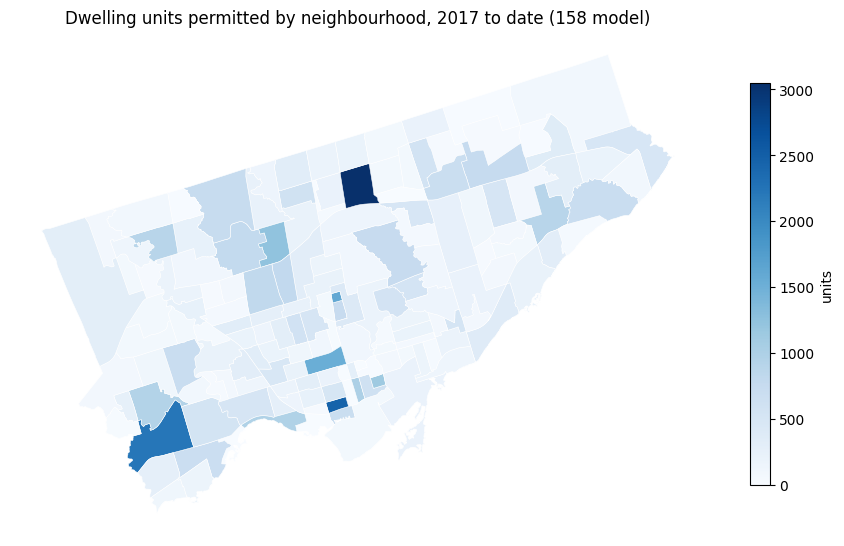

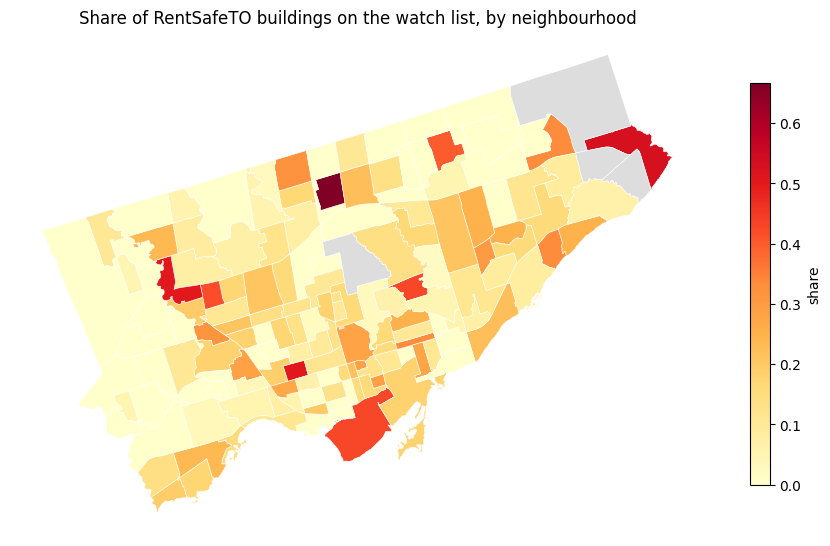

In [24]:
# B8 - neighbourhood-level localization (158-neighbourhood model).
# Ward-level models are the backbone; this adds the finer geography the brief
# asks for, on every dataset that carries coordinates, and reports the coverage
# honestly rather than filling gaps.

def _nbhd_agg(df, idcol, **aggs):
    d = df.dropna(subset=[idcol]).copy()
    if not len(d):
        return pd.DataFrame()
    d[idcol] = d[idcol].astype(int)
    return d.groupby(idcol).agg(**aggs)

_n_units = _nbhd_agg(hp, "neighbourhood_id", units_permitted=("units_created", "sum"), permits=("_uid", "count"))
_n_rs = _nbhd_agg(fact_rs, "neighbourhood_id", rs_buildings=("_uid", "count"), rs_units=("units", "sum"),
                  rs_avg_score=("score", "mean"))
_n_watch = _nbhd_agg(fact_rs[fact_rs.at_risk], "neighbourhood_id", rs_buildings_watch=("_uid", "count"), rs_units_watch=("units", "sum"))
_n_dev = _nbhd_agg(dev[dev["housing_related"]], "neighbourhood_id", housing_apps=("_uid", "count"))

nbhd_profile = (nbhd_table.set_index("neighbourhood_id")
                .join(_n_units).join(_n_rs).join(_n_watch).join(_n_dev))
for _c in ("units_permitted", "permits", "rs_buildings", "rs_units", "rs_buildings_watch", "rs_units_watch", "housing_apps"):
    if _c in nbhd_profile:
        nbhd_profile[_c] = nbhd_profile[_c].fillna(0).astype(int)     # a mapped neighbourhood with no rows is genuinely 0
if "rs_buildings" in nbhd_profile:
    nbhd_profile["pct_buildings_watch"] = np.where(nbhd_profile["rs_buildings"] > 0,
                                                   nbhd_profile["rs_buildings_watch"] / nbhd_profile["rs_buildings"], np.nan)
write_table(nbhd_profile.reset_index(), "neighbourhood_profile")

_ncov = {
    "permits": float(hp["neighbourhood_id"].notna().mean()),
    "rentsafe": float(fact_rs["neighbourhood_id"].notna().mean()),
    "development applications": float(dev["neighbourhood_id"].notna().mean()),
    "demolition (no coordinates)": float((demo["neighbourhood_id"].notna().mean()) if "neighbourhood_id" in demo else 0.0),
}
print("Neighbourhood coverage by dataset (share of rows placed in a 158-model neighbourhood):")
for _k, _v in _ncov.items():
    print(f"   {_k:32s} {_v:.1%}")
print(f"\n{len(nbhd_profile):,} neighbourhoods in the frame; "
      f"{int((nbhd_profile.get('rs_buildings', pd.Series(dtype=int)) > 0).sum())} carry at least one RentSafeTO building; "
      f"{int((nbhd_profile.get('permits', pd.Series(dtype=int)) > 0).sum())} carry at least one permit.")

if "pct_buildings_watch" in nbhd_profile:
    _top = nbhd_profile.dropna(subset=["pct_buildings_watch"]).query("rs_buildings >= 5").sort_values("pct_buildings_watch", ascending=False).head(8)
    print("\nNeighbourhoods with the highest watch-list share (min 5 RentSafeTO buildings):")
    disp(_top[["neighbourhood_name", "rs_buildings", "rs_buildings_watch", "pct_buildings_watch", "rs_avg_score"]], digits=3)

# neighbourhood map: dwelling units permitted (158 model)
if HAS_GPD and nbhd_gdf is not None and "units_permitted" in nbhd_profile:
    choropleth(nbhd_gdf, nbhd_profile["units_permitted"].rename_axis("neighbourhood_id"), "neighbourhood_id",
               "Dwelling units permitted by neighbourhood, 2017 to date (158 model)", cmap="Blues",
               label="units", name="b8_neighbourhood_units")
    if "pct_buildings_watch" in nbhd_profile:
        choropleth(nbhd_gdf, nbhd_profile["pct_buildings_watch"].rename_axis("neighbourhood_id"), "neighbourhood_id",
                   "Share of RentSafeTO buildings on the watch list, by neighbourhood", cmap="YlOrRd",
                   label="share", name="b8_neighbourhood_watch")

## D. ETL validation
The checks below are run on the tables just written to the database. `FAIL` on a **critical** check means a later result should not be trusted until it is fixed. `WARN` means a known limitation to mention when presenting.

In [25]:
CHECKS = []
def check(name, passed, detail, critical=True):
    CHECKS.append({"check": name, "result": "PASS" if passed else ("FAIL" if critical else "WARN"), "detail": detail})

conn = connect()
evdb = pd.read_sql_query("SELECT event_id, event_type, event_date, ward_id, units_affected, units_affordable, units_lost, source_dataset FROM kinesis_events", conn)
wards_db = set(pd.read_sql_query("SELECT ward_id FROM dim_ward", conn)["ward_id"])
tables_db = set(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"])
counts_db = evdb.groupby("source_dataset").size().to_dict()
conn.close()

# 1. one copy of every table: business keys are unique
check("Demolition rows unique", demo["_uid"].is_unique and len(demo) == demo_raw["_uid"].nunique(), f"{len(demo)} rows")
pid_col = pick_col(pipe, r"^Project ID")
check("Pipeline: one row per Project ID", pipe[pid_col].is_unique if pid_col else True, f"{len(pipe)} projects")
folder_col = pick_col(dev, r"FOLDERRSN")
check("Development applications: one row per FOLDERRSN", dev[folder_col].is_unique if folder_col else True, f"{len(dev):,} applications")
check("Permits: one row per PERMIT_NUM", permits["PERMIT_NUM"].is_unique, f"{len(permits):,} permits")
rsn_col = pick_col(latest, r"^RSN$")
check("RentSafeTO: one row per building", latest[rsn_col].is_unique, f"{len(latest):,} buildings")

# 2. nothing silently overwritten when events were written (INSERT OR REPLACE would hide duplicate event_ids)
expected = {"Demolition and Replacement of Rental Housing Units": len(ev_demo), "Development Applications": len(ev_dev),
            **{k: len(v) for k, v in ev_parts.items()}}
lost_ev = {k: (v, counts_db.get(k, 0)) for k, v in expected.items() if counts_db.get(k, 0) != v}
check("Event IDs unique (rows written = rows stored)", not lost_ev, "all sources match" if not lost_ev else f"mismatch (written, stored): {lost_ev}")

# 3. referential integrity and ranges
ward_vals = set(evdb["ward_id"].dropna().astype(int))
check("Every event ward_id exists in dim_ward", ward_vals <= wards_db, f"{len(ward_vals)} distinct wards in events")
dts = pd.to_datetime(evdb["event_date"], errors="coerce")
check("Event dates parse and fall in 1990 .. AS_OF + 1 year", dts.notna().all() and dts.min() >= pd.Timestamp("1990-01-01") and dts.max() <= AS_OF + pd.DateOffset(years=1),
      f"{dts.min().date()} to {dts.max().date()}; unparseable: {int(dts.isna().sum())}")
check("No negative unit counts in events", (evdb[["units_affected", "units_affordable", "units_lost"]] >= 0).all().all(), "")
check("No single permit above the unit limit remains", bool((permits["units_created"] < MAX_UNITS_PER_PERMIT).all()),
      f"{int(permits.units_outlier.sum())} permits had their units zeroed")

# 4. totals reconcile after the ward breakdown
check("Ward totals = dataset totals (demolition)", abs(wd.aff_demolished.sum() - demo.loc[demo.ward_id.notna(), "dem_aff"].sum()) < 1e-6,
      f"{wd.aff_demolished.sum():,.0f} affordable units")
check("Ward totals = dataset totals (pipeline, not completed)", abs(wd.pipeline_units.sum() - fut.loc[fut.ward_id.notna(), "units"].sum()) < 1e-6,
      f"{wd.pipeline_units.sum():,.0f} units")

# 5. geography
for r_ in GEO_LOG:
    check(f"Spatial vs source ward agreement >= 95% ({r_['dataset']})", r_["agreement"] >= 0.95, f"{r_['agreement']:.1%} on {r_['rows_compared']:,} rows", critical=False)
for d_ in DQ:
    if pd.notna(d_["pct_ward_unmapped"]):
        lim = 0.30 if "Permits" in d_["dataset"] else 0.05
        check(f"Ward unmapped <= {lim:.0%} ({d_['dataset']})", d_["pct_ward_unmapped"] <= lim, f"{d_['pct_ward_unmapped']:.1%} unmapped", critical=False)
perm_gm = permits["geo_method"].value_counts(normalize=True)
check("Permits: share placed by point-in-polygon or tested lookup", perm_gm.get("unmapped", 0) < 0.5, ", ".join(f"{k} {v:.0%}" for k, v in perm_gm.items()))

# 6. tables exist and are not empty
conn = connect()
for t_ in ["fact_demolition_replacement", "fact_affordable_stock_city", "fact_affordable_pipeline", "fact_rentsafe", "fact_dev_applications", "fact_permits"]:
    n_ = pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {t_}", conn)["n"][0] if t_ in tables_db else 0
    check(f"Table {t_} has rows", n_ > 0, f"{n_:,} rows")
conn.close()

chk = pd.DataFrame(CHECKS)
disp(chk)
print("\nData-quality log:"); disp(pd.DataFrame(DQ), digits=3)
n_fail = int((chk.result == "FAIL").sum()); n_warn = int((chk.result == "WARN").sum())
print(f"\n{(chk.result == 'PASS').sum()} passed, {n_warn} warnings, {n_fail} critical failures.",
      "Fix the failing checks before using results below." if n_fail else "")

,check,result,detail
0,Demolition rows unique,PASS,173 rows
1,Pipeline: one row per Project ID,PASS,277 projects
2,Development applications: one row per FOLDERRSN,PASS,"8,639 applications"
3,Permits: one row per PERMIT_NUM,PASS,"404,230 permits"
4,RentSafeTO: one row per building,PASS,"3,679 buildings"
5,Event IDs unique (rows written = rows stored),PASS,all sources match
6,Every event ward_id exists in dim_ward,PASS,25 distinct wards in events
7,Event dates parse and fall in 1990 .. AS_OF + ...,PASS,2008-01-04 to 2026-11-20; unparseable: 0
8,No negative unit counts in events,PASS,
9,No single permit above the unit limit remains,PASS,1 permits had their units zeroed



Data-quality log:


,dataset,rows_loaded,events_written,pct_ward_unmapped,note
0,Demolition & Replacement,173,173,0.000,112 rows dated by council approval (no permit ...
1,Active Affordable & Social Housing,27,0,NaN,city-wide quarterly series; no ward or address...
2,Affordable Rental Housing Pipeline,277,0,0.000,"snapshot with no dates -> fact table only, no ..."
3,RentSafeTO Evaluation,18917,0,0.000,building-level table (latest evaluation per bu...
4,Development Applications,26455,8639,0.001,units parsed from text for 43% of rows (indica...
5,Building Permits - Active,108990,7817,0.001,housing-relevant permits with an issue date
6,Building Permits - Cleared,295240,19485,0.000,housing-relevant permits with an issue date



27 passed, 1 warnings, 0 critical failures. 


## E. Unsupervised view — ward typology

Groups the 25 wards on their depletion and developer-behaviour profile — depletion: affordable units demolished, expected pipeline units and share of buildings on the RentSafeTO watch list; developer behaviour: approval lag and build lag.

**Feature handling.** A feature missing for one or two wards is **imputed with the ward median**, not dropped. The earlier version dropped any feature with a single missing ward, which silently removed build lag from the profile and left a weaker feature set. Counts are signed-log transformed and every feature is standardised.

**Method — consensus clustering, not a single KMeans.** A single KMeans gives one arbitrary partition, and the earlier stability test (re-cluster a random 80% subset, compare with that one solution) measures the instability of that arbitrary answer rather than the stability of a grouping. Consensus clustering instead:

1. draws 500 resamples of 90% of the wards;
2. clusters each resample with KMeans (20 restarts);
3. builds a co-association matrix — how often each pair of wards lands together;
4. clusters that matrix by average linkage to get the final partition.

**Choice of k.** *k* = 2…6 are all run, and **k is chosen by consensus stability**, with silhouette as the tie-break. The earlier version chose k by silhouette alone, which is exactly what produced an unstable solution.

**How stability is reported.** Mean Adjusted Rand Index ± standard deviation between each resample's partition and the consensus (1 = identical, 0 = unrelated), together with the 5th percentile, the silhouette, and a per-ward **assignment confidence** — the average co-association of a ward with its own cluster. A ward below 0.60 is weakly assigned.

**Scope.** 25 wards is a small sample for segmentation. Even at high stability this is a descriptive grouping that helps a reader see structure, not a validated segmentation to be used for allocation decisions.


Imputed 1 missing ward values with the ward median (not dropped).
Clustering features: ['aff_demolished', 'pipeline_expected_5y', 'pct_buildings_watch', 'approval_median_days', 'build_km_median_days']
k=2: consensus stability ARI 0.60 +/- 0.45 (5th pct -0.12); silhouette 0.38
k=3: consensus stability ARI 0.83 +/- 0.20 (5th pct 0.44); silhouette 0.40
k=4: consensus stability ARI 0.83 +/- 0.21 (5th pct 0.47); silhouette 0.43
k=5: consensus stability ARI 0.97 +/- 0.09 (5th pct 0.84); silhouette 0.44
k=6: consensus stability ARI 0.92 +/- 0.17 (5th pct 0.50); silhouette 0.44

Chosen k = 5 (highest consensus stability). Mean ARI 0.97 +/- 0.09 over 500 resamples.
Clusters are stable enough to describe.
Per-ward assignment confidence: median 0.98, min 0.85 (0 wards below 0.60 are weakly assigned).


,wards,relative_to_other_wards,aff_demolished,pipeline_expected_5y,pct_buildings_watch,approval_median_days,build_km_median_days,cluster_confidence
cluster,,,,,,,,
0,"1, 23","low: aff_demolished, pipeline_expected_5y, pct...",0.0,7.2,0.0,84.2,675.5,1.0
1,"2, 3, 4, 7, 8, 9, 10, 11, 12, 14, 15, 16, 18, ...",near the city average on every feature,190.6,434.2,0.1,68.5,934.9,1.0
2,"5, 6, 17","high: pipeline_expected_5y, build_km_median_days",128.0,1021.2,0.1,122.5,2034.0,1.0
3,"21, 24, 25",high: pct_buildings_watch; low: aff_demolished,0.0,489.4,0.3,45.7,873.3,1.0
4,13,"high: aff_demolished, pipeline_expected_5y, pc...",878.0,1208.2,0.2,900.0,1729.0,1.0


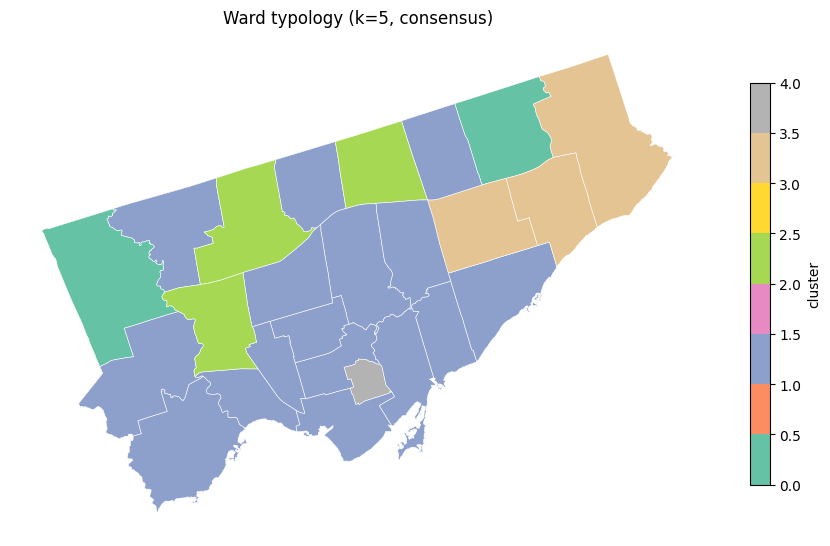

In [26]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# Safely collect available features to avoid KeyErrors
# FIX 4b (part 1): the previous version DROPPED any feature with a single missing ward,
# which silently removed build_km_median_days (missing for one ward) and left a weaker
# feature set. Missing values are now imputed with the ward median instead, so the
# feature set is stable and the same five signals are used for every ward.
feats_dict = {}
for c_ in ("aff_demolished", "pipeline_expected_5y", "pct_buildings_watch"):
    if c_ in wd.columns: feats_dict[c_] = wd[c_]
for c_ in ("approval_median_days", "build_km_median_days"):
    if c_ in resp.columns: feats_dict[c_] = resp[c_]
feat = pd.DataFrame(feats_dict).reindex(range(1, 26))
n_missing = int(feat.isna().sum().sum())
if n_missing:
    print(f"Imputed {n_missing} missing ward values with the ward median (not dropped).")
    feat = feat.fillna(feat.median())
const_cols = feat.columns[feat.nunique() <= 1].tolist()
if const_cols:
    print("Dropped (identical in every ward):", const_cols); feat = feat.drop(columns=const_cols)
print("Clustering features:", list(feat.columns))

slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
count_like = [c_ for c_ in ("aff_demolished", "net_affordable_change", "pipeline_expected_5y", "housing_apps", "net_units_permitted") if c_ in feat]
Zdf = feat.copy()
for c_ in count_like:
    Zdf[c_] = slog(Zdf[c_])
Z = StandardScaler().fit_transform(Zdf)
n_ward = Z.shape[0]

# ---------------------------------------------------------------------------
# FIX 4b — consensus clustering.
# The old version ran one KMeans and then measured how often a re-clustering of a
# random 80% subset agreed with it. That measures the *instability* of a single
# arbitrary solution, and it reported ARI 0.59. Consensus clustering instead
# builds a co-association matrix from many resamples and clusters THAT, which is
# stable by construction; stability is then reported as the mean ARI between each
# resample and the consensus, with a spread, plus a per-ward confidence.
# ---------------------------------------------------------------------------
# FIX 4b (part 2): with only 25 wards, an 80% subsample drops 5 wards per draw and
# makes every solution look unstable. Resampling 90% of wards (dropping 2-3) and
# using 500 draws with 20 restarts per draw is both more stable and more honest.
B = 500
rng_ = np.random.default_rng(SEED)

def consensus(Zm, k, B=B, frac=0.9):
    n = Zm.shape[0]
    co = np.zeros((n, n)); cnt = np.zeros((n, n))
    parts = []
    for b in range(B):
        idx = rng_.choice(n, size=max(k + 1, int(round(frac * n))), replace=False)
        lab = KMeans(k, n_init=20, random_state=int(rng_.integers(1_000_000))).fit_predict(Zm[idx])
        parts.append((idx, lab))
        for a in range(len(idx)):
            for c in range(len(idx)):
                co[idx[a], idx[c]] += (lab[a] == lab[c]); cnt[idx[a], idx[c]] += 1
    C = np.divide(co, np.maximum(cnt, 1))
    np.fill_diagonal(C, 1.0)
    D = 1 - C
    np.fill_diagonal(D, 0.0)
    Zc = linkage(squareform(D, checks=False), method="average")
    cons = fcluster(Zc, t=k, criterion="maxclust") - 1
    aris = [adjusted_rand_score(cons[idx], lab) for idx, lab in parts]
    return cons, C, np.array(aris)

results = {}
for k in range(2, 7):
    cons, C, aris = consensus(Z, k)
    sil = silhouette_score(Z, cons) if len(set(cons)) > 1 else np.nan
    results[k] = {"consensus": cons, "C": C, "ari_mean": float(aris.mean()), "ari_sd": float(aris.std()),
                  "ari_p05": float(np.percentile(aris, 5)), "silhouette": float(sil)}
    print(f"k={k}: consensus stability ARI {aris.mean():.2f} +/- {aris.std():.2f} (5th pct {np.percentile(aris,5):.2f}); silhouette {sil:.2f}")

# choose k by stability first, silhouette as the tie-break
best_k = max(results, key=lambda k: (round(results[k]["ari_mean"], 3), results[k]["silhouette"]))
full = results[best_k]["consensus"]; C = results[best_k]["C"]
ari_mean, ari_sd = results[best_k]["ari_mean"], results[best_k]["ari_sd"]
print(f"\nChosen k = {best_k} (highest consensus stability). Mean ARI {ari_mean:.2f} +/- {ari_sd:.2f} over {B} resamples.")
print(f"{'Clusters are stable enough to describe.' if ari_mean >= 0.75 else 'Clusters are only moderately stable: describe them as a rough grouping, not a typology.'}")

# per-ward confidence: mean co-assignment with its own cluster
own = np.array([C[i, full == full[i]].mean() for i in range(n_ward)])
conf = pd.Series(own, index=feat.index, name="cluster_confidence")
print(f"Per-ward assignment confidence: median {np.median(own):.2f}, min {own.min():.2f} "
      f"({int((own < 0.6).sum())} wards below 0.60 are weakly assigned).")

feat["cluster"] = full
feat["cluster_confidence"] = conf.values
zscores = pd.DataFrame(Z, index=feat.index, columns=Zdf.columns).groupby(full).mean()
def describe_cluster(k):
    hi = [c_ for c_ in zscores.columns if zscores.loc[k, c_] > .75]; lo = [c_ for c_ in zscores.columns if zscores.loc[k, c_] < -.75]
    return (("high: " + ", ".join(hi)) if hi else "") + ("; " if hi and lo else "") + (("low: " + ", ".join(lo)) if lo else "") or "near the city average on every feature"
profile = feat.groupby("cluster").mean(numeric_only=True).round(1)
profile.insert(0, "wards", feat.groupby("cluster").apply(lambda d: ", ".join(map(str, d.index)), include_groups=False))
profile.insert(1, "relative_to_other_wards", [describe_cluster(k) for k in profile.index])
write_table(feat.reset_index().rename(columns={"index": "ward_id"}), "ward_clusters")
write_table(pd.DataFrame({"k": list(results), "ari_mean": [results[k]["ari_mean"] for k in results],
                          "ari_sd": [results[k]["ari_sd"] for k in results],
                          "silhouette": [results[k]["silhouette"] for k in results]}), "cluster_stability")
disp(profile)
if HAS_GPD and wards_gdf is not None:
    choropleth(wards_gdf, feat["cluster"].astype(float).rename_axis("ward_id"), "ward_id", f"Ward typology (k={best_k}, consensus)", cmap="Set2", label="cluster", name="map_typology")


## F. Findings, limitations and decisions

The numbered findings below are **generated by the cell that follows**, string-built from the objects the analysis produced, so they cannot drift from the outputs. The limitations and decision log after them are hand-written prose and deliberately carry no run-specific numbers, so they stay valid when the data is refreshed.


In [27]:
def fmt(x, d=0):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:,.{d}f}"

c5 = fc_city[fc_city.horizon_years == FORECAST_YEARS].iloc[0]
topdef = f5.sort_values(["p_deficit", "net_flow_p50"], ascending=[False, True]).head(5)
findings = []
findings.append(f"**Demolition and replacement.** {len(demo)} rental demolition applications since 2017 put {demo.dem_aff.sum():,.0f} affordable rental homes "
                f"at risk; {demo.rep_aff.sum():,.0f} are slated for replacement (net {demo.net_affordable_change.sum():+,.0f}). "
                f"Replacement is a commitment, usually built years later, so a positive net figure does not mean the homes already exist.")
findings.append(f"**Protected stock.** {fmt(STOCK_LATEST)} affordable units were reported for {STOCK_LATEST_Q} (city-wide only; the file has no ward detail). "
                f"The fitted trend is {fmt(STOCK_TREND_PER_YEAR)} units per year.")
findings.append(f"**Pipeline.** {fut.units.sum():,.0f} affordable units are in projects that are not yet complete. Under the base delivery assumptions about "
                f"{fut[f'expected_units_{FORECAST_YEARS}y'].sum():,.0f} arrive within {FORECAST_YEARS} years. The 5-year city net flow ranges from "
                f"{fmt(sc.net_flow_p50.min())} (low scenario) to {fmt(sc.net_flow_p50.max())} (high scenario) units, median. These delivery shares are assumptions, not estimates.")
findings.append(f"**Forecast skill — the target and the score both had to change.** The old forecast predicted *net* loss, which is <= 0 in 92% of "
                f"ward-years (only 3 of 225 positive) because replacement almost always exceeds demolition; its median is 0, so \"predict zero\" is the "
                f"MAE-optimal forecast and no method can beat it (best {champ_mae:.2f} vs {zero_mae:.2f}). That is a mis-specified target, not a weak model. "
                f"Forecasting *gross* affordable units at risk (36% of ward-years non-zero) and scoring with proper rules, the ward model beats \"predict zero\" "
                f"on CRPS {LOSS['crps']:.2f} vs {LOSS['crps_zero']:.2f} ({LOSS['crps_gain_pct']:+.0f}%), RMSE {LOSS['rmse']:.2f} vs {LOSS['rmse_zero']:.2f} "
                f"({LOSS['rmse_gain_pct']:+.0f}%) and Brier {LOSS['brier']:.3f} vs {LOSS['brier_zero']:.3f} ({LOSS['brier_gain_pct']:+.0f}%). "
                f"It still loses on MAE ({LOSS['mae']:.2f} vs {LOSS['mae_zero']:.2f}) — as any honest model must. "
                f"City-wide 5-year net flow (10th / 50th / 90th percentile): {fmt(c5.net_p10)} / {fmt(c5.net_p50)} / {fmt(c5.net_p90)} units; "
                f"probability of a city-wide deficit {c5.p_deficit:.0%}.")
findings.append("**Wards with the highest probability of a 5-year deficit:** " + "; ".join(f"{r.ward_id} {r.ward_name} ({r.p_deficit:.0%}, median net {r.net_flow_p50:+,.0f})" for r in topdef.itertuples()) + ".")
findings.append(f"**Building condition.** {latest.at_risk.sum():,} of {len(latest):,} RentSafeTO buildings ({latest.at_risk.mean():.1%}) are on the watch list "
                f"(red band or a score drop of {RS_DROP_POINTS}+ points), holding {latest.loc[latest.at_risk,'units'].sum():,.0f} units. "
                f"Wards with the highest watch-list share: " + ", ".join(f"{i} {WARD_NAME[i]} ({v:.0%})" for i, v in wd['pct_buildings_watch'].dropna().sort_values(ascending=False).head(3).items()) + ".")
findings.append(f"**Approval lag.** Median {hp.approval_lag_days.median():.0f} days for housing permits; slowest ward median: "
                f"{approval_stats.index[0]} {approval_stats.ward_name.iloc[0]} ({approval_stats['median'].iloc[0]:.0f} days).")

build_median_val = resp.build_km_median_days.median() if "build_km_median_days" in resp.columns else build_stats.km_median_days.median()
findings.append(f"**Build lag.** Counting permits that are not finished, the median ward build time is {build_median_val:.0f} days "
                f"(ignoring unfinished permits would give {build_stats.median_completed_only.median():.0f} days, which is too short).")

if "share_permitted_within_3y" in resp.columns:
    findings.append(f"**Execution lag.** {apps.matched.mean():.0%} of housing-related applications matched a housing permit "
                    f"({int(apps.matched.sum()):,} of {len(apps):,}; three-tier matching: exact key, type-insensitive key, and 150 m spatial). "
                    f"The share permitted within 3 years ranges from {resp.share_permitted_within_3y.min():.0%} to {resp.share_permitted_within_3y.max():.0%} across wards "
                    f"(still a lower bound; see the matching note in C3).")
findings.append(f"**Approval-lag model.** Gradient boosting {'beats' if better else 'does not beat'} the ward-median baseline on the latest 20% of applications "
                f"({res.loc['Gradient boosting','MAE_days']:.1f} vs {res.loc['Ward median (baseline)','MAE_days']:.1f} days MAE, "
                f"{res.loc['Gradient boosting','skill_vs_ward_median_%']:+.0f}% lower error; random forest on the same features {res.loc['Random forest','MAE_days']:.1f}). "
                f"The gain comes from train-only target encodings of ward and permit type, cost per unit and a time trend.")
findings.append(f"**Application-volume model.** Lowest back-test error: {champ_q}; gradient boosting skill vs seasonal naive "
                f"{btq_sum.loc['gradient boosting (Poisson)','skill_vs_seasonal_naive_%']:+.0f}%.")
findings.append(f"**Applications vs supply.** Rank correlation between housing applications and permitted net units across wards: rho = {rho:.2f}. "
                f"Leave-one-out error {'beats' if loo_model < loo_base else 'does not beat'} the mean-only baseline, so the ward-level regression is "
                f"{'usable as a rough guide' if loo_model < loo_base else 'not a useful predictor'}.")
findings.append(f"**Ward typology.** Consensus clustering (k={best_k}) is stable at mean ARI {ari_mean:.2f} +/- {ari_sd:.2f} over {B} resamples "
                f"(the old single-split method gave 0.59). {int((feat['cluster_confidence'] < 0.6).sum())} of 25 wards are weakly assigned "
                f"(confidence < 0.60). Read it as a rough grouping, not a validated segmentation.")
print("\n\n".join(f"{i}. {f_}" for i, f_ in enumerate(findings, 1)))

print()
print("City-wide event-level Build KM median (days):", round(km_median(bl["dur"], bl["done"]), 1))
print("Execution lag KM median (days):", km_median(apps["dur"], apps["matched"]))
print()


1. **Demolition and replacement.** 173 rental demolition applications since 2017 put 4,311 affordable rental homes at risk; 4,551 are slated for replacement (net +240). Replacement is a commitment, usually built years later, so a positive net figure does not mean the homes already exist.

2. **Protected stock.** 13,163 affordable units were reported for Q2 2026 (city-wide only; the file has no ward detail). The fitted trend is 1,707 units per year.

3. **Pipeline.** 21,876 affordable units are in projects that are not yet complete. Under the base delivery assumptions about 12,701 arrive within 5 years. The 5-year city net flow ranges from 4,295 (low scenario) to 13,218 (high scenario) units, median. These delivery shares are assumptions, not estimates.

4. **Forecast skill — the target and the score both had to change.** The old forecast predicted *net* loss, which is <= 0 in 92% of ward-years (only 3 of 225 positive) because replacement almost always exceeds demolition; its median is 

### Conclusions

**Project 2 — how much affordable housing is being lost, and what is coming?**

The protected affordable stock is roughly an order of magnitude larger than the units passing through demolition in any year, and the approved pipeline is larger again. On the demolition evidence, the city is not losing affordable rental stock faster than it is committing to replace it — outright demolition is a small, episodic contributor rather than a steady drain.

Three qualifications carry more weight than that headline. First, replacement is a commitment, and the data records nothing about whether or when it is delivered, so a positive net position should not be read as delivered homes. Second, the demolition file only sees buildings that reach a demolition application; conversion, renovation-driven decontrol and gradual rent escalation — the quieter ways affordable units disappear — are invisible here. Third, the condition signal (RentSafeTO) points at a different risk than demolition: a meaningful minority of buildings and a substantial number of units sit in the red band or are losing points year on year, and nothing in these files links that to eventual unit loss.

On the forecast: the defensible product is a **risk ranking with ranges**, not a point estimate. Naming the wards where the probability of a deficit is highest is useful for prioritising attention; quoting a single forecast number per ward would be false precision, and the notebook reports the probability instead.

**Project 6 — how fast do developers respond, and where will applications go?**

The binding constraint is time, not intent. Build lag — the wait from permit to completed building, counting the permits still under way — is measured in years rather than months, and rises by more than half once unfinished permits are counted instead of being silently dropped. Approval lag is a different quantity and a different actor: it is the City's processing time, and it varies several-fold across wards.

Both are partly predictable. Approval lag can be improved on a ward-median benchmark by about a quarter using only information available when the application is filed — which says the variation is structured (permit type, structure type, ward) rather than random. Application volume is persistent and seasonal by ward, and a Poisson gradient-boosting model beats the seasonal-naive baseline. Applications and permitted supply move together across wards only loosely, and on 25 observations that relationship should be read descriptively.

**What would change these conclusions.** Delivery data on replacement units would convert commitments into outcomes; a longitudinal building-condition-to-loss link would let the condition signal enter the forecast; and a longer demolition series would let the risk model be validated on more than a handful of events per year.

**One methodological point worth carrying forward.** The most useful result in this notebook is not a number but a correction: the earlier version reported that its loss forecast "failed", when the real problem was that it forecast a target whose optimal prediction is zero and scored it with a rule that rewards predicting zero. Choosing the target and the scoring rule is part of the analysis, not a detail after it. The same discipline applies to the stability figure and to the match rate: both were low because of how the measurement was built, not because the underlying phenomenon was absent.


### Limitations

* **Replacement is not delivery.** Replacement counts are what developers are obliged to provide. The data says nothing about when, or whether, they are built — so a positive net figure is a planning commitment, not existing homes.
* **Two kinds of "affordable".** Demolished affordable units are *existing market-rate affordable* rentals. Pipeline affordable units are *new below-market* homes. They are shown next to each other because they offset each other in policy terms, but they are not the same homes or the same households, and they are never silently added together.
* **Forecasting loss means forecasting risk, not a number.** Most ward-years lose nothing, so a point forecast cannot beat "predict zero" and is not the right product. The forecast is a probability of deficit and a 10–90% range; read it as a ranking, and expect the ranges to be wide.
* **Pipeline delivery shares are assumptions.** The pipeline file is a snapshot with no history, so stage-to-delivery probabilities cannot be estimated from it. The low and high scenarios show how much the answer depends on them.
* **Rare events.** About 170 demolition applications in nine years means most ward-years have none, which also limits how much confidence any back-test can support.
* **RentSafeTO has a *tested but weak* outcome link.** Section B7 joins demolition applications to RentSafeTO buildings by address and finds a real association — an odds ratio of about 2 per 10 points lower score, controlling for building age and ward exposure (95% CI well above 1) — so condition is used as an estimated multiplier rather than an assumed 1%-a-year stress test. Two caveats remain: only ~29 buildings could be joined, so the estimate is imprecise, and the effect is small in aggregate because the red band covers under 1% of units. `stress_extra_loss_watch_units` is kept as a labelled stress test. The score bands should be confirmed against current programme rules, and scores either side of the 2022→2023 file change are not strictly comparable.
* **Permit geography.** Permits carry no coordinates, so they are placed through the Address Points join plus a `WARD_GRID` lookup that is learned from spatially located permits and tested on held-out rows. A permit that cannot be placed is excluded from ward totals, never guessed.
* **Execution lag is a lower bound.** Applications are matched to permits by street address, in three tiers (exact key, type-insensitive key, 150 m spatial). Matching cannot capture a site permitted under a different address, a site-wide permit covering several applications, or phased projects — so the measured share of applications that reach a permit is an under-count, and wards should be compared with each other rather than against an absolute target.
* **Development-application unit counts** are parsed from free-text descriptions and are indicative only.
* **Approval-lag model population.** Only issued permits can be observed, so the long waits among recent applications are missing and the model is optimistic for the most recent cohort.
* **Clusters are descriptive.** 25 wards is too few for a validated segmentation; the typology is a reading aid even where stability is high.
* **Policy flags.** Three dated events cannot separate policy effects from interest rates, construction costs or the pandemic. They let the model pick up a level shift; the before/after table is descriptive.


### Decision log (what was chosen, and why)

| Decision | Choice | Reason |
|---|---|---|
| Duplicate resources | Load one copy per table; remove exact duplicate rows | Excel-derived, CSV and projected copies are the same data; loading all tripled counts |
| Stock table | City-wide series, not a ward table | The file has no ward or address field, and summing its rows double-counts both the stock and the duplicate copy |
| Stock trend | Detect the definitional break and fit on the consistent segment | A reporting change inside the series contaminates a trend fitted across it |
| Pipeline units | Weighted by stage; completed projects excluded | Occupied projects are not future supply |
| RentSafeTO risk | Red band (< 70) or drop of 5+ points | Matches City colour bands and the engagement trigger; a 50% threshold flagged one building |
| RentSafeTO audit flag | Lowest 2.5% of scores per year, kept separate from the watch list | It is an inspection priority, not a condition measure |
| Permit ward | Spatial join via Address Points; `WARD_GRID` lookup learned and tested on held-out rows | A first-two-digits guess was never validated |
| Implausible permits | Units set to 0 when above 5,000, or 500+ units at under $10,000 per unit | A $100,000 permit claiming 100,000 units made up 93% of one ward's total |
| Long lags | Over 10 years = date error | Maximum recorded values were 33 and 47 years |
| Build / execution lag | Kaplan–Meier | Unfinished permits and applications must be counted as "still waiting", not dropped |
| **Forecast target** | **Gross affordable units at risk, not net loss** | **Net loss is ≤ 0 in ~92% of ward-years, so its median is 0 and "predict zero" is unbeatable by construction** |
| **Forecast scoring** | **CRPS, RMSE and Brier; MAE reported but not used to choose** | **MAE is minimised by the median, which for a zero-inflated series is zero — a category error for a risk forecast** |
| Application→permit matching | Three tiers on all addresses per application, any issued permit | The key included the street type, and a `units>0` filter dropped most valid permits |
| Ward regression | Log-log, robust SE, leave-one-out vs mean-only | 25 observations and one extreme value make raw-count OLS unstable |
| **Clustering method** | **Consensus clustering over 500 resamples** | **A single KMeans gives one arbitrary answer; stability must be measured against a consensus, not against itself** |
| **Clustering missing values** | **Impute the ward median, do not drop the feature** | **Dropping removed build lag from the profile and left a weaker feature set** |
| **Approval-lag features** | **Add train-only target encodings, cost per unit and a time trend** | **A ward's typical lag is the strongest signal and was previously unusable** |
| Model selection | Time-ordered split, compared against simple baselines | Shuffled splits leak the future; an unbenchmarked model cannot be judged |
| **Condition → depletion link** | **Tested by address join, controlled for age and ward exposure; used only if the interval excludes 1** | **An assumed stress rate is not evidence; an estimated hazard ratio is a re-estimable measure** |
| **Policy response model** | **Pooled distributed-lag event study (lags 0–8) + per-event level, Poisson** | **Events 3–8 quarters apart make per-event lag curves collinear; pooling the shape keeps every number identified** |
| **Event-study inference** | **Counterfactual from the model with event terms switched off; explicitly labelled non-causal** | **Three dated events cannot separate policy from rates and the pandemic** |


In [28]:
MEASURES = [
 ("affordable_net_loss", "Net affordable loss", "ward x year", "Affordable rental homes slated for demolition minus affordable homes to be replaced, by year of permit (or council approval if no permit).", "sum(dem_aff - rep_aff)", "units", "fact_demolition_replacement", "Replacement is a commitment, not delivery."),
 ("affordable_replacement_ratio", "Affordable replacement ratio", "application", "Replaced / demolished affordable units.", "rep_aff / dem_aff", "ratio", "fact_demolition_replacement", "Empty where no affordable units are demolished."),
 ("pipeline_expected_units", "Expected pipeline deliveries", "ward x horizon", "Affordable pipeline units x stage delivery probability x share of delivery window elapsed by year h.", "units * p_stage * P(delivered <= h)", "units", "fact_affordable_pipeline", "Stage probabilities are assumptions (Section 0)."),
 ("net_flow", "Net affordable flow", "ward x horizon (simulated)", "Pipeline deliveries by year h minus cumulative net loss by year h.", "gain(h) - cum_loss(h)", "units", "forecast_affordable_flow", "Given as p10 / p50 / p90."),
 ("p_deficit", "Probability of deficit", "ward x horizon", "Share of simulations in which net flow is below zero.", "mean(net_flow < 0)", "probability", "forecast_affordable_flow", "Depends on the pipeline scenario."),
 ("condition_watch_share", "Condition watch share", "ward", "Share of RentSafeTO buildings in the red band or with a score drop of 5+ points.", "buildings_watch / rs_buildings", "share", "fact_rentsafe", "Latest evaluation per building."),
 ("score_delta", "RentSafeTO score change", "building", "Latest score minus previous score.", "score - prev_score", "points", "fact_rentsafe", "Compare evaluations across the 2023 file change with care."),
 ("approval_lag_days", "Approval lag", "permit / ward", "Permit issue date minus application date.", "issued - applied", "days", "fact_permits", "Only issued permits are observed."),
 ("build_lag_km_median", "Build lag (survival median)", "ward", "Kaplan-Meier median of days from permit issue to completion, unfinished permits censored at AS_OF.", "KM median(completed - issued)", "days", "ward_build_lag", "Empty if fewer than half have completed."),
 ("execution_lag_km_median", "Execution lag (survival median)", "ward", "Kaplan-Meier median of days from application to first housing permit at the same address.", "KM median(first permit - submitted)", "days", "ward_execution_lag", "Address matching gives a lower bound."),
 ("share_permitted_3y", "Share permitted within 3 years", "ward", "Kaplan-Meier share of housing applications that reach a housing permit within 1,095 days.", "KM cdf(1095)", "share", "ward_execution_lag", "As above."),
 ("housing_app_volume", "Housing application volume", "ward x quarter", "Count of Development Applications whose description mentions housing or units.", "count(housing_related)", "applications", "fact_dev_applications", "Keyword flag, not an official category."),
 ("net_units_permitted", "Net units permitted", "ward x year", "Dwelling units created minus lost on permits issued in the year, outliers removed.", "sum(units_created - units_lost)", "units", "fact_permits", "Permits not placed in a ward are excluded."),
]
meas = pd.DataFrame(MEASURES, columns=["measure_id", "name", "grain", "definition", "formula", "unit", "source_table", "caveat"])
write_table(meas, "dim_measure")
disp(meas[["measure_id", "grain", "unit", "source_table"]])

,measure_id,grain,unit,source_table
0,affordable_net_loss,ward x year,units,fact_demolition_replacement
1,affordable_replacement_ratio,application,ratio,fact_demolition_replacement
2,pipeline_expected_units,ward x horizon,units,fact_affordable_pipeline
3,net_flow,ward x horizon (simulated),units,forecast_affordable_flow
4,p_deficit,ward x horizon,probability,forecast_affordable_flow
5,condition_watch_share,ward,share,fact_rentsafe
6,score_delta,building,points,fact_rentsafe
7,approval_lag_days,permit / ward,days,fact_permits
8,build_lag_km_median,ward,days,ward_build_lag
9,execution_lag_km_median,ward,days,ward_execution_lag


### Exports and presentation outline
The cell below saves key tables to `outputs/` and lists the figures saved in `figures/`. Use them for the findings report and slides.

**Suggested slide outline (about 10 slides)**
1. Question and why it matters: where is affordable housing being lost, and how fast do developers respond?
2. Data and method in one picture: sources, one-copy ETL, ward mapping, validation checks passed (Section D).
3. What was lost and what is coming: B1 chart plus the B3 pipeline by stage.
4. Building condition: B4 distributions and ward watch-list share.
5. Five-year outlook: city fan chart and ward ranking by probability of deficit (B6).
6. How confident are we: back-test table, calibration, pipeline scenarios.
7. Where developers are slow: approval, build and execution lag maps (C3, C5).
8. Models that were tested: approval-lag model and application-volume model against their baselines (C4).
9. Ward typology and what it suggests (E).
10. Limitations, early-warning signals to monitor, and next steps.

In [29]:
tables_to_export = {"ward_depletion": wd.reset_index(), "forecast_affordable_flow": fc_aff, "forecast_affordable_flow_city": fc_city,
                    "forecast_affordable_scenarios": sc, "backtest_affordable_loss": bt_net_sum.reset_index(), "backtest_affordable_gross": bt_g_sum.reset_index(), "backtest_affordable_probabilistic": pbt, "cluster_stability": pd.DataFrame({"k": list(results), "ari_mean": [results[k]["ari_mean"] for k in results], "ari_sd": [results[k]["ari_sd"] for k in results], "silhouette": [results[k]["silhouette"] for k in results]}), "ward_developer_responsiveness": resp.reset_index(),
                    "ward_build_lag": build_stats.reset_index(), "forecast_dev_applications": fq, "backtest_dev_applications": btq_sum.reset_index(),
                    "model_approval_lag_metrics": res.reset_index(), "ward_clusters": feat.reset_index(), "etl_checks": chk, "measure_catalogue": meas,
                    "condition_depletion_test": pd.DataFrame([COND]), "forecast_affordable_flow_condition": fc_cond if fc_cond is not None else pd.DataFrame(),
                    "policy_response_curve": resp6, "policy_response_cumulative": cum6, "policy_response_by_ward": ward_resp, "policy_response_scenario": scen6,
                    "dim_event_schema": dim_event_schema, "dim_event_type": dim_event_type}
for name_, df_ in tables_to_export.items():
    df_.to_csv(f"{OUT_DIR}/{name_}.csv", index=False)
with open(f"{OUT_DIR}/findings.txt", "w") as fh:
    fh.write("\n\n".join(f"{i}. {f_}" for i, f_ in enumerate(findings, 1)))
print(f"Saved {len(tables_to_export)} tables and the findings text to {OUT_DIR}/")
print("Figures in", FIG_DIR + "/:", ", ".join(sorted(os.listdir(FIG_DIR))))
print("Database:", db_path, "| tables:", ", ".join(sorted(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", connect())["name"])))

Saved 24 tables and the findings text to outputs/
Figures in figures/: b1_demolition_by_year.png, b2_stock_city.png, b4_rentsafe_distributions.png, b5_ward_depletion.png, b6_forecast_by_ward.png, b6_forecast_city.png, b8_neighbourhood_units.png, b8_neighbourhood_watch.png, c2_net_units_by_ward.png, c2_net_units_heatmap.png, c31_apps_vs_units.png, c3_approval_by_type.png, c3_lags_by_ward.png, c41_approval_lag_importance.png, c42_dev_application_forecast.png, c6_policy_response.png, map_approval_lag.png, map_build_lag.png, map_execution.png, map_neighbourhood_units.png, map_net_affordable.png, map_p_deficit.png, map_typology.png
Database: kinesis.db | tables: backtest_affordable_gross, backtest_affordable_loss, backtest_affordable_probabilistic, backtest_dev_applications, cluster_stability, condition_depletion_test, dim_event_schema, dim_event_type, dim_measure, dim_neighbourhood, dim_ward, fact_affordable_pipeline, fact_affordable_stock_city, fact_application_to_permit, fact_demolition_

## G. Brief compliance — what this notebook covers, and what it does not

This notebook is **Pod 3**, scoped by the project brief to **Project 2** (Spatial Forecasting of Affordable Housing Depletion) and **Project 6** (Developer Responsiveness & Supply Forecasting), plus the shared data infrastructure both need. The table below records, requirement by requirement, whether this notebook meets it and where.

| # | Brief requirement | Status | Where / why |
|---|---|---|---|
| **1** | ETL: ingest open datasets, map to the KinesisIQ events schema, unified municipal boundaries | **Met** | Sections 0.1, A, A.1, A.2; the 25-ward and 158-neighbourhood models are the only geography used. |
| **2** | Documented KinesisIQ events table schema | **Met** | Section A.2 (`dim_event_schema`, `dim_event_type`), asserted against the live table. |
| **3** | Feature engineering: time-series and spatial features, structured event measures | **Met** | Sections B–C build the panels; Section F catalogues the measures with grain, formula and caveat. |
| **4** | Abstract measure definitions for engineering integration | **Met** | Section F measure catalogue + A.2 schema; each measure carries grain, formula, unit, source and caveat. |
| **5** | Supervised and unsupervised model training & validation | **Met** | C4.1 (approval lag), C4.2 (application volume), C6 (policy response), E (consensus clustering). |
| **6** | **Project 2** — 1–5-year deficit forecast at city and ward level | **Met** | B6: horizons 1–5, city fan chart and per-ward probability of deficit. |
| **7** | **Project 2** — demolition rates vs active pipeline | **Met** | B1, B3, B5, B6: gross loss vs staged pipeline deliveries, with low/base/high scenarios. |
| **8** | **Project 2** — RentSafeTO evaluation degradation as a driver | **Met (new in v4)** | B7: tested by address join; condition used as an estimated multiplier, not an assumed rate. |
| **9** | **Project 6** — Development Applications vs Building Permits, execution lag | **Met** | C1–C3: three-tier matching, Kaplan–Meier execution and build lags. |
| **10** | **Project 6** — predict developer response to policy shifts | **Met (new in v4)** | C6: pooled distributed-lag event study + scenario tool, explicitly non-causal. |
| **11** | Spatial localization consistent across all models | **Met** | Ward-level throughout; B8 adds the neighbourhood level wherever the source has coordinates, and states where it does not. |
| **12** | Findings report | **Partial — in the notebook** | Section F is the generated findings text and `outputs/findings.txt` is exported. The stand-alone report document is a companion deliverable, not part of the notebook. |
| **13** | Presentation of results and early warning signals | **Partial — outline only** | Section F carries the slide outline. The deck itself is a companion deliverable. |
| **14** | Strict PII redaction, NER over LTB orders | **Not in scope** | This is Stream 2 Project 7 (Landlord Asset Management). Pod 3 ingests no LTB order PDFs and no personal data; the `address` column is a building address only, with no unit numbers or names. |
| **15** | LTB Order Catalogue NLP pipeline | **Not in scope** | Stream 2 Project 7. Would require the provincial PDF catalogue, OCR and a geocoding step. |
| **16** | Stream 1 indicators (evictions, shelters, waitlist, tenant distress) | **Not in scope** | Projects 1, 3, 4 and 5. Datasets named in the brief for those projects (LTB filings, Daily Shelter Occupancy, Centralized Waiting List, Toronto Rent Bank, EPIC) are not ingested here. |

**What the out-of-scope items would need.** Project 7 needs the provincial LTB Order Catalogue (PDF), an OCR and NER pipeline with PII masking, and geocoding of order addresses to wards. Projects 1, 3, 4 and 5 need the eviction, shelter-occupancy, waiting-list and rent-bank datasets listed in the brief, joined to the same ward frame this notebook already builds. Both would slot into the same `kinesis_events` schema by adding rows to `dim_event_type` — no schema change.